# Proyecto #1: Exploratory Data Analysis (EDA)
## Predict Future Sales (Kaggle)

**Objetivo:** explorar las ventas diarias de la cadena de tiendas rusa 1C Company para preparar la etapa de forecasting, cuyo fin es predecir las ventas mensuales de cada par tienda-producto para noviembre de 2015.

**Fuente de datos:** [Kaggle: Predict Future Sales](https://www.kaggle.com/competitions/competitive-data-science-predict-future-sales/data). Los archivos se encuentran en `data/raw/` y no se versionan en el repositorio.

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

# Ruta a los datos (el notebook está en notebooks/, los datos en data/raw/)
DATA_RAW = Path("../data/raw")
print(sorted(f.name for f in DATA_RAW.glob("*.csv")))

['item_categories.csv', 'items.csv', 'sales_train.csv', 'sample_submission.csv', 'shops.csv', 'test.csv']


## 2. Comprensión inicial del dataset

### 2.a Carga de los archivos y primeras filas

In [2]:
# Carga de los archivos del dataset
# La columna date se mantiene como texto; su conversión a datetime se valida en la sección 3.b
sales_train = pd.read_csv(DATA_RAW / "sales_train.csv")
items = pd.read_csv(DATA_RAW / "items.csv")
item_categories = pd.read_csv(DATA_RAW / "item_categories.csv")
shops = pd.read_csv(DATA_RAW / "shops.csv")
test = pd.read_csv(DATA_RAW / "test.csv")

datasets = {
    "sales_train": sales_train,
    "items": items,
    "item_categories": item_categories,
    "shops": shops,
    "test": test,
}

# Primeras filas de cada tabla
for name, df in datasets.items():
    print(f"=== {name} ===")
    display(df.head())

=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00


=== items ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


=== item_categories ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


=== shops ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


**Interpretación de las primeras filas:**

- **sales_train** es la tabla de hechos: cada fila es la venta de un producto (`item_id`) en una tienda (`shop_id`) en un día (`date`), con su precio unitario (`item_price`) y la cantidad vendida (`item_cnt_day`). La columna `date` viene como texto con formato dd.mm.aaaa, y ya en las primeras filas aparece una cantidad negativa (-1.0, tienda 25, producto 2552), lo que confirma la presencia de devoluciones. Además, `item_cnt_day` se cargó como decimal aunque representa unidades.
- **items**, **item_categories** y **shops** son catálogos (tablas de dimensión) que se relacionan con `sales_train` por medio de `item_id`, `item_category_id` y `shop_id`. Los nombres están en ruso, y en `item_categories` se observa una estructura del tipo "grupo - subgrupo" (por ejemplo, "Аксессуары - PS3", es decir, Accesorios - PS3). En `shops` el nombre incluye la ciudad y el centro comercial; las dos primeras tiendas son de la misma ciudad (Якутск, Yakutsk) con nombres muy parecidos, algo que se revisará en la sección 4.c.
- **test** contiene solo los pares tienda-producto (`shop_id`, `item_id`) a predecir para noviembre de 2015, identificados por `ID`; no incluye fecha, precio ni cantidad.

### 2.b Tamaño de cada tabla

In [3]:
# Tamaño de cada tabla (filas y columnas)
shapes = pd.DataFrame(
    {name: {"filas": df.shape[0], "columnas": df.shape[1]} for name, df in datasets.items()}
).T
shapes

,filas,columnas
sales_train,2935849,6
items,22170,3
item_categories,84,2
shops,60,2
test,214200,3


**Interpretación del tamaño de las tablas:**

- **sales_train** es, por mucho, la tabla más grande: 2,935,849 registros diarios con 6 columnas. Este volumen hace recomendable agregar los datos (por ejemplo, a nivel mensual) para los análisis y para el modelo de forecasting.
- Los catálogos son pequeños: 22,170 productos en **items**, 84 categorías en **item_categories** y 60 tiendas en **shops**. Al ser tablas de dimensión, se pueden unir a `sales_train` sin problemas de memoria.
- **test** tiene 214,200 pares tienda-producto a predecir. Es un número alto frente a la cantidad de productos y tiendas, por lo que en la sección 10.b será importante medir cuántos de esos pares tienen historial de ventas en el train.

### 2.c Descripción de las columnas y variable objetivo

| Columna | Tabla | Descripción |
|---|---|---|
| `date` | sales_train | Fecha de la transacción, en formato dd.mm.aaaa. |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador único de la tienda (sucursal). |
| `item_id` | sales_train, items, test | Identificador único del producto. |
| `item_price` | sales_train | Precio unitario del producto en esa transacción. |
| `item_cnt_day` | sales_train | Cantidad de unidades vendidas en el día; los valores negativos representan devoluciones. |
| `item_name` | items | Nombre del producto (en ruso). |
| `item_category_id` | items, item_categories | Identificador de la categoría a la que pertenece el producto. |
| `item_category_name` | item_categories | Nombre de la categoría (en ruso), con estructura "grupo - subgrupo". |
| `shop_name` | shops | Nombre de la tienda (en ruso), que incluye la ciudad y el centro comercial. |

**Variable objetivo:** el objetivo de la competencia es predecir las ventas **mensuales** de cada par tienda-producto para noviembre de 2015. Por lo tanto, la variable objetivo es la cantidad de unidades vendidas por mes de cada par tienda-producto, que se obtiene sumando `item_cnt_day` por `date_block_num`, `shop_id` e `item_id`. El dataset no trae una columna de ventas en dinero; los ingresos se construirán como `item_price x item_cnt_day` y se usarán en el análisis descriptivo, pero no son la variable a predecir.

### 2.d Rango temporal de los datos

In [4]:
# Rango temporal: la conversión se hace en una variable temporal,
# sin modificar sales_train["date"] (la conversión definitiva se valida en 3.b)
fechas = pd.to_datetime(sales_train["date"], format="%d.%m.%Y")

print("Fecha mínima:", fechas.min().date())
print("Fecha máxima:", fechas.max().date())
print("Meses cubiertos (date_block_num únicos):", sales_train["date_block_num"].nunique())
print("Rango de date_block_num:", sales_train["date_block_num"].min(), "a", sales_train["date_block_num"].max())

Fecha mínima: 2013-01-01
Fecha máxima: 2015-10-31
Meses cubiertos (date_block_num únicos): 34
Rango de date_block_num: 0 a 33


**Interpretación del rango temporal:**

- Los datos van del **1 de enero de 2013** al **31 de octubre de 2015**, es decir, casi tres años de historial diario.
- `date_block_num` toma 34 valores distintos, de 0 a 33, lo que coincide con los 34 meses calendario entre enero de 2013 y octubre de 2015. Esto es consistente con la definición del enunciado (0 = enero 2013, 33 = octubre 2015); la correspondencia fila a fila entre `date` y `date_block_num` se validará en la sección 3.c.
- El mes a predecir, noviembre de 2015, corresponde a `date_block_num` = 34, el mes inmediatamente siguiente al último del train. Al agregar a nivel mensual se contará con 34 observaciones por serie, e incluirá dos meses de noviembre previos (2013 y 2014) como referencia estacional.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos de cada variable

In [5]:
# Tipo de dato con el que pandas cargó cada columna, junto con el tipo conceptual de la variable
tipo_conceptual = {
    "date": "fecha",
    "date_block_num": "numérica (índice temporal)",
    "shop_id": "categórica (identificador)",
    "item_id": "categórica (identificador)",
    "item_price": "numérica",
    "item_cnt_day": "numérica",
    "item_name": "categórica (texto)",
    "item_category_id": "categórica (identificador)",
    "item_category_name": "categórica (texto)",
    "shop_name": "categórica (texto)",
    "ID": "categórica (identificador)",
}

tipos = pd.DataFrame(
    [
        {"tabla": name, "columna": col, "dtype_pandas": str(dtype), "tipo_conceptual": tipo_conceptual[col]}
        for name, df in datasets.items()
        for col, dtype in df.dtypes.items()
    ]
)
tipos

,tabla,columna,dtype_pandas,tipo_conceptual
0,sales_train,date,str,fecha
1,sales_train,date_block_num,int64,numérica (índice temporal)
2,sales_train,shop_id,int64,categórica (identificador)
3,sales_train,item_id,int64,categórica (identificador)
4,sales_train,item_price,float64,numérica
5,sales_train,item_cnt_day,float64,numérica
6,items,item_name,str,categórica (texto)
7,items,item_id,int64,categórica (identificador)
8,items,item_category_id,int64,categórica (identificador)
9,item_categories,item_category_name,str,categórica (texto)


In [6]:
# item_cnt_day se cargó como float64 aunque representa unidades: se verifica si todos sus valores son enteros
es_entero = (sales_train["item_cnt_day"] % 1 == 0)
print("Valores no enteros en item_cnt_day:", (~es_entero).sum())

Valores no enteros en item_cnt_day: 0


**Interpretación de los tipos de datos:**

- **Fecha:** `date` se cargó como texto (`str`), no como fecha. Debe convertirse a `datetime` para poder hacer análisis temporales; esto se hace en la sección 3.b.
- **Numéricas:** `item_price` (`float64`) e `item_cnt_day` (`float64`) son las variables numéricas continuas del dataset. Aunque `item_cnt_day` se cargó como decimal, todos sus valores son enteros (0 valores no enteros), por lo que representa correctamente unidades vendidas o devueltas. `date_block_num` (`int64`) es numérica, pero funciona como índice temporal ordenado de los meses.
- **Categóricas:** `shop_id`, `item_id`, `item_category_id` e `ID` se cargaron como enteros (`int64`), pero son identificadores: no tiene sentido hacer operaciones aritméticas con ellos (por ejemplo, promediarlos), así que se tratan como variables categóricas. `item_name`, `item_category_name` y `shop_name` son texto (`str`) y también son categóricas.
- Las llaves de unión (`shop_id`, `item_id`, `item_category_id`) tienen el mismo tipo (`int64`) en todas las tablas donde aparecen, por lo que los cruces entre tablas no requieren conversión.

### 3.b Conversión de la columna date a datetime

In [7]:
# Conversión de date (texto dd.mm.aaaa) a datetime con formato explícito.
# errors="coerce" convierte en NaT cualquier valor que no cumpla el formato, para poder detectarlo.
fecha_texto = sales_train["date"].copy()
sales_train["date"] = pd.to_datetime(fecha_texto, format="%d.%m.%Y", errors="coerce")

print("Tipo de date después de la conversión:", sales_train["date"].dtype)
print("Valores que no pudieron convertirse (NaT):", sales_train["date"].isna().sum())

# Validación de ida y vuelta: la fecha convertida, escrita de nuevo como dd.mm.aaaa, debe coincidir con el texto original
coinciden = (sales_train["date"].dt.strftime("%d.%m.%Y") == fecha_texto)
print("Filas cuya fecha convertida coincide con el texto original:", coinciden.sum(), "de", len(sales_train))

display(sales_train.head())

Tipo de date después de la conversión: datetime64[us]
Valores que no pudieron convertirse (NaT): 0


Filas cuya fecha convertida coincide con el texto original: 2935849 de 2935849


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,2013-01-02,0,59,22154,999.00,1.00
1,2013-01-03,0,25,2552,899.00,1.00
2,2013-01-05,0,25,2552,899.00,-1.00
3,2013-01-06,0,25,2554,"1,709.05",1.00
4,2013-01-15,0,25,2555,"1,099.00",1.00


**Interpretación de la conversión de fechas:**

- La columna `date` quedó con tipo `datetime64`, por lo que ya puede usarse para extraer día, semana, mes y año, y para ordenar y agregar las ventas en el tiempo.
- Ningún valor quedó como `NaT`: todas las fechas cumplían el formato dd.mm.aaaa.
- La validación de ida y vuelta coincide en las 2,935,849 filas, lo que confirma que el día y el mes no se invirtieron durante la conversión (por ejemplo, 02.01.2013 se interpretó como 2 de enero y no como 1 de febrero).

### 3.c Validación de la frecuencia temporal

In [8]:
# Días sin ventas a nivel de toda la cadena: se compara el calendario completo contra las fechas con registros
calendario = pd.date_range(sales_train["date"].min(), sales_train["date"].max(), freq="D")
fechas_con_ventas = pd.DatetimeIndex(sales_train["date"].unique())
dias_sin_ventas = calendario.difference(fechas_con_ventas)

print("Días en el calendario:", len(calendario))
print("Días con al menos un registro:", len(fechas_con_ventas))
print("Días sin ningún registro en toda la cadena:", len(dias_sin_ventas))
print(list(dias_sin_ventas.date))

# Días sin ventas por tienda, dentro de su propio periodo de actividad (de su primer a su último registro)
actividad = sales_train.groupby("shop_id")["date"].agg(primer_dia="min", ultimo_dia="max", dias_con_ventas="nunique")
actividad["dias_periodo"] = (actividad["ultimo_dia"] - actividad["primer_dia"]).dt.days + 1
actividad["dias_sin_ventas"] = actividad["dias_periodo"] - actividad["dias_con_ventas"]
actividad["pct_dias_sin_ventas"] = actividad["dias_sin_ventas"] / actividad["dias_periodo"] * 100

print("\nResumen de días sin ventas por tienda (dentro de su periodo de actividad):")
display(actividad[["dias_periodo", "dias_sin_ventas", "pct_dias_sin_ventas"]].describe())
print("Tiendas con al menos un día sin ventas:", (actividad["dias_sin_ventas"] > 0).sum(), "de", len(actividad))

print("\nTiendas con mayor porcentaje de días sin ventas:")
display(actividad.sort_values("pct_dias_sin_ventas", ascending=False).head(6))

Días en el calendario: 1034
Días con al menos un registro: 1034
Días sin ningún registro en toda la cadena: 0
[]

Resumen de días sin ventas por tienda (dentro de su periodo de actividad):


,dias_periodo,dias_sin_ventas,pct_dias_sin_ventas
count,60.00,60.00,60.00
mean,815.37,28.23,4.63
std,336.81,106.49,17.81
min,14.00,0.00,0.00
25%,659.50,1.00,0.19
50%,"1,033.00",2.00,0.29
75%,"1,033.00",7.25,0.88
max,"1,034.00",728.00,98.11


Tiendas con al menos un día sin ventas: 49 de 60

Tiendas con mayor porcentaje de días sin ventas:


,primer_dia,ultimo_dia,dias_con_ventas,dias_periodo,dias_sin_ventas,pct_dias_sin_ventas
shop_id,,,,,,
9,2013-10-03,2015-10-14,14,742,728,98.11
20,2014-10-02,2015-10-04,9,368,359,97.55
12,2013-01-03,2015-10-30,826,1031,205,19.88
33,2014-08-29,2015-04-24,201,239,38,15.90
27,2013-01-01,2015-09-30,899,1003,104,10.37
8,2013-01-01,2013-04-01,84,91,7,7.69


**Interpretación de los días sin ventas:**

- A nivel de toda la cadena **no hay días sin ventas**: los 1,034 días del calendario entre el 1 de enero de 2013 y el 31 de octubre de 2015 tienen al menos un registro. La serie diaria total es continua y no requiere imputar fechas faltantes.
- A nivel de tienda la situación cambia: 49 de las 60 tiendas tienen al menos un día sin ventas dentro de su propio periodo de actividad. En la mayoría de los casos son muy pocos días (mediana de 2 días, menos del 1% de su periodo), lo que es compatible con cierres puntuales.
- Hay tiendas atípicas: la tienda 9 solo tiene ventas en 14 de 742 días y la tienda 20 en 9 de 368 días (más del 97% de días sin ventas), por lo que operan de forma esporádica y no como sucursales regulares. Las tiendas 12, 33 y 27 también tienen periodos relevantes sin ventas (entre 10% y 20% de sus días).
- No todas las tiendas cubren el periodo completo: el periodo de actividad más corto es de 14 días y, por ejemplo, la tienda 8 solo registra ventas entre enero y abril de 2013. Esto indica aperturas y cierres de sucursales a lo largo del tiempo.

In [9]:
# Consistencia de date_block_num con la fecha: el mes esperado se calcula como (año - 2013) * 12 + (mes - 1)
block_esperado = (sales_train["date"].dt.year - 2013) * 12 + (sales_train["date"].dt.month - 1)
inconsistentes = (block_esperado != sales_train["date_block_num"]).sum()
print("Filas donde date_block_num no coincide con el mes de la fecha:", inconsistentes)

# Rango de fechas por cada date_block_num (debe ir del primer al último día de un mismo mes)
rango_bloques = sales_train.groupby("date_block_num")["date"].agg(fecha_min="min", fecha_max="max", dias_distintos="nunique")
display(rango_bloques.head(3))
display(rango_bloques.tail(3))

# Granularidad de los registros, como apoyo para decidir la frecuencia de agregación
print("Pares tienda-producto distintos en el train:", sales_train.groupby(["shop_id", "item_id"]).ngroups)
dias_por_par_mes = sales_train.groupby(["date_block_num", "shop_id", "item_id"])["date"].nunique()
print("Combinaciones mes-tienda-producto con ventas:", len(dias_por_par_mes))
print("Días con venta por combinación mes-tienda-producto (mediana):", dias_por_par_mes.median())
print("% de combinaciones mes-tienda-producto con venta en un solo día del mes:",
      round((dias_por_par_mes == 1).mean() * 100, 2))
print("% de registros diarios con item_cnt_day = 1:", round((sales_train["item_cnt_day"] == 1).mean() * 100, 2))

Filas donde date_block_num no coincide con el mes de la fecha: 0


,fecha_min,fecha_max,dias_distintos
date_block_num,,,
0,2013-01-01,2013-01-31,31
1,2013-02-01,2013-02-28,28
2,2013-03-01,2013-03-31,31


,fecha_min,fecha_max,dias_distintos
date_block_num,,,
31,2015-08-01,2015-08-31,31
32,2015-09-01,2015-09-30,30
33,2015-10-01,2015-10-31,31


Pares tienda-producto distintos en el train: 424124


Combinaciones mes-tienda-producto con ventas: 1609124
Días con venta por combinación mes-tienda-producto (mediana): 1.0
% de combinaciones mes-tienda-producto con venta en un solo día del mes: 66.92
% de registros diarios con item_cnt_day = 1: 89.56


**Interpretación de la consistencia de date_block_num y conclusión sobre la frecuencia:**

- `date_block_num` es **totalmente consistente** con la fecha: en las 2,935,849 filas el número de mes coincide con el calculado a partir de `date` (0 inconsistencias). Además, cada bloque va del primer al último día de un único mes calendario (por ejemplo, el bloque 0 cubre del 1 al 31 de enero de 2013 y el bloque 33 del 1 al 31 de octubre de 2015) y tiene ventas en todos sus días. Por lo tanto, `date_block_num` puede usarse directamente como llave mensual.
- A nivel diario los datos son muy dispersos: el 89.56% de los registros tiene `item_cnt_day` = 1, y de las 1,609,124 combinaciones mes-tienda-producto con ventas, el 66.92% vendió en un solo día del mes (mediana de 1 día). Es decir, la serie diaria de un par tienda-producto está formada casi por completo por ceros, con ventas aisladas de una unidad.

**Conclusión sobre la frecuencia de agregación:** conviene agregar a nivel **mensual** (por `date_block_num`), por tres razones: (1) la variable objetivo y el horizonte de predicción son mensuales (noviembre de 2015 = bloque 34); (2) la agregación mensual reduce la dispersión de las series tienda-producto, que a nivel diario o semanal tendrían mayoría de ceros; y (3) `date_block_num` ya está validado como llave mensual. La frecuencia diaria se reservará solo para la serie total de la cadena, que es continua y sin días faltantes, y para analizar patrones intra-semana (sección 6). La frecuencia semanal no aporta una ventaja clara, porque las semanas no coinciden con los límites de los meses que se deben predecir.

## 4. Análisis de valores faltantes y duplicados

### 4.a Columnas con valores nulos y porcentaje de datos faltantes

In [10]:
# Valores nulos por columna y porcentaje sobre el total de filas de cada tabla
nulos = pd.DataFrame(
    [
        {
            "tabla": name,
            "columna": col,
            "nulos": df[col].isna().sum(),
            "pct_nulos": df[col].isna().mean() * 100,
        }
        for name, df in datasets.items()
        for col in df.columns
    ]
)
display(nulos)
print("Total de valores nulos en todas las tablas:", nulos["nulos"].sum())

# Texto vacío o solo espacios en las columnas de nombres (faltantes que no aparecen como NaN)
for name, col in [("items", "item_name"), ("item_categories", "item_category_name"), ("shops", "shop_name")]:
    vacios = (datasets[name][col].str.strip() == "").sum()
    print(f"Nombres vacíos en {name}.{col}:", vacios)

,tabla,columna,nulos,pct_nulos
0,sales_train,date,0,0.00
1,sales_train,date_block_num,0,0.00
2,sales_train,shop_id,0,0.00
3,sales_train,item_id,0,0.00
4,sales_train,item_price,0,0.00
5,sales_train,item_cnt_day,0,0.00
6,items,item_name,0,0.00
7,items,item_id,0,0.00
8,items,item_category_id,0,0.00
9,item_categories,item_category_name,0,0.00


Total de valores nulos en todas las tablas: 0
Nombres vacíos en items.item_name: 0
Nombres vacíos en item_categories.item_category_name: 0
Nombres vacíos en shops.shop_name: 0


**Interpretación de los valores nulos:**

- Ninguna de las 16 columnas de las 5 tablas tiene valores nulos (0% de datos faltantes), y tampoco hay nombres vacíos en los catálogos de productos, categorías y tiendas.
- Esto significa que no hace falta eliminar ni imputar registros por datos faltantes. Sin embargo, que no haya nulos no garantiza que los valores sean válidos: en 4.b se revisan precios y cantidades que, sin ser nulos, pueden ser incorrectos.

### 4.b Estrategia de tratamiento y valores inválidos no nulos

In [11]:
# Precios menores o iguales a cero
precios_invalidos = sales_train[sales_train["item_price"] <= 0]
print("Registros con item_price <= 0:", len(precios_invalidos))
display(precios_invalidos)

# Cantidades negativas (devoluciones) y cantidades iguales a cero
devoluciones = sales_train[sales_train["item_cnt_day"] < 0]
print("Registros con item_cnt_day < 0 (devoluciones):", len(devoluciones),
      f"({len(devoluciones) / len(sales_train) * 100:.2f}% de los registros)")
print("Unidades devueltas:", devoluciones["item_cnt_day"].sum())
print("Unidades vendidas (registros positivos):", sales_train.loc[sales_train["item_cnt_day"] > 0, "item_cnt_day"].sum())
print("Registros con item_cnt_day = 0:", (sales_train["item_cnt_day"] == 0).sum())
print("\nDistribución de los valores de devolución:")
display(devoluciones["item_cnt_day"].value_counts().sort_index().to_frame("registros"))

Registros con item_price <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


Registros con item_cnt_day < 0 (devoluciones): 7356 (0.25% de los registros)
Unidades devueltas: -7541.0
Unidades vendidas (registros positivos): 3655747.0
Registros con item_cnt_day = 0: 0

Distribución de los valores de devolución:


,registros
item_cnt_day,
-22.00,1
-16.00,1
-9.00,1
-6.00,2
-5.00,4
-4.00,3
-3.00,14
-2.00,78
-1.00,7252


**Interpretación y estrategia para valores inválidos:**

- **Valores nulos:** como no hay nulos (4.a), no se aplica ninguna eliminación ni imputación por datos faltantes.
- **Precio menor o igual a cero:** solo existe 1 registro, con `item_price` = -1 (tienda 32, producto 2973, 15 de mayo de 2013). Un precio negativo no tiene sentido comercial y es un error de captura. Como la cantidad del registro (1 unidad) sí es válida, la venta ocurrió, así que en lugar de eliminar la fila se **imputa el precio** con la mediana de los precios válidos de ese mismo producto en el mismo mes en toda la cadena. Así se conserva la unidad vendida y se corrige el ingreso.
- **Cantidades negativas (devoluciones):** hay 7,356 registros (0.25% del total) que suman -7,541 unidades, frente a 3,655,747 unidades vendidas. Casi todas son devoluciones de una unidad (7,252 registros con -1). No son errores: el enunciado indica que representan devoluciones, y forman parte del comportamiento real de las ventas. Por eso **se conservan** y, al agregar, las ventas se calculan como ventas netas (unidades vendidas menos devueltas), que es lo que mide la variable objetivo mensual. No hay registros con cantidad igual a cero.
- Los precios y cantidades positivos pero extremadamente altos no se tratan aquí, porque no son inválidos en sí mismos; se analizan como outliers en la sección 7.c.

In [12]:
# Imputación del precio inválido con la mediana de los precios válidos del mismo producto en el mismo mes
fila = precios_invalidos.iloc[0]
validos = sales_train[sales_train["item_price"] > 0]

referencia = validos[
    (validos["item_id"] == fila["item_id"]) & (validos["date_block_num"] == fila["date_block_num"])
]["item_price"]
print("Precios válidos del producto", int(fila["item_id"]), "en el mes", int(fila["date_block_num"]), ":")
display(referencia.value_counts().to_frame("registros"))

precio_imputado = referencia.median()
sales_train.loc[sales_train["item_price"] <= 0, "item_price"] = precio_imputado

print("Precio imputado (mediana):", precio_imputado)
print("Registros con item_price <= 0 después de la imputación:", (sales_train["item_price"] <= 0).sum())

Precios válidos del producto 2973 en el mes 4 :


,registros
item_price,
"1,249.00",37
"2,499.00",13
"1,249.50",12
"1,249.10",1


Precio imputado (mediana): 1249.0
Registros con item_price <= 0 después de la imputación: 0


**Resultado de la imputación:** el producto 2973 se vendió en mayo de 2013 a precios válidos de 1,249 (37 registros), 1,249.50, 1,249.10 y 2,499. La mediana es 1,249, que además es el precio más frecuente, por lo que es un valor representativo. Después de la imputación ya no quedan registros con precio menor o igual a cero.

### 4.c Registros duplicados y tiendas repetidas

In [13]:
# Duplicados exactos en sales_train (todas las columnas iguales)
dup_exactos = sales_train[sales_train.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"])
print("Filas duplicadas exactas en sales_train (copias sobrantes):", sales_train.duplicated().sum())
display(dup_exactos)

# Registros con la misma fecha, tienda y producto pero distinto precio o cantidad (no son duplicados exactos)
llave = ["date", "shop_id", "item_id"]
misma_llave = sales_train[sales_train.duplicated(llave, keep=False) & ~sales_train.duplicated(keep=False)]
print("Filas con la misma fecha-tienda-producto pero distinto precio o cantidad:", len(misma_llave))
display(misma_llave.sort_values(llave).head(6))

# Duplicados en los catálogos y en test
print("Duplicados exactos en items:", items.duplicated().sum(), "| item_id repetidos:", items["item_id"].duplicated().sum())
print("Duplicados exactos en item_categories:", item_categories.duplicated().sum(),
      "| item_category_id repetidos:", item_categories["item_category_id"].duplicated().sum())
print("Duplicados exactos en shops:", shops.duplicated().sum(), "| shop_id repetidos:", shops["shop_id"].duplicated().sum())
print("Pares tienda-producto repetidos en test:", test.duplicated(["shop_id", "item_id"]).sum())

Filas duplicadas exactas en sales_train (copias sobrantes): 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.00,1.00
76962,2013-01-05,0,54,20130,149.00,1.00
1435365,2014-02-23,13,50,3423,999.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496765,2014-03-23,14,21,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671872,2014-05-01,16,50,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866322,2014-07-12,18,25,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00


Filas con la misma fecha-tienda-producto pero distinto precio o cantidad: 44


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
70686,2013-01-25,0,31,14050,349.00,1.00
70718,2013-01-25,0,31,14050,248.00,1.00
103461,2013-01-27,0,38,15702,549.00,1.00
103463,2013-01-27,0,38,15702,149.00,-1.00
6959,2013-01-29,0,25,12133,889.00,1.00
6960,2013-01-29,0,25,12133,"1,389.00",1.00


Duplicados exactos en items: 0 | item_id repetidos: 0
Duplicados exactos en item_categories: 0 | item_category_id repetidos: 0
Duplicados exactos en shops: 0 | shop_id repetidos: 0
Pares tienda-producto repetidos en test: 0


**Interpretación y decisión sobre los registros duplicados:**

- En `sales_train` hay **6 filas duplicadas exactas** (misma fecha, tienda, producto, precio y cantidad). Todas son de 1 unidad. Según la descripción del dataset, cada fila es la venta diaria de un producto en una tienda, por lo que dos filas idénticas no aportan información distinta y lo más probable es que sean una doble captura del mismo registro. **Decisión: se elimina la copia sobrante y se conserva la primera aparición.** El impacto es mínimo (6 unidades de más de 3.6 millones), pero evita contar dos veces la misma venta.
- Hay 44 filas que comparten fecha, tienda y producto pero tienen **distinto precio o cantidad** (por ejemplo, el producto 14050 en la tienda 31 vendido a 349 y a 248 el mismo día, o una venta y una devolución del producto 15702 en la tienda 38). Estas no son duplicados: representan transacciones distintas (cambios de precio, descuentos o devoluciones en el mismo día). **Decisión: se conservan**, y al agregar se sumarán sus cantidades.
- Los catálogos (`items`, `item_categories`, `shops`) y `test` no tienen filas duplicadas ni identificadores repetidos, y cada par tienda-producto de `test` aparece una sola vez.

In [14]:
# Eliminación de los duplicados exactos (se conserva la primera aparición)
filas_antes = len(sales_train)
sales_train = sales_train.drop_duplicates(keep="first").reset_index(drop=True)
print("Filas antes:", filas_antes, "| filas después:", len(sales_train), "| eliminadas:", filas_antes - len(sales_train))
print("Duplicados exactos restantes:", sales_train.duplicated().sum())

Filas antes: 2935849 | filas después: 2935843 | eliminadas: 6


Duplicados exactos restantes: 0


**Tiendas repetidas en shops.csv:** `shop_name` no tiene nombres idénticos, pero algunas tiendas podrían ser la misma sucursal escrita de forma ligeramente distinta (signos, sufijos o caracteres mal codificados). Para detectarlas se normalizan los nombres (minúsculas, sin el prefijo "!", sin la palabra "фран" que indica franquicia, sin el superíndice "²" y sin signos de puntuación) y se buscan nombres normalizados repetidos.

In [15]:
import re

print("Nombres idénticos repetidos en shops:", shops["shop_name"].duplicated().sum())

def normalizar_nombre(nombre):
    nombre = nombre.lower().replace("!", "").replace("фран", "").replace("²", "")
    nombre = re.sub(r"[^\w\s]", "", nombre)  # elimina signos como comillas, comas o "?"
    return re.sub(r"\s+", " ", nombre).strip()

shops["nombre_normalizado"] = shops["shop_name"].apply(normalizar_nombre)
repetidas = shops[shops["nombre_normalizado"].duplicated(keep=False)].sort_values(["nombre_normalizado", "shop_id"])

# Periodo de ventas de cada tienda candidata y si aparece en test
periodo = sales_train.groupby("shop_id").agg(
    primer_mes=("date_block_num", "min"), ultimo_mes=("date_block_num", "max"), registros=("item_cnt_day", "size")
)
repetidas = repetidas.join(periodo, on="shop_id")
repetidas["en_test"] = repetidas["shop_id"].isin(test["shop_id"])
display(repetidas[["shop_id", "shop_name", "nombre_normalizado", "primer_mes", "ultimo_mes", "registros", "en_test"]])

# Caso revisado que no se considera repetido: misma base de nombre pero con un sufijo distinto ("Островной")
display(shops[shops["shop_name"].str.contains("Горизонт")].join(periodo, on="shop_id"))

Nombres idénticos repetidos en shops: 0


,shop_id,shop_name,nombre_normalizado,primer_mes,ultimo_mes,registros,en_test
10,10,Жуковский ул. Чкалова 39м?,жуковский ул чкалова 39м,0,33,21397,True
11,11,Жуковский ул. Чкалова 39м²,жуковский ул чкалова 39м,25,25,499,False
0,0,"!Якутск Орджоникидзе, 56 фран",якутск орджоникидзе 56,0,1,9857,False
57,57,"Якутск Орджоникидзе, 56",якутск орджоникидзе 56,2,33,117428,True
1,1,"!Якутск ТЦ ""Центральный"" фран",якутск тц центральный,0,1,5678,False
58,58,"Якутск ТЦ ""Центральный""",якутск тц центральный,2,33,71441,True


,shop_name,shop_id,nombre_normalizado,primer_mes,ultimo_mes,registros
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",39,ростовнадону трк мегацентр горизонт,14,33,13440
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",40,ростовнадону трк мегацентр горизонт островной,14,24,4257


**Interpretación de las tiendas repetidas:**

- Aunque no hay nombres idénticos, la normalización encuentra **3 pares de tiendas que son la misma sucursal** con distinto ID:
  - **0 y 57** ("Якутск Орджоникидзе, 56"): la 0 lleva el prefijo "!" y el sufijo "фран" (franquicia). La 0 solo vende en los meses 0 y 1, y la 57 empieza justo en el mes 2 y sigue hasta el 33.
  - **1 y 58** ("Якутск ТЦ Центральный"): el mismo patrón; la 1 vende en los meses 0 y 1 y la 58 desde el mes 2.
  - **10 y 11** ("Жуковский ул. Чкалова 39м"): los nombres solo difieren en el último carácter ("?" frente a "²", un problema de codificación). La 11 solo tiene ventas en el mes 25, con 499 registros.
- En los dos primeros pares los periodos de venta no se traslapan y uno continúa exactamente donde termina el otro, lo que confirma que es la misma tienda que cambió de ID (probablemente al dejar de ser franquicia). En los tres pares, el ID que aparece en `test` es el 57, el 58 y el 10.
- Las tiendas 39 y 40 ("Мегацентр Горизонт" y "Мегацентр Горизонт Островной") tienen un nombre parecido, pero el sufijo "Островной" las distingue y ambas venden al mismo tiempo (meses 14 a 24), así que son sucursales distintas y **no se unifican**.

**Decisión:** se unifican los IDs repetidos hacia el ID que aparece en `test` (0 → 57, 1 → 58, 11 → 10), tanto en `sales_train` como en el catálogo `shops`. Así cada sucursal tiene una sola serie histórica continua, y la historia de las tiendas 0, 1 y 11 se aprovecha para predecir las tiendas 57, 58 y 10 en noviembre de 2015.

In [16]:
# Verificación previa para el par 10 y 11: registros de la tienda 10 en el mes 25 (único mes de la tienda 11)
print("Registros de la tienda 10 en el mes 25:", ((sales_train["shop_id"] == 10) & (sales_train["date_block_num"] == 25)).sum())

# Unificación de tiendas repetidas hacia el ID que aparece en test
mapa_tiendas = {0: 57, 1: 58, 11: 10}
sales_train["shop_id"] = sales_train["shop_id"].replace(mapa_tiendas)
shops = shops[~shops["shop_id"].isin(mapa_tiendas.keys())].drop(columns="nombre_normalizado").reset_index(drop=True)

# Se actualiza el diccionario de tablas con las versiones limpias
datasets["sales_train"] = sales_train
datasets["shops"] = shops

print("Tiendas en el catálogo shops:", len(shops))
print("Tiendas distintas en sales_train:", sales_train["shop_id"].nunique())
print("IDs unificados que aún aparecen en sales_train:", sales_train["shop_id"].isin(mapa_tiendas.keys()).sum())
print("Tiendas de test que no están en sales_train:", len(set(test["shop_id"]) - set(sales_train["shop_id"])))
print("Meses con ventas de la tienda 10 después de unificar:", sales_train.loc[sales_train["shop_id"] == 10, "date_block_num"].nunique())

Registros de la tienda 10 en el mes 25: 0
Tiendas en el catálogo shops: 57
Tiendas distintas en sales_train: 57
IDs unificados que aún aparecen en sales_train: 0


Tiendas de test que no están en sales_train: 0


Meses con ventas de la tienda 10 después de unificar: 34


**Resultado de la unificación:** la tienda 10 no tenía ningún registro en el mes 25, que es justamente el único mes de la tienda 11. Esto confirma que la 11 es la misma sucursal registrada con otro ID durante ese mes. Después de unificar, la tienda 10 tiene ventas en los 34 meses, quedan 57 tiendas tanto en el catálogo como en `sales_train`, y todas las tiendas de `test` tienen historial en el train.

**Resumen de las decisiones de limpieza (se aplican a partir de aquí en todo el análisis):**

| Problema | Registros afectados | Decisión |
|---|---|---|
| Valores nulos | 0 en todas las tablas | No se requiere tratamiento. |
| `item_price` <= 0 | 1 registro (precio -1) | Se imputa con la mediana del precio del mismo producto en el mismo mes (1,249). |
| `item_cnt_day` < 0 (devoluciones) | 7,356 registros (-7,541 unidades) | Se conservan; las ventas se analizan como ventas netas. |
| Duplicados exactos | 6 filas | Se eliminan, conservando la primera aparición. |
| Misma fecha-tienda-producto con distinto precio o cantidad | 44 filas | Se conservan, porque son transacciones distintas. |
| Tiendas repetidas | 3 pares (0-57, 1-58, 11-10) | Se unifican hacia el ID que aparece en `test`. |
| Precios y cantidades extremos | Por revisar | Se analizan como outliers en la sección 7.c. |

Las variables `sales_train` y `shops` quedan con estos cambios aplicados (`sales_train` pasa de 2,935,849 a 2,935,843 filas y `shops` de 60 a 57 tiendas), y son las que se usan en las secciones siguientes.

## 5. Análisis descriptivo general

### 5.a Métricas estadísticas básicas

In [17]:
# Columna de ingresos (ventas en dinero): precio unitario por cantidad del día.
# Las devoluciones generan ingresos negativos, coherente con el criterio de ventas netas de la sección 4.b
sales_train["revenue"] = sales_train["item_price"] * sales_train["item_cnt_day"]

metricas = sales_train[["item_price", "item_cnt_day", "revenue"]].agg(["mean", "median", "min", "max", "std"]).T
metricas.columns = ["media", "mediana", "mínimo", "máximo", "desv_estándar"]
display(metricas)

print("Ingresos totales:", f"{sales_train['revenue'].sum():,.2f}")
print("Unidades netas totales:", f"{sales_train['item_cnt_day'].sum():,.0f}")

,media,mediana,mínimo,máximo,desv_estándar
item_price,890.85,399.00,0.07,"307,980.00","1,729.80"
item_cnt_day,1.24,1.00,-22.00,"2,169.00",2.62
revenue,"1,157.73",449.00,"-68,970.00","1,829,990.00","5,683.61"


Ingresos totales: 3,398,922,950.57
Unidades netas totales: 3,648,200


**Interpretación de las métricas básicas:**

- **item_price:** la media (890.85) es más del doble que la mediana (399), y la desviación estándar (1,729.80) casi duplica la media. La distribución está muy sesgada a la derecha: la mayoría de los productos son de precio bajo o medio, pero existen precios muy altos que jalan la media hacia arriba. El máximo (307,980) está muy lejos del resto y es candidato a outlier (sección 7.c). El mínimo (0.07) ya es positivo gracias a la imputación de 4.b, aunque es un precio muy bajo.
- **item_cnt_day:** la mediana es 1 y la media 1.24, es decir, en un día típico se vende una sola unidad de un producto en una tienda. El mínimo (-22) corresponde a una devolución y el máximo (2,169) es un valor extremo, muy lejos de la media, que también se revisará en 7.c.
- **Ingresos (revenue):** la columna se construyó como `item_price x item_cnt_day`. Un registro típico genera 449 (mediana) frente a una media de 1,157.73, de nuevo con fuerte sesgo a la derecha. El mínimo negativo (-68,970) proviene de una devolución de un producto caro y el máximo (1,829,990) combina un precio y una cantidad altos.
- En total, la cadena vendió 3,648,200 unidades netas y generó cerca de 3,399 millones en ingresos en los 34 meses. Como las tres variables son muy asimétricas, la **mediana** describe mejor el comportamiento típico que la media.

### 5.b Distribución de las ventas

Para analizar la distribución se usan las ventas netas en unidades (`item_cnt_day`, que es la base de la variable objetivo) y, como complemento, los ingresos. Primero se agrega a cada registro la categoría del producto.

In [18]:
# Se agrega la categoría de cada producto a las ventas
ventas = sales_train.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
print("Registros sin categoría después del cruce:", ventas["item_category_id"].isna().sum())

# Paleta y estilo comunes para las gráficas del notebook
COLOR = "#2f6fae"
COLOR_2 = "#d9822b"

Registros sin categoría después del cruce: 0


#### 5.b.i Distribución por producto y por categoría de producto

In [19]:
def resumen_concentracion(totales, etiqueta):
    """Porcentaje de las unidades netas que concentra el top 1%, 10% y 20% de los elementos."""
    ordenado = totales.sort_values(ascending=False)
    total = ordenado.sum()
    fila = {"elementos": len(ordenado)}
    for p in [0.01, 0.10, 0.20]:
        n = max(1, int(round(len(ordenado) * p)))
        fila[f"% ventas del top {int(p * 100)}%"] = ordenado.head(n).sum() / total * 100
    return pd.Series(fila, name=etiqueta)

ventas_producto = ventas.groupby("item_id").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
ventas_categoria = ventas.groupby("item_category_id").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))

print("Productos del catálogo:", len(items), "| productos con ventas en el train:", len(ventas_producto))
print("Categorías del catálogo:", len(item_categories), "| categorías con ventas en el train:", len(ventas_categoria))
print("\nDistribución de las unidades netas por producto y por categoría:")
display(pd.DataFrame({"por producto": ventas_producto["unidades"].describe(),
                      "por categoría": ventas_categoria["unidades"].describe()}))
print("Productos con ventas netas <= 0 en todo el periodo:", (ventas_producto["unidades"] <= 0).sum())
print("Productos con 10 unidades netas o menos:", (ventas_producto["unidades"] <= 10).sum(),
      f"({(ventas_producto['unidades'] <= 10).mean() * 100:.1f}%)")

print("\nConcentración de las ventas:")
display(pd.DataFrame([resumen_concentracion(ventas_producto["unidades"], "productos"),
                      resumen_concentracion(ventas_categoria["unidades"], "categorías")]))

# Distribución por grupo de categoría (primera parte del nombre, antes de " - ")
item_categories["grupo"] = item_categories["item_category_name"].str.split(" - ").str[0].str.strip()
por_grupo = (ventas_categoria.join(item_categories.set_index("item_category_id")["grupo"])
             .groupby("grupo")[["unidades", "ingresos"]].sum())
por_grupo["% unidades"] = por_grupo["unidades"] / por_grupo["unidades"].sum() * 100
por_grupo["% ingresos"] = por_grupo["ingresos"] / por_grupo["ingresos"].sum() * 100
print("Grupos de categorías:", len(por_grupo))
display(por_grupo.sort_values("unidades", ascending=False))

Productos del catálogo: 22170 | productos con ventas en el train: 21807
Categorías del catálogo: 84 | categorías con ventas en el train: 84

Distribución de las unidades netas por producto y por categoría:


,por producto,por categoría
count,"21,807.00",84.00
mean,167.29,"43,430.95"
std,"1,366.22","99,845.88"
min,-11.00,1.00
25%,7.00,"2,179.50"
50%,33.00,"9,515.50"
75%,124.00,"32,092.00"
max,"187,642.00","634,170.00"


Productos con ventas netas <= 0 en todo el periodo: 8
Productos con 10 unidades netas o menos: 6709 (30.8%)

Concentración de las ventas:


,elementos,% ventas del top 1%,% ventas del top 10%,% ventas del top 20%
productos,"21,807.00",28.15,67.58,82.43
categorías,84.00,17.38,66.62,81.28


Grupos de categorías: 20


,unidades,ingresos,% unidades,% ingresos
grupo,,,,
Кино,"916,941.00","334,987,320.19",25.13,9.86
Игры PC,"689,098.00","477,981,687.75",18.89,14.06
Игры,"646,770.00","1,153,843,921.55",17.73,33.95
Подарки,"584,366.00","309,146,571.48",16.02,9.10
Музыка,"411,294.00","149,719,998.79",11.27,4.40
Аксессуары,"85,056.00","166,386,781.45",2.33,4.90
Книги,"76,341.00","30,348,897.24",2.09,0.89
Программы,"74,954.00","122,390,895.13",2.05,3.60
Карты оплаты,"46,455.00","66,246,995.72",1.27,1.95


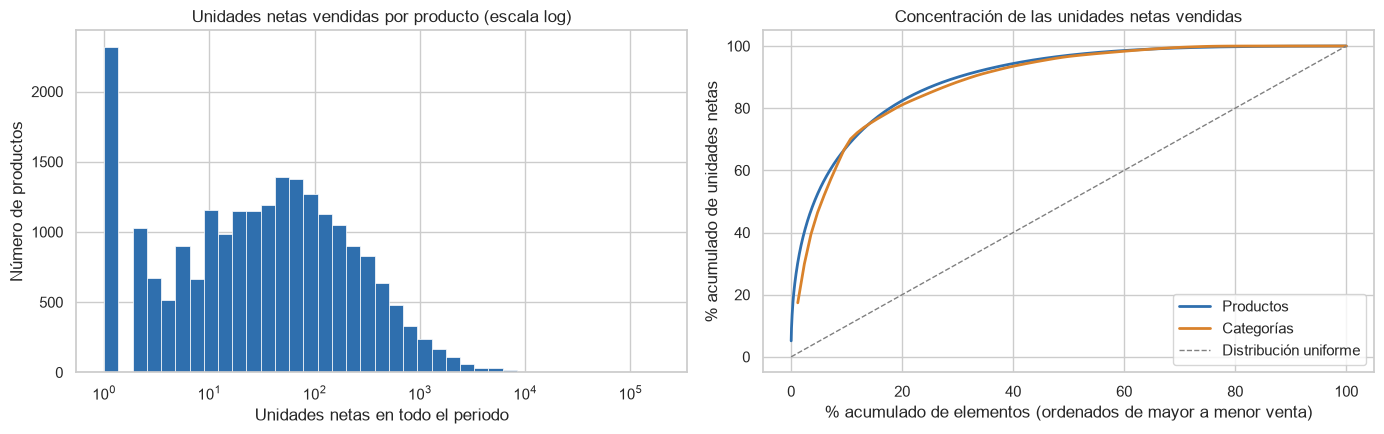

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Histograma de unidades netas por producto (escala logarítmica, solo productos con ventas netas positivas)
positivos = ventas_producto.loc[ventas_producto["unidades"] > 0, "unidades"]
bins = np.logspace(0, np.log10(positivos.max()), 40)
axes[0].hist(positivos, bins=bins, color=COLOR, edgecolor="white", linewidth=0.5)
axes[0].set_xscale("log")
axes[0].set_title("Unidades netas vendidas por producto (escala log)")
axes[0].set_xlabel("Unidades netas en todo el periodo")
axes[0].set_ylabel("Número de productos")

# Curva de concentración: % acumulado de ventas frente a % acumulado de elementos
for totales, etiqueta, color in [(ventas_producto["unidades"], "Productos", COLOR),
                                 (ventas_categoria["unidades"], "Categorías", COLOR_2)]:
    acumulado = totales.sort_values(ascending=False).cumsum() / totales.sum() * 100
    x = np.arange(1, len(acumulado) + 1) / len(acumulado) * 100
    axes[1].plot(x, acumulado.values, color=color, linewidth=2, label=etiqueta)
axes[1].plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="Distribución uniforme")
axes[1].set_title("Concentración de las unidades netas vendidas")
axes[1].set_xlabel("% acumulado de elementos (ordenados de mayor a menor venta)")
axes[1].set_ylabel("% acumulado de unidades netas")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación de la distribución por producto y categoría:**

- **Productos:** 21,807 de los 22,170 productos del catálogo tienen ventas en el train. La distribución de unidades por producto es extremadamente asimétrica: la mediana es de 33 unidades en casi tres años, pero la media es 167 y el máximo 187,642. El histograma (en escala logarítmica) muestra que la mayoría de los productos vende entre 10 y 1,000 unidades en todo el periodo, con un grupo grande de productos que vendió una sola unidad. El 30.8% de los productos vendió 10 unidades o menos, y 8 productos tienen ventas netas menores o iguales a cero (sus devoluciones igualan o superan sus ventas).
- **Concentración:** las ventas siguen un patrón tipo Pareto. El 1% de los productos concentra el 28.15% de las unidades, el 10% concentra el 67.58% y el 20% concentra el 82.43%. La curva de concentración se aleja mucho de la línea de distribución uniforme.
- **Categorías:** las 84 categorías tienen ventas, también con fuerte concentración: el 20% de las categorías reúne el 81.28% de las unidades. La mediana por categoría (9,515.5 unidades) es muy inferior a la media (43,430.95).
- **Grupos de categorías:** al agrupar por la primera parte del nombre se obtienen 20 grupos. En unidades predominan Кино (cine, 25.13%), Игры PC (juegos de PC, 18.89%), Игры (juegos de consola, 17.73%), Подарки (regalos, 16.02%) y Музыка (música, 11.27%), que juntos suman cerca del 89% de las unidades. En ingresos el reparto cambia: Игры reúne el 33.95% e Игровые консоли (consolas) el 15.54% con solo el 0.88% de las unidades, porque son productos de precio alto. Por eso la distribución por unidades y por ingresos no es la misma.
- **Implicación:** la gran mayoría de los pares tienda-producto tendrá ventas mensuales bajas o nulas, y unos pocos productos explicarán gran parte del volumen. La categoría del producto es una variable relevante para el modelo.

#### 5.b.ii Distribución por sucursal (tienda)

In [21]:
ventas_tienda = ventas.groupby("shop_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    meses_activos=("date_block_num", "nunique"),
)
ventas_tienda["unidades_por_mes_activo"] = ventas_tienda["unidades"] / ventas_tienda["meses_activos"]

print("Distribución de las ventas por tienda:")
display(ventas_tienda.describe())
cv = ventas_tienda["unidades"].std() / ventas_tienda["unidades"].mean()
print(f"Coeficiente de variación de las unidades netas por tienda: {cv:.2f}")
print("Tiendas activas los 34 meses:", (ventas_tienda["meses_activos"] == 34).sum(), "de", len(ventas_tienda))
display(resumen_concentracion(ventas_tienda["unidades"], "tiendas").to_frame().T)

# Ventas mensuales de cada tienda: distribución de todos los pares tienda-mes con actividad
mensual_tienda = ventas.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum()
print("Unidades netas por tienda y mes:")
display(mensual_tienda.describe().to_frame("unidades por tienda-mes"))

Distribución de las ventas por tienda:


,unidades,ingresos,meses_activos,unidades_por_mes_activo
count,57.00,57.00,57.00,57.00
mean,"64,003.51","59,630,227.20",27.82,"2,167.96"
std,"58,418.85","49,672,262.18",10.36,"1,672.45"
min,330.00,"377,714.00",1.00,330.00
25%,"25,838.00","27,714,110.02",25.00,"1,292.41"
50%,"53,886.00","49,792,061.50",34.00,"1,879.00"
75%,"71,201.00","70,204,774.88",34.00,"2,242.24"
max,"310,777.00","235,217,019.05",34.00,"9,140.50"


Coeficiente de variación de las unidades netas por tienda: 0.91
Tiendas activas los 34 meses: 35 de 57


,elementos,% ventas del top 1%,% ventas del top 10%,% ventas del top 20%
tiendas,57.00,8.52,33.46,46.68


Unidades netas por tienda y mes:


,unidades por tienda-mes
count,"1,586.00"
mean,"2,300.25"
std,"1,906.64"
min,-1.00
25%,"1,185.25"
50%,"1,737.50"
75%,"2,599.00"
max,"16,318.00"


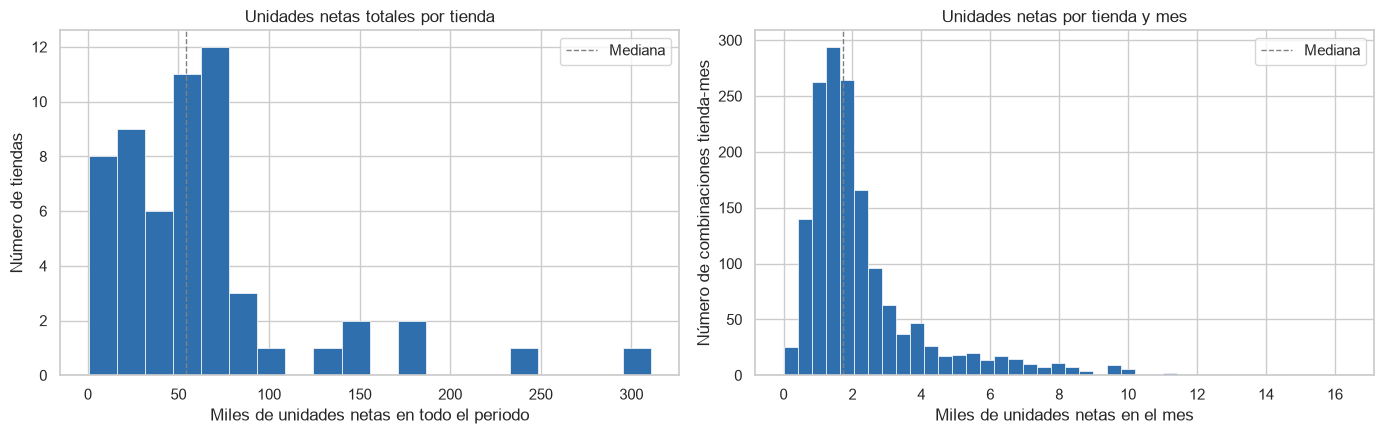

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(ventas_tienda["unidades"] / 1000, bins=20, color=COLOR, edgecolor="white", linewidth=0.5)
axes[0].axvline(ventas_tienda["unidades"].median() / 1000, color="gray", linestyle="--", linewidth=1, label="Mediana")
axes[0].set_title("Unidades netas totales por tienda")
axes[0].set_xlabel("Miles de unidades netas en todo el periodo")
axes[0].set_ylabel("Número de tiendas")
axes[0].legend()

axes[1].hist(mensual_tienda / 1000, bins=40, color=COLOR, edgecolor="white", linewidth=0.5)
axes[1].axvline(mensual_tienda.median() / 1000, color="gray", linestyle="--", linewidth=1, label="Mediana")
axes[1].set_title("Unidades netas por tienda y mes")
axes[1].set_xlabel("Miles de unidades netas en el mes")
axes[1].set_ylabel("Número de combinaciones tienda-mes")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación de la distribución por tienda:**

- Después de la limpieza quedan 57 tiendas. La mediana es de 53,886 unidades netas por tienda en todo el periodo, pero el rango es enorme: de 330 a 310,777 unidades. El coeficiente de variación (0.91) indica que las tiendas son muy heterogéneas en volumen.
- El histograma de la izquierda muestra que la mayoría de las tiendas se concentra por debajo de 100,000 unidades, con unas pocas tiendas muy grandes a la derecha. La concentración es mucho menor que en los productos: el 20% de las tiendas reúne el 46.68% de las unidades.
- Solo 35 de las 57 tiendas tienen ventas en los 34 meses; las demás abrieron o cerraron durante el periodo (la mediana de meses activos es 34, pero el mínimo es 1). Por eso los totales del periodo completo no son comparables entre todas las tiendas, y conviene mirar también las ventas por mes activo: la mediana es de 1,879 unidades por mes activo.
- El histograma de la derecha muestra las 1,586 combinaciones tienda-mes con actividad: la mediana es de 1,737.5 unidades por tienda en un mes y la distribución tiene una cola larga a la derecha, con meses que llegan a 16,318 unidades. Esa cola corresponde a tiendas grandes y a meses de ventas altas, lo que se analizará en las secciones 6 y 7.

#### 5.b.iii Distribución por periodo de tiempo (día, semana, mes y año)

In [23]:
# Ventas totales de la cadena por día, semana, mes y año
diario = ventas.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))

# Semanas de lunes a domingo; se excluyen las semanas incompletas del inicio y del final del periodo
semanal = ventas.set_index("date").resample("W-SUN").agg({"item_cnt_day": "sum", "revenue": "sum"})
dias_por_semana = ventas.set_index("date").resample("W-SUN")["date_block_num"].apply(lambda s: s.index.nunique())
semanal = semanal[dias_por_semana == 7].rename(columns={"item_cnt_day": "unidades", "revenue": "ingresos"})

mensual = ventas.groupby("date_block_num").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))

anual = ventas.groupby(ventas["date"].dt.year).agg(
    unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), meses=("date_block_num", "nunique")
)
anual["unidades_promedio_mes"] = anual["unidades"] / anual["meses"]
anual["ingresos_promedio_mes"] = anual["ingresos"] / anual["meses"]
# Comparación justa entre años: solo enero a octubre, porque 2015 termina en octubre
anual["unidades_ene_oct"] = ventas[ventas["date"].dt.month <= 10].groupby(ventas["date"].dt.year)["item_cnt_day"].sum()

print("Distribución de las unidades netas totales por periodo:")
display(pd.DataFrame({
    "por día": diario["unidades"].describe(),
    "por semana (completa)": semanal["unidades"].describe(),
    "por mes": mensual["unidades"].describe(),
}))
print("Ventas por año:")
display(anual)

Distribución de las unidades netas totales por periodo:


,por día,por semana (completa),por mes
count,"1,034.00",146.00,34.00
mean,"3,528.24","24,645.97","107,300.00"
std,"1,584.68","7,801.24","28,455.95"
min,"1,274.00","12,389.00","63,187.00"
25%,"2,472.25","19,959.25","85,968.25"
50%,"3,145.00","24,500.50","107,306.00"
75%,"4,257.00","27,672.50","125,358.50"
max,"13,343.00","57,680.00","183,342.00"


Ventas por año:


,unidades,ingresos,meses,unidades_promedio_mes,ingresos_promedio_mes,unidades_ene_oct
date,,,,,,
2013,"1,562,732.00","1,217,525,834.98",12,"130,227.67","101,460,486.25","1,249,381.00"
2014,"1,320,884.00","1,346,773,983.81",12,"110,073.67","112,231,165.32","1,034,285.00"
2015,"764,584.00","834,623,131.78",10,"76,458.40","83,462,313.18","764,584.00"


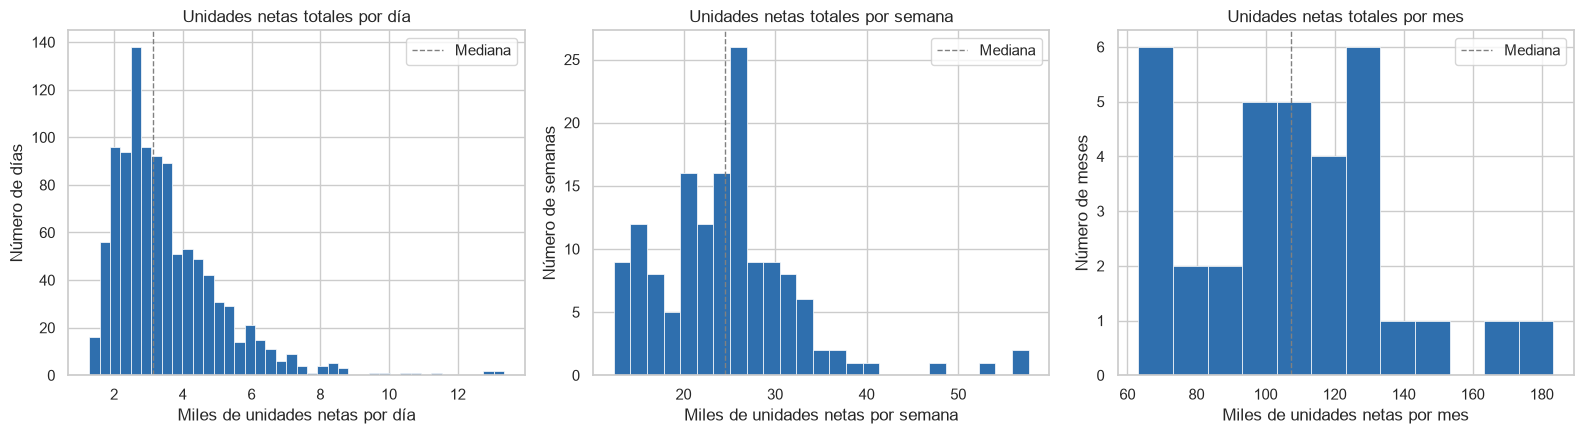

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
periodos = [(diario["unidades"], "día", 40), (semanal["unidades"], "semana", 25), (mensual["unidades"], "mes", 12)]

for ax, (serie, nombre, bins) in zip(axes, periodos):
    ax.hist(serie / 1000, bins=bins, color=COLOR, edgecolor="white", linewidth=0.5)
    ax.axvline(serie.median() / 1000, color="gray", linestyle="--", linewidth=1, label="Mediana")
    ax.set_title(f"Unidades netas totales por {nombre}")
    ax.set_xlabel(f"Miles de unidades netas por {nombre}")
    ax.set_ylabel(f"Número de {'días' if nombre == 'día' else nombre + 's' if nombre == 'semana' else 'meses'}")
    ax.legend()

plt.tight_layout()
plt.show()

**Interpretación de la distribución por periodo de tiempo:**

- **Por día:** la cadena vende una mediana de 3,145 unidades netas diarias (media de 3,528), con un rango de 1,274 a 13,343. La distribución tiene sesgo a la derecha: la mayoría de los días se ubica entre 2,000 y 5,000 unidades, y unos pocos días superan las 8,000. El día de mayor venta multiplica por más de 4 a la mediana, lo que sugiere picos asociados a fechas especiales (se analiza en la sección 6).
- **Por semana:** en las 146 semanas completas la mediana es de 24,500 unidades. Al agregar por semana la variabilidad relativa baja (desviación de 7,801 frente a una media de 24,646), pero siguen existiendo semanas atípicas por encima de 45,000 unidades.
- **Por mes:** los 34 meses tienen una mediana de 107,306 unidades, con un mínimo de 63,187 y un máximo de 183,342. Con solo 34 observaciones el histograma es disperso, pero muestra meses con ventas muy por encima del resto, compatibles con temporadas de alta demanda.
- **Por año:** las unidades vendidas disminuyen año con año. Comparando el mismo periodo (enero a octubre), se pasa de 1,249,381 unidades en 2013 a 1,034,285 en 2014 (-17.2%) y a 764,584 en 2015 (-26.1%). El promedio mensual también cae (130,228, 110,074 y 76,458). En cambio, los ingresos de 2014 fueron mayores que los de 2013, aunque se vendieron menos unidades, lo que indica un aumento del precio promedio; en 2015 caen tanto las unidades como los ingresos.
- **Implicación:** las ventas no son estables en el tiempo: hay una tendencia a la baja en volumen y meses con picos marcados. Ambos aspectos (tendencia y estacionalidad) se estudian en la sección 6.

## 6. Exploración temporal

### 6.a Evolución de las ventas a lo largo del tiempo

Para el análisis se usa la serie diaria de unidades netas de toda la cadena (sin días faltantes, sección 3.c), suavizada con medias móviles de 7 y 30 días, junto con la serie mensual de unidades e ingresos en paneles separados. La versión final y limpia de la serie de tiempo total se presenta en la sección 8.a.

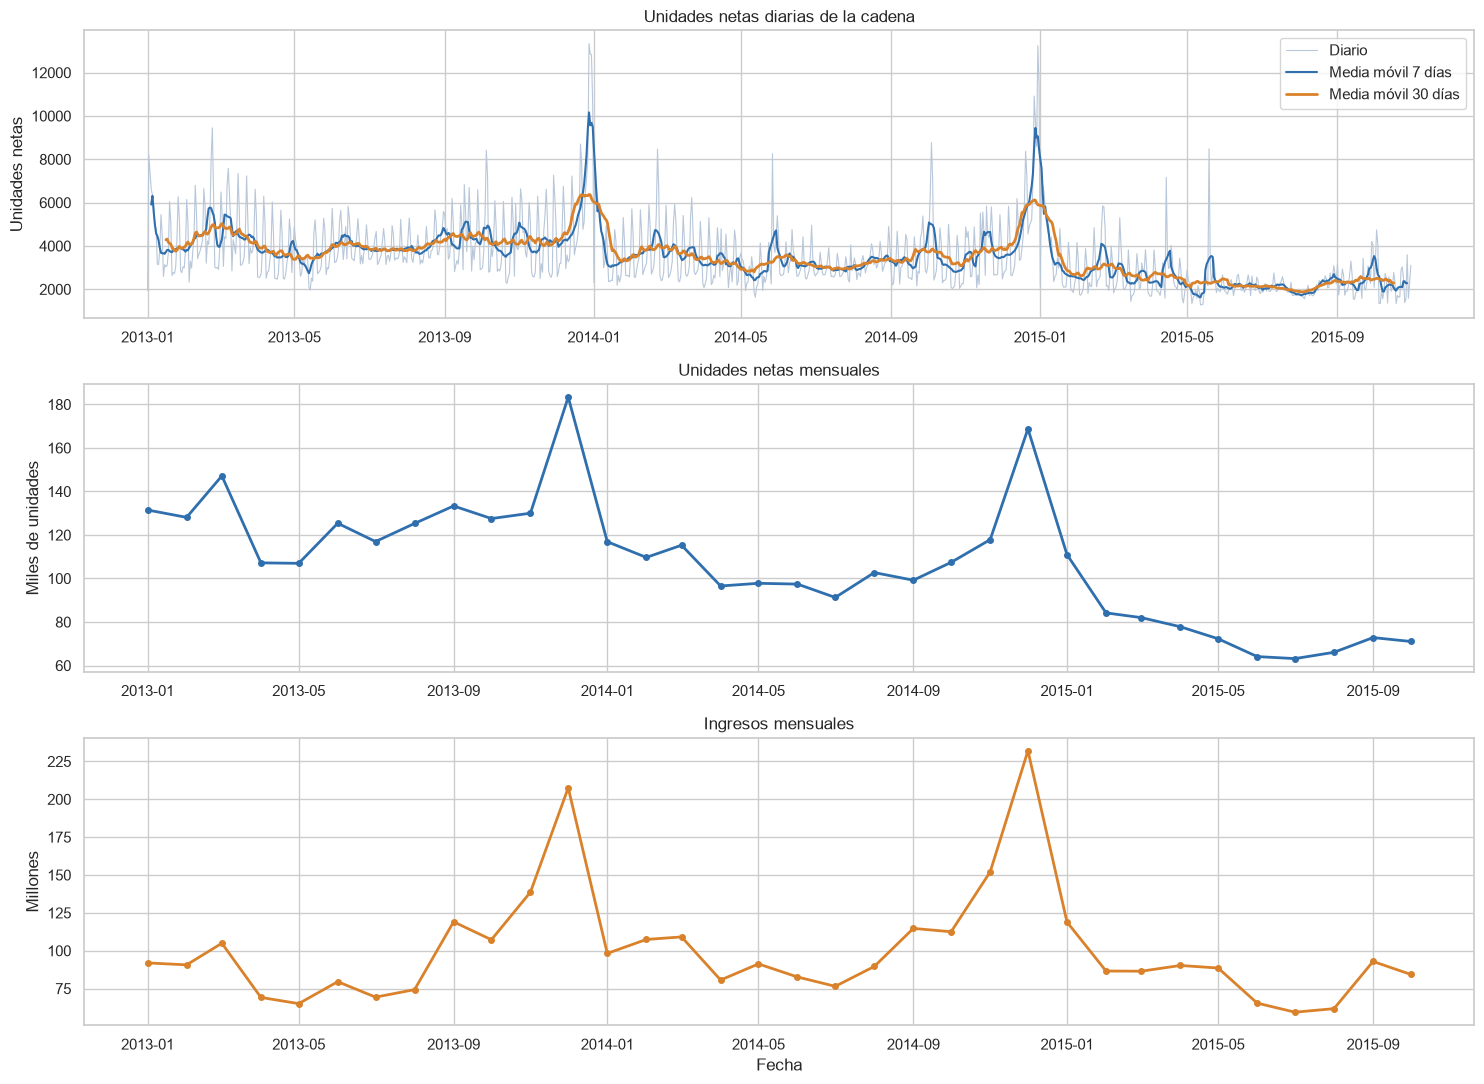

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=False)

# Panel 1: serie diaria con medias móviles
axes[0].plot(diario.index, diario["unidades"], color="#b8c7d9", linewidth=0.8, label="Diario")
axes[0].plot(diario.index, diario["unidades"].rolling(7, center=True).mean(), color=COLOR, linewidth=1.5, label="Media móvil 7 días")
axes[0].plot(diario.index, diario["unidades"].rolling(30, center=True).mean(), color=COLOR_2, linewidth=2, label="Media móvil 30 días")
axes[0].set_title("Unidades netas diarias de la cadena")
axes[0].set_ylabel("Unidades netas")
axes[0].legend(loc="upper right")

# Panel 2 y 3: series mensuales (unidades e ingresos en ejes separados, no en doble eje)
fechas_mes = pd.date_range("2013-01-01", periods=len(mensual), freq="MS")
axes[1].plot(fechas_mes, mensual["unidades"] / 1000, color=COLOR, linewidth=2, marker="o", markersize=4)
axes[1].set_title("Unidades netas mensuales")
axes[1].set_ylabel("Miles de unidades")
axes[2].plot(fechas_mes, mensual["ingresos"] / 1e6, color=COLOR_2, linewidth=2, marker="o", markersize=4)
axes[2].set_title("Ingresos mensuales")
axes[2].set_ylabel("Millones")
axes[2].set_xlabel("Fecha")

plt.tight_layout()
plt.show()

**Interpretación de la evolución de las ventas:**

- La serie diaria es muy ruidosa y muestra un patrón en forma de "sierra" con oscilaciones cortas y regulares, que sugiere un ciclo semanal (se verifica en 6.b.iv). Las medias móviles de 7 y 30 días eliminan ese ruido y dejan ver dos rasgos claros: un **nivel que va bajando** a lo largo del periodo y **picos muy marcados a fin de año**.
- La media móvil de 30 días pasa de alrededor de 4,000 a 4,500 unidades diarias en 2013 a cerca de 2,000 a 2,500 en 2015.
- En la serie mensual las unidades bajan de niveles de 110,000 a 145,000 en 2013 a 63,000 a 73,000 en los meses de mitad de 2015. Los dos meses más altos son diciembre de 2013 (unos 183,000) y diciembre de 2014 (unos 169,000).
- Los ingresos tienen la misma forma con picos en diciembre, pero su caída es menos pronunciada que la de las unidades: el pico de diciembre de 2014 es incluso mayor que el de 2013. Esto coincide con el aumento del precio promedio observado en la sección 5.b.iii.

### 6.b Patrones temporales

#### 6.b.i Tendencia

Para separar la tendencia de la estacionalidad se aplica una descomposición aditiva clásica a la serie mensual de unidades netas con periodo 12 (un año), y se ajusta además una recta de regresión lineal para cuantificar la pendiente.

Pendiente de la tendencia lineal: -1,944 unidades netas por mes
Cambio anual estimado: -23,322 unidades netas por año
Componente de tendencia: de 129,620 (2013-07) a 89,114 (2015-04), variación de -31.3%


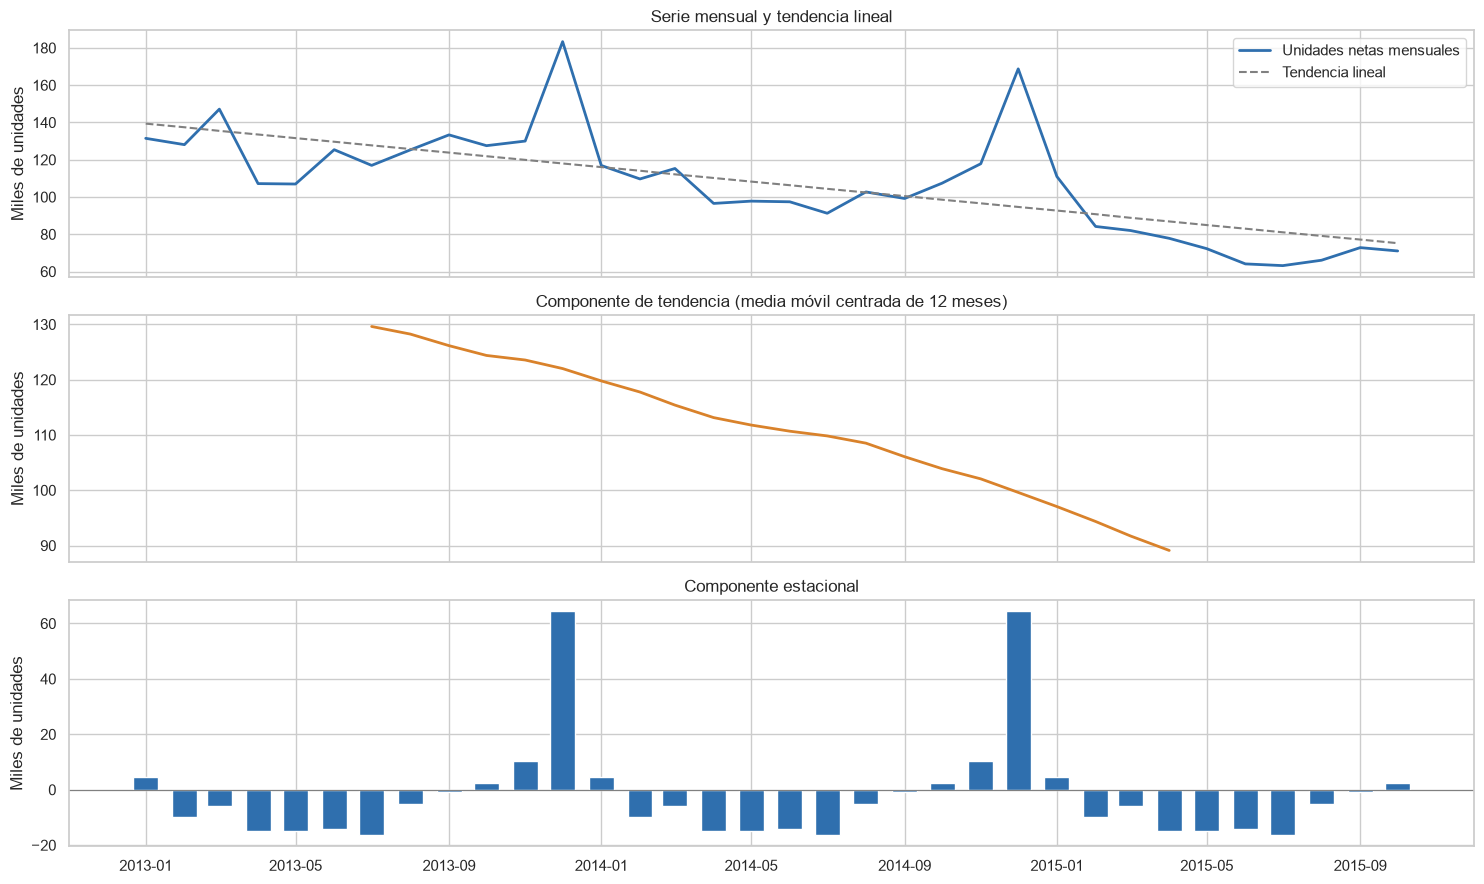

In [26]:
from statsmodels.tsa.seasonal import seasonal_decompose

serie_mensual = pd.Series(mensual["unidades"].values, index=fechas_mes, name="unidades")
descomposicion = seasonal_decompose(serie_mensual, model="additive", period=12)

# Pendiente de la tendencia lineal (unidades por mes)
x = np.arange(len(serie_mensual))
pendiente, intercepto = np.polyfit(x, serie_mensual.values, 1)
print(f"Pendiente de la tendencia lineal: {pendiente:,.0f} unidades netas por mes")
print(f"Cambio anual estimado: {pendiente * 12:,.0f} unidades netas por año")

tendencia = descomposicion.trend.dropna()
print(f"Componente de tendencia: de {tendencia.iloc[0]:,.0f} ({tendencia.index[0]:%Y-%m}) "
      f"a {tendencia.iloc[-1]:,.0f} ({tendencia.index[-1]:%Y-%m}), "
      f"variación de {(tendencia.iloc[-1] / tendencia.iloc[0] - 1) * 100:.1f}%")

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
axes[0].plot(serie_mensual.index, serie_mensual / 1000, color=COLOR, linewidth=2, label="Unidades netas mensuales")
axes[0].plot(serie_mensual.index, (intercepto + pendiente * x) / 1000, color="gray", linestyle="--", linewidth=1.5, label="Tendencia lineal")
axes[0].set_title("Serie mensual y tendencia lineal")
axes[0].set_ylabel("Miles de unidades")
axes[0].legend()
axes[1].plot(descomposicion.trend.index, descomposicion.trend / 1000, color=COLOR_2, linewidth=2)
axes[1].set_title("Componente de tendencia (media móvil centrada de 12 meses)")
axes[1].set_ylabel("Miles de unidades")
axes[2].bar(descomposicion.seasonal.index, descomposicion.seasonal / 1000, width=20, color=COLOR)
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_title("Componente estacional")
axes[2].set_ylabel("Miles de unidades")
plt.tight_layout()
plt.show()

**Interpretación de la tendencia:**

- Las ventas en unidades tienen una **tendencia decreciente clara y sostenida**. La recta de regresión tiene una pendiente de -1,944 unidades netas por mes, es decir, unas 23,300 unidades menos cada año.
- El componente de tendencia de la descomposición, que elimina el efecto estacional, baja de forma casi continua de 129,620 unidades (julio de 2013) a 89,114 (abril de 2015), una caída del 31.3%. No aparece ningún periodo de recuperación: la caída incluso se acelera desde finales de 2014.
- Para el modelo de forecasting esto significa que la serie **no es estacionaria en media**: el nivel de noviembre de 2015 debería ser menor que el de noviembre de los años anteriores, y el modelo necesita capturar esta tendencia (por ejemplo, con variables de rezago recientes o de tiempo).

#### 6.b.ii Estacionalidad

,unidades 2013,unidades 2014,unidades 2015,índice 2013,índice 2014,componente estacional
1,"131,478.00","116,899.00","110,971.00",1.01,1.06,"4,674.27"
2,"128,090.00","109,686.00","84,198.00",0.98,1.00,"-9,964.75"
3,"147,142.00","115,296.00","82,014.00",1.13,1.05,"-5,757.98"
4,"107,190.00","96,556.00","77,827.00",0.82,0.88,"-14,784.52"
5,"106,970.00","97,789.00","72,295.00",0.82,0.89,"-14,855.63"
6,"125,381.00","97,429.00","64,114.00",0.96,0.89,"-14,100.96"
7,"116,966.00","91,279.00","63,187.00",0.90,0.83,"-16,449.40"
8,"125,291.00","102,721.00","66,079.00",0.96,0.93,"-5,224.25"
9,"133,332.00","99,208.00","72,843.00",1.02,0.90,-689.00
10,"127,541.00","107,422.00","71,056.00",0.98,0.98,"2,491.06"


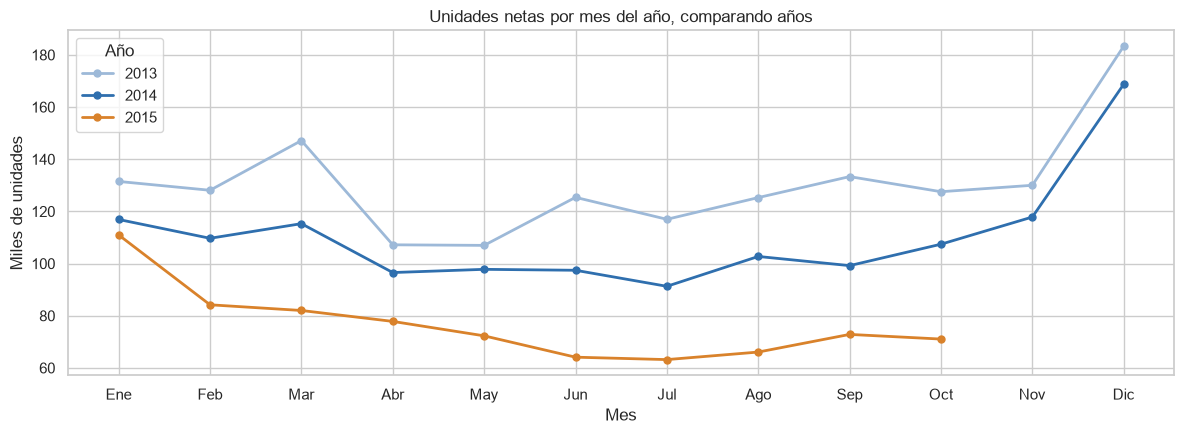

In [27]:
# Gráfico estacional: unidades netas por mes del año, una línea por año
mensual_anio = pd.DataFrame({
    "anio": fechas_mes.year, "mes": fechas_mes.month, "unidades": mensual["unidades"].values
})
tabla_estacional = mensual_anio.pivot(index="mes", columns="anio", values="unidades")

# Índice estacional: ventas del mes divididas entre el promedio mensual de su año (solo años completos 2013 y 2014)
indice_estacional = tabla_estacional[[2013, 2014]] / tabla_estacional[[2013, 2014]].mean()

# Componente estacional de la descomposición (un valor por mes del año)
componente = descomposicion.seasonal.groupby(descomposicion.seasonal.index.month).first()

resumen_estacional = pd.DataFrame({
    "unidades 2013": tabla_estacional[2013],
    "unidades 2014": tabla_estacional[2014],
    "unidades 2015": tabla_estacional[2015],
    "índice 2013": indice_estacional[2013],
    "índice 2014": indice_estacional[2014],
    "componente estacional": componente,
})
display(resumen_estacional)

fig, ax = plt.subplots(figsize=(12, 4.5))
colores_anio = {2013: "#9db9d8", 2014: COLOR, 2015: COLOR_2}
for anio in [2013, 2014, 2015]:
    ax.plot(tabla_estacional.index, tabla_estacional[anio] / 1000, marker="o", markersize=5,
            linewidth=2, color=colores_anio[anio], label=str(anio))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Unidades netas por mes del año, comparando años")
ax.set_xlabel("Mes")
ax.set_ylabel("Miles de unidades")
ax.legend(title="Año")
plt.tight_layout()
plt.show()

**Interpretación de la estacionalidad:**

- Existe una **estacionalidad anual muy marcada y repetitiva**. Diciembre es, por mucho, el mes de mayores ventas en ambos años completos: 183,342 unidades en 2013 y 168,754 en 2014, es decir, un 41% y un 53% por encima del promedio mensual de su año (índices de 1.41 y 1.53). El componente estacional de diciembre es de +64,390 unidades sobre la tendencia.
- **Noviembre**, el mes que se debe predecir, también está por encima del promedio (índices de 1.00 en 2013 y 1.07 en 2014; componente estacional de +10,271) y supera a octubre en ambos años: +1.9% en 2013 y +9.7% en 2014. Es el inicio de la temporada alta de fin de año.
- Los meses más débiles son de abril a julio (componente estacional entre -14,000 y -16,500 unidades e índices entre 0.82 y 0.90), es decir, el segundo y tercer trimestre. Enero y marzo muestran valores relativamente altos.
- Las curvas de los tres años tienen una forma parecida pero están desplazadas hacia abajo cada año, lo que confirma que la estacionalidad se suma a la tendencia decreciente. En 2015 el patrón se ve más plano, con una caída fuerte desde enero.

#### 6.b.iii Picos o caídas abruptas

In [28]:
dias_semana = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

# Días con ventas más altas y más bajas
extremos = diario[["unidades"]].copy()
extremos["día_semana"] = [dias_semana[d] for d in extremos.index.dayofweek]
# Relación con la mediana de los 30 días alrededor, para medir qué tan anómalo es el día frente a su contexto
extremos["mediana_30d"] = diario["unidades"].rolling(30, center=True, min_periods=15).median()
extremos["veces_mediana_30d"] = extremos["unidades"] / extremos["mediana_30d"]

print("Días con mayores ventas:")
display(extremos.sort_values("unidades", ascending=False).head(10))
print("Días con menores ventas:")
display(extremos.sort_values("unidades").head(5))
print("Días que superan 2 veces la mediana de su entorno de 30 días:", (extremos["veces_mediana_30d"] > 2).sum())
display(extremos[extremos["veces_mediana_30d"] > 2].sort_values("veces_mediana_30d", ascending=False))

# Cambios mensuales más abruptos
cambio_mensual = serie_mensual.pct_change() * 100
print("Mayores cambios porcentuales de un mes al siguiente:")
display(cambio_mensual.dropna().sort_values(key=abs, ascending=False).head(6).to_frame("cambio_%"))

Días con mayores ventas:


,unidades,día_semana,mediana_30d,veces_mediana_30d
date,,,,
2013-12-28,"13,343.00",Sábado,"5,587.00",2.39
2014-12-30,"13,236.00",Martes,"5,069.00",2.61
2013-12-29,"12,863.00",Domingo,"5,587.00",2.30
2013-12-30,"12,823.00",Lunes,"5,334.50",2.40
2014-12-31,"11,393.00",Miércoles,"5,069.00",2.25
2014-12-27,"10,919.00",Sábado,"5,148.50",2.12
2013-12-31,"10,514.00",Martes,"5,203.00",2.02
2014-12-28,"9,727.00",Domingo,"5,148.50",1.89
2013-02-23,"9,456.00",Sábado,"4,382.00",2.16


Días con menores ventas:


,unidades,día_semana,mediana_30d,veces_mediana_30d
date,,,,
2015-05-12,"1,274.00",Martes,"2,025.00",0.63
2015-05-13,"1,294.00",Miércoles,"2,025.00",0.64
2015-05-14,"1,302.00",Jueves,"2,025.00",0.64
2015-10-05,"1,340.00",Lunes,"2,284.50",0.59
2015-10-19,"1,341.00",Lunes,"2,032.50",0.66


Días que superan 2 veces la mediana de su entorno de 30 días: 19


,unidades,día_semana,mediana_30d,veces_mediana_30d
date,,,,
2015-05-19,"8,483.00",Martes,"1,981.00",4.28
2015-04-14,"7,158.00",Martes,"2,224.50",3.22
2014-05-27,"8,256.00",Martes,"2,885.50",2.86
2014-12-30,"13,236.00",Martes,"5,069.00",2.61
2014-10-04,"8,767.00",Sábado,"3,442.50",2.55
2014-02-22,"8,472.00",Sábado,"3,373.00",2.51
2013-12-30,"12,823.00",Lunes,"5,334.50",2.40
2013-12-28,"13,343.00",Sábado,"5,587.00",2.39
2013-12-29,"12,863.00",Domingo,"5,587.00",2.30


Mayores cambios porcentuales de un mes al siguiente:


,cambio_%
2014-12-01,43.20
2013-12-01,41.02
2014-01-01,-36.24
2015-01-01,-34.24
2013-04-01,-27.15
2015-02-01,-24.13


In [29]:
# Para entender los picos fuera de diciembre: producto más vendido en cada uno de los días más anómalos
dias_revisar = ["2015-05-19", "2015-04-14", "2014-05-27", "2014-10-04", "2014-02-22"]
filas = []
for dia in pd.to_datetime(dias_revisar):
    del_dia = ventas[ventas["date"] == dia]
    top = del_dia.groupby("item_id")["item_cnt_day"].sum().sort_values(ascending=False)
    filas.append({
        "fecha": dia.date(),
        "unidades_del_día": del_dia["item_cnt_day"].sum(),
        "item_id_top": top.index[0],
        "item_name_top": items.set_index("item_id").loc[top.index[0], "item_name"],
        "unidades_item_top": top.iloc[0],
        "% del día": top.iloc[0] / del_dia["item_cnt_day"].sum() * 100,
        "tiendas_con_ventas": del_dia["shop_id"].nunique(),
    })
display(pd.DataFrame(filas))

,fecha,unidades_del_día,item_id_top,item_name_top,unidades_item_top,% del día,tiendas_con_ventas
0,2015-05-19,"8,483.00",10209,"Ведьмак 3: Дикая охота [PC, русская версия]","2,005.00",23.64,44
1,2015-04-14,"7,158.00",3731,"Grand Theft Auto V [PC, русские субтитры]","3,825.00",53.44,44
2,2014-05-27,"8,256.00",7807,"Watch_Dogs. Специальное издание [PS4, русская ...","1,426.00",17.27,49
3,2014-10-04,"8,767.00",19437,"Средиземье: Тени Мордора [PC, Цифровая версия]",401.00,4.57,51
4,2014-02-22,"8,472.00",20949,Фирменный пакет майка 1С Интерес белый (34*42)...,506.00,5.97,46


**Interpretación de picos y caídas abruptas:**

- **Picos de fin de año:** los días de mayores ventas de todo el periodo están entre el 27 y el 31 de diciembre de 2013 y 2014, con más de 10,000 unidades diarias (máximo de 13,343 el 28 de diciembre de 2013), entre 2 y 2.6 veces la mediana de su entorno. Corresponden a las compras previas al Año Nuevo, que en Rusia es la principal fecha de regalos.
- **Picos por fechas festivas:** aparecen picos el 22 y 23 de febrero (alrededor del Día del Defensor de la Patria, 23 de febrero) y el 7 de marzo de 2015 (víspera del Día Internacional de la Mujer, 8 de marzo), ambas fechas de regalos en Rusia.
- **Picos por lanzamientos de videojuegos:** los días más anómalos frente a su entorno son martes que no coinciden con festividades. El 19 de mayo de 2015 (4.28 veces la mediana) el producto más vendido fue "Ведьмак 3" (The Witcher 3, PC), con el 23.6% de las unidades del día; el 14 de abril de 2015 fue "Grand Theft Auto V" para PC, con el 53.4% de las unidades del día; y el 27 de mayo de 2014 fue "Watch_Dogs" para PS4. Es decir, un solo lanzamiento puede duplicar o cuadruplicar las ventas de un día.
- **Caídas:** los días de menores ventas (alrededor de 1,300 unidades) son de mayo y octubre de 2015, al final de la tendencia decreciente; no son caídas aisladas sino el nivel más bajo de la serie.
- **Cambios mensuales abruptos:** los mayores saltos son las subidas de noviembre a diciembre (+43.2% en 2014 y +41.0% en 2013) y las caídas de diciembre a enero (-36.2% en 2014 y -34.2% en 2015). También destaca la caída de marzo a abril de 2013 (-27.2%) y la de enero a febrero de 2015 (-24.1%).
- **Implicación:** estos picos son eventos reales (festividades y lanzamientos) y no errores, por lo que no deben eliminarse de la serie; sin embargo, sí explican parte de los valores extremos que se revisan en la sección 7.c.

#### 6.b.iv Ciclos por días de la semana y por meses del año

Unidades netas diarias por día de la semana:


,mean,median,count,índice_vs_promedio
día_semana,,,,
Lunes,"2,731.20","2,581.00",147,0.77
Martes,"3,074.22","2,659.00",148,0.87
Miércoles,"2,971.03","2,769.50",148,0.84
Jueves,"3,071.77","2,925.50",148,0.87
Viernes,"3,739.56","3,605.00",148,1.06
Sábado,"4,963.82","4,911.00",148,1.41
Domingo,"4,144.84","4,115.00",147,1.17


Unidades netas diarias promedio por mes del año (todo el periodo):


,mean,count,índice_vs_promedio
mes,,,
1,"3,863.96",93,1.10
2,"3,833.02",84,1.09
3,"3,703.78",93,1.05
4,"3,128.59",90,0.89
5,"2,979.08",93,0.84
6,"3,188.04",90,0.90
7,"2,918.62",93,0.83
8,"3,162.27",93,0.90
9,"3,393.14",90,0.96


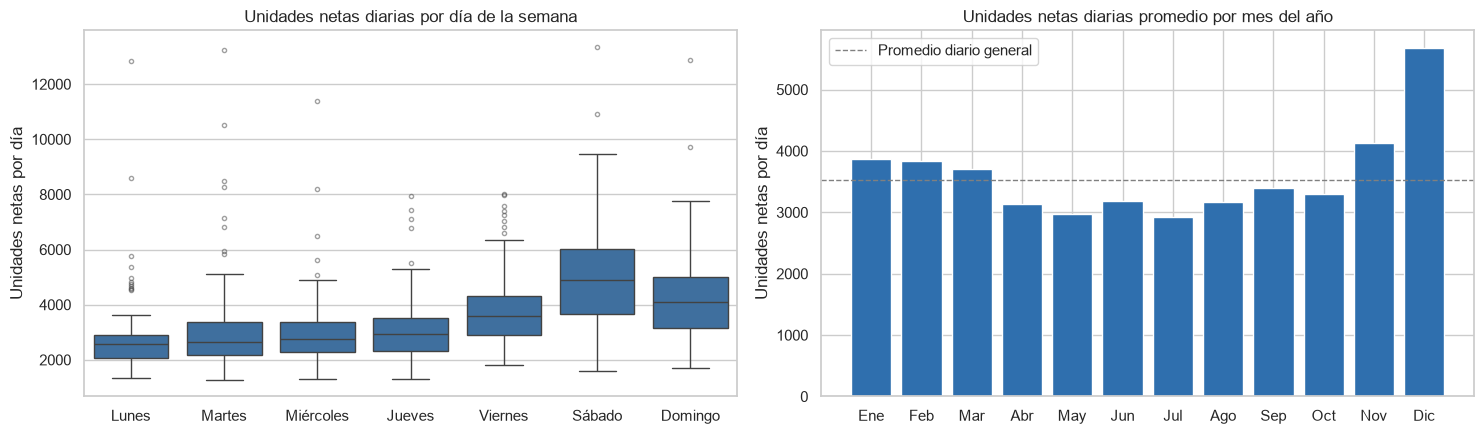

In [30]:
# Ciclo semanal: unidades netas diarias según el día de la semana
diario_semana = diario[["unidades"]].copy()
diario_semana["día_semana"] = pd.Categorical([dias_semana[d] for d in diario.index.dayofweek], categories=dias_semana, ordered=True)
por_dia_semana = diario_semana.groupby("día_semana", observed=True)["unidades"].agg(["mean", "median", "count"])
por_dia_semana["índice_vs_promedio"] = por_dia_semana["mean"] / diario["unidades"].mean()
print("Unidades netas diarias por día de la semana:")
display(por_dia_semana)

# Ciclo anual: promedio de unidades diarias según el mes del año (se divide entre los días para no favorecer meses largos)
diario_mes = diario[["unidades"]].copy()
diario_mes["mes"] = diario.index.month
por_mes_anio = diario_mes.groupby("mes")["unidades"].agg(["mean", "count"])
por_mes_anio["índice_vs_promedio"] = por_mes_anio["mean"] / diario["unidades"].mean()
print("Unidades netas diarias promedio por mes del año (todo el periodo):")
display(por_mes_anio)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=diario_semana, x="día_semana", y="unidades", color=COLOR, ax=axes[0],
            showfliers=True, flierprops={"markersize": 3, "alpha": 0.5}, linewidth=1)
axes[0].set_title("Unidades netas diarias por día de la semana")
axes[0].set_xlabel("")
axes[0].set_ylabel("Unidades netas por día")

meses_nombre = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
axes[1].bar(meses_nombre, por_mes_anio["mean"], color=COLOR, edgecolor="white")
axes[1].axhline(diario["unidades"].mean(), color="gray", linestyle="--", linewidth=1, label="Promedio diario general")
axes[1].set_title("Unidades netas diarias promedio por mes del año")
axes[1].set_ylabel("Unidades netas por día")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación de los ciclos semanales y anuales:**

- **Ciclo semanal:** existe un ciclo semanal claro y estable. Las ventas se concentran en el fin de semana: el sábado es el día más fuerte (promedio de 4,964 unidades, 41% por encima del promedio diario) seguido del domingo (+17%) y el viernes (+6%). De lunes a jueves las ventas están entre 13% y 23% por debajo del promedio, con el lunes como el día más débil. Esto explica el patrón de "sierra" de la serie diaria en 6.a. Los puntos atípicos de cada día corresponden a los picos de fin de año, festividades y lanzamientos identificados en 6.b.iii.
- **Ciclo anual:** el promedio de unidades diarias por mes del año confirma la estacionalidad de 6.b.ii: diciembre (5,679 unidades diarias, índice de 1.61) y noviembre (índice de 1.17) son los meses más altos, seguidos de enero a marzo; de abril a octubre las ventas están por debajo del promedio, con mayo y julio como los meses más bajos (índices de 0.84 y 0.83). Hay que considerar que noviembre y diciembre solo tienen datos de 2013 y 2014, años con un nivel de ventas más alto que 2015, por lo que su índice está algo inflado por la tendencia; aun así, el gráfico estacional de 6.b.ii muestra que su ventaja se mantiene dentro de cada año.
- **Implicación para el modelo:** como la predicción es mensual, el ciclo semanal se diluye al agregar por mes, aunque el número de fines de semana de cada mes puede influir ligeramente en su total. El ciclo anual sí es determinante: el modelo debe incorporar el mes del año o rezagos de 12 meses para capturar que noviembre es un mes de ventas superiores a octubre.

## 7. Análisis comparativo entre sucursales y productos

### 7.a Productos y categorías más y menos vendidos

El criterio principal es el de unidades netas vendidas en todo el periodo (base de la variable objetivo); como complemento se muestran los productos con mayores ingresos.

In [31]:
# Tabla por producto con su nombre, categoría y primer mes de venta
nombres_item = items.set_index("item_id")["item_name"]
cat_item = items.set_index("item_id")["item_category_id"]
nombres_cat = item_categories.set_index("item_category_id")["item_category_name"]

productos = ventas.groupby("item_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    primer_mes=("date_block_num", "min"),
    meses_con_venta=("date_block_num", "nunique"),
    tiendas=("shop_id", "nunique"),
)
productos["item_name"] = nombres_item.reindex(productos.index).str.slice(0, 55)
productos["categoría"] = nombres_cat.reindex(cat_item.reindex(productos.index)).values
productos["% unidades"] = productos["unidades"] / productos["unidades"].sum() * 100

columnas = ["item_name", "categoría", "unidades", "% unidades", "ingresos", "meses_con_venta", "tiendas"]
print("Top 10 productos más vendidos (unidades netas):")
display(productos.sort_values("unidades", ascending=False).head(10)[columnas])
print("Top 10 productos con mayores ingresos:")
display(productos.sort_values("ingresos", ascending=False).head(10)[columnas])

Top 10 productos más vendidos (unidades netas):


,item_name,categoría,unidades,% unidades,ingresos,meses_con_venta,tiendas
item_id,,,,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642.00",5.14,"928,863.70",31,52
2808,"Diablo III [PC, Jewel, русская версия]",Игры PC - Стандартные издания,"17,245.00",0.47,"16,852,778.42",34,55
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642.00",0.46,"43,617,975.48",26,52
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00",0.43,"17,200,825.93",34,51
5822,Playstation Store пополнение бумажника: Карта ...,Карты оплаты - PSN,"14,515.00",0.40,"15,408,983.12",34,55
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688.00",0.32,"31,065,160.27",26,51
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,"10,289.00",0.28,"219,391,488.92",24,51
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099.00",0.28,"19,983,482.89",7,43
1855,"Battlefield 4 [PC, русская версия]",Игры PC - Стандартные издания,"10,032.00",0.27,"9,357,024.78",24,51


Top 10 productos con mayores ingresos:


,item_name,categoría,unidades,% unidades,ingresos,meses_con_venta,tiendas
item_id,,,,,,,
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,"10,289.00",0.28,"219,391,488.92",24,51
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642.00",0.46,"43,617,975.48",26,52
13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...,Игровые консоли - PS4,"1,366.00",0.04,"34,331,245.28",9,48
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688.00",0.32,"31,065,160.27",26,51
3733,"Grand Theft Auto V [PS4, русские субтитры]",Игры - PS4,"6,506.00",0.18,"22,298,864.36",12,50
16787,"Одни из нас [PS3, русская версия]",Игры - PS3,"9,227.00",0.25,"21,907,839.08",29,52
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099.00",0.28,"19,983,482.89",7,43
13405,"Комплект ""Microsoft Xbox One 500GB (Day One Ed...",Игровые консоли - XBOX ONE,991.00,0.03,"18,125,479.52",14,49
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00",0.43,"17,200,825.93",34,51


In [32]:
# Productos menos vendidos: primero se cuantifican los casos que hacen inútil un ranking simple
print("Productos del catálogo sin ninguna venta en el train:", len(items) - len(productos))
print("Productos con ventas netas <= 0:", (productos["unidades"] <= 0).sum())
print("Productos con exactamente 1 unidad neta:", (productos["unidades"] == 1).sum())
print("Productos con 2 a 5 unidades netas:", productos["unidades"].between(2, 5).sum())

print("\nProductos con ventas netas <= 0 (sus devoluciones igualan o superan sus ventas):")
display(productos[productos["unidades"] <= 0].sort_values("unidades")[["item_name", "categoría", "unidades", "ingresos", "meses_con_venta"]])

# Criterio de "menos vendidos": productos con al menos 12 meses de permanencia posible en el periodo
# (primera venta en el mes 21 o antes) y con 1 unidad neta o menos en todo ese tiempo.
# Así se excluyen los productos nuevos, que venden poco solo porque llevan poco tiempo a la venta.
productos["meses_disponibles"] = 33 - productos["primer_mes"] + 1
antiguos = productos[productos["meses_disponibles"] >= 12]
menos_vendidos = antiguos[antiguos["unidades"] <= 1]
print(f"\nProductos con al menos 12 meses disponibles: {len(antiguos):,}")
print(f"Productos menos vendidos según el criterio (<= 1 unidad neta en 12 meses o más): {len(menos_vendidos):,} "
      f"({len(menos_vendidos) / len(antiguos) * 100:.1f}% de los productos con 12 meses o más)")

# Categorías donde se concentran los productos menos vendidos
comp = menos_vendidos.groupby("categoría").size().to_frame("productos_menos_vendidos")
comp["productos_antiguos_en_categoría"] = antiguos.groupby("categoría").size().reindex(comp.index)
comp["% de la categoría"] = comp["productos_menos_vendidos"] / comp["productos_antiguos_en_categoría"] * 100
print("Categorías con más productos menos vendidos:")
display(comp.sort_values("productos_menos_vendidos", ascending=False).head(10))

Productos del catálogo sin ninguna venta en el train: 363
Productos con ventas netas <= 0: 8
Productos con exactamente 1 unidad neta: 2319
Productos con 2 a 5 unidades netas: 2688

Productos con ventas netas <= 0 (sus devoluciones igualan o superan sus ventas):


,item_name,categoría,unidades,ingresos,meses_con_venta
item_id,,,,,
1590,"Assassin’s Creed 3. Freedom Edition [PC, русск...",Игры PC - Коллекционные издания,-11.00,"-28,589.00",4
18062,Робопет Собака,"Подарки - Гаджеты, роботы, спорт",-1.00,"-4,999.00",1
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...,Игровые консоли - PS3,-1.00,"-10,398.00",1
11871,Змея,"Подарки - Гаджеты, роботы, спорт",-1.00,"-5,999.00",1
8515,Английский язык. 2 - 5 класс (Jewel),Программы - Обучающие,0.00,14.90,1
7547,VideoStudio Pro X6 IE Windows Mini-Box,Программы - Для дома и офиса,0.00,0.00,1
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Музыка - Музыкальное видео,0.00,0.00,1
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...,Игровые консоли - PS3,0.00,"-7,592.00",2



Productos con al menos 12 meses disponibles: 18,575
Productos menos vendidos según el criterio (<= 1 unidad neta en 12 meses o más): 1,717 (9.2% de los productos con 12 meses o más)
Categorías con más productos menos vendidos:


,productos_menos_vendidos,productos_antiguos_en_categoría,% de la categoría
categoría,,,
Кино - DVD,270,4355,6.20
Музыка - CD локального производства,183,2152,8.50
Музыка - CD фирменного производства,149,368,40.49
Игры PC - Стандартные издания,86,724,11.88
Игры PC - Цифра,77,898,8.57
Подарки - Фигурки,69,448,15.40
Игры - PS3,63,575,10.96
Музыка - Винил,53,580,9.14
Программы - Для дома и офиса (Цифра),52,238,21.85


In [33]:
# Categorías más y menos vendidas (todas las 84 categorías tienen ventas)
categorias = ventas.groupby("item_category_id").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), productos=("item_id", "nunique")
)
categorias["item_category_name"] = nombres_cat.reindex(categorias.index)
categorias["% unidades"] = categorias["unidades"] / categorias["unidades"].sum() * 100
categorias["% ingresos"] = categorias["ingresos"] / categorias["ingresos"].sum() * 100
categorias["unidades_por_producto"] = categorias["unidades"] / categorias["productos"]
columnas_cat = ["item_category_name", "unidades", "% unidades", "ingresos", "% ingresos", "productos", "unidades_por_producto"]

print("Top 10 categorías más vendidas (unidades netas):")
display(categorias.sort_values("unidades", ascending=False).head(10)[columnas_cat])
print("10 categorías menos vendidas (unidades netas):")
display(categorias.sort_values("unidades").head(10)[columnas_cat])

Top 10 categorías más vendidas (unidades netas):


,item_category_name,unidades,% unidades,ingresos,% ingresos,productos,unidades_por_producto
item_category_id,,,,,,,
40,Кино - DVD,"634,170.00",17.38,"169,944,072.69",5.00,4964,127.75
30,Игры PC - Стандартные издания,"456,540.00",12.51,"257,519,291.08",7.58,751,607.91
55,Музыка - CD локального производства,"348,591.00",9.56,"100,022,563.57",2.94,2327,149.80
19,Игры - PS3,"254,887.00",6.99,"412,051,530.90",12.12,625,407.82
37,Кино - Blu-Ray,"203,283.00",5.57,"90,478,232.84",2.66,1777,114.40
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998.00",5.15,"934,206.61",0.03,6,"31,333.00"
28,Игры PC - Дополнительные издания,"174,954.00",4.80,"136,419,148.64",4.01,235,744.49
23,Игры - XBOX 360,"169,940.00",4.66,"259,615,132.35",7.64,496,342.62
20,Игры - PS4,"127,319.00",3.49,"373,010,312.01",10.97,157,810.95


10 categorías menos vendidas (unidades netas):


,item_category_name,unidades,% unidades,ingresos,% ingresos,productos,unidades_por_producto
item_category_id,,,,,,,
10,Игровые консоли - PS2,1.00,0.00,"1,998.00",0.00,1,1.00
51,Книги - Познавательная литература,1.00,0.00,129.00,0.00,1,1.00
1,Аксессуары - PS2,2.00,0.00,431.00,0.00,2,1.00
0,PC - Гарнитуры/Наушники,3.00,0.00,263.40,0.00,3,1.00
53,Книги - Художественная литература,3.00,0.00,847.00,0.00,3,1.00
50,Книги - Открытки,3.00,0.00,58.00,0.00,2,1.50
52,Книги - Путеводители,3.00,0.00,300.00,0.00,3,1.00
48,Книги - Компьютерная литература,6.00,0.00,"1,654.00",0.00,5,1.20
27,Игры MAC - Цифра,8.00,0.00,"5,422.00",0.00,7,1.14


**Interpretación de los productos y categorías más y menos vendidos:**

- **Productos más vendidos:** el producto número uno, con mucha diferencia, es el 20949 "Фирменный пакет майка 1С Интерес" (bolsa de compras de la marca), con 187,642 unidades (5.14% de todas las unidades) pero solo 928,864 de ingresos, porque se vende a un precio simbólico. No es una mercancía como tal sino un artículo que acompaña a otras compras. Fuera de él, el ranking por unidades lo dominan videojuegos: Diablo III para PC (17,245 unidades), Grand Theft Auto V en PS3, Xbox 360 y PC, Battlefield 4 y The Last of Us ("Одни из нас"). También aparecen un servicio de recarga (17717, "Прием денежных средств para 1С-Онлайн") y una tarjeta de pago de PlayStation Store. Ningún producto individual, salvo la bolsa, supera el 0.5% de las unidades.
- **Mayores ingresos:** el ranking cambia hacia productos caros. La consola Sony PlayStation 4 (6675) genera 219 millones, muy por encima del resto, con solo 10,289 unidades. GTA V aparece en cuatro plataformas dentro del top 10, lo que lo convierte en el título más importante del periodo.
- **Criterio para los menos vendidos:** un ranking simple de menores ventas no es útil, porque hay 363 productos del catálogo sin ninguna venta, 8 con ventas netas menores o iguales a cero (por devoluciones), 2,319 con exactamente 1 unidad y 2,688 con entre 2 y 5 unidades: habría miles de empates. Además, muchos de esos productos son nuevos y venden poco solo porque llevan poco tiempo a la venta. Por eso se definió como **menos vendidos** a los productos que tuvieron **al menos 12 meses de permanencia posible** (primera venta en el mes 21 o antes) y vendieron **1 unidad neta o menos** en todo ese tiempo. Con este criterio hay **1,717 productos** (9.2% de los productos con 12 meses o más). Los 8 productos con ventas netas menores o iguales a cero se reportan aparte, porque sus devoluciones anulan sus ventas (por ejemplo, Assassin's Creed 3 Freedom Edition para PC con -11 unidades).
- **Dónde están los menos vendidos:** en números absolutos se concentran en Кино - DVD (270 productos), Музыка - CD de producción local (183) y CD de marca (149), es decir, en las categorías con catálogos enormes de películas y música. En términos relativos, la más afectada es Музыка - CD фирменного производства, donde el 40.5% de sus productos antiguos son de venta prácticamente nula, seguida de programas digitales para hogar y oficina (21.9%) y figuras de regalo (15.4%).
- **Categorías:** las más vendidas son Кино - DVD (17.38% de las unidades), Игры PC - Стандартные издания (juegos de PC, 12.51%) y Музыка - CD локального производства (9.56%). En ingresos destacan Игры - PS3 (12.12%) e Игры - PS4 (10.97%), por el mayor precio de los juegos de consola. Las menos vendidas son categorías marginales y obsoletas como PS2, libros, accesorios de PC y juegos para MAC, con entre 1 y 11 unidades en todo el periodo y 1 a 7 productos cada una.

### 7.b Comparación del desempeño entre sucursales

Como las tiendas no estuvieron activas el mismo número de meses (sección 5.b.ii), la comparación se hace con métricas normalizadas: unidades e ingresos por mes activo, precio promedio por unidad, variedad de productos y crecimiento interanual en el mismo periodo (enero a octubre de 2014 frente a 2015).

In [34]:
nombres_tienda = shops.set_index("shop_id")["shop_name"]

tiendas = ventas.groupby("shop_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    meses_activos=("date_block_num", "nunique"),
    primer_mes=("date_block_num", "min"),
    ultimo_mes=("date_block_num", "max"),
    productos_distintos=("item_id", "nunique"),
)
tiendas["shop_name"] = nombres_tienda.reindex(tiendas.index)
tiendas["unidades_por_mes"] = tiendas["unidades"] / tiendas["meses_activos"]
tiendas["ingresos_por_mes"] = tiendas["ingresos"] / tiendas["meses_activos"]
tiendas["precio_prom_unidad"] = tiendas["ingresos"] / tiendas["unidades"]

# Crecimiento interanual: enero-octubre de 2015 frente a enero-octubre de 2014 (solo tiendas activas todo ese tiempo)
ene_oct = ventas[ventas["date"].dt.month <= 10]
u14 = ene_oct[ene_oct["date"].dt.year == 2014].groupby("shop_id")["item_cnt_day"].sum()
u15 = ene_oct[ene_oct["date"].dt.year == 2015].groupby("shop_id")["item_cnt_day"].sum()
meses14 = ene_oct[ene_oct["date"].dt.year == 2014].groupby("shop_id")["date_block_num"].nunique()
meses15 = ene_oct[ene_oct["date"].dt.year == 2015].groupby("shop_id")["date_block_num"].nunique()
comparables = meses14[(meses14 == 10)].index.intersection(meses15[meses15 == 10].index)
tiendas["crecimiento_2015_vs_2014_%"] = ((u15 / u14 - 1) * 100).reindex(tiendas.index).where(tiendas.index.isin(comparables))
tiendas["en_test"] = tiendas.index.isin(test["shop_id"])

cols_t = ["shop_name", "meses_activos", "unidades_por_mes", "ingresos_por_mes", "precio_prom_unidad",
          "productos_distintos", "crecimiento_2015_vs_2014_%", "en_test"]
print("Resumen de las métricas de desempeño por tienda:")
display(tiendas[["unidades_por_mes", "ingresos_por_mes", "precio_prom_unidad", "productos_distintos",
                 "crecimiento_2015_vs_2014_%"]].describe())
print("10 tiendas con mayor venta por mes activo:")
display(tiendas.sort_values("unidades_por_mes", ascending=False).head(10)[cols_t])
print("10 tiendas con menor venta por mes activo:")
display(tiendas.sort_values("unidades_por_mes").head(10)[cols_t])
print("Tiendas comparables (activas los 10 meses de 2014 y 2015):", len(comparables))
print("Tiendas comparables que crecieron:", (tiendas["crecimiento_2015_vs_2014_%"] > 0).sum())
print("Correlación entre unidades por mes y precio promedio por unidad:",
      round(tiendas["unidades_por_mes"].corr(tiendas["precio_prom_unidad"]), 2))

Resumen de las métricas de desempeño por tienda:


,unidades_por_mes,ingresos_por_mes,precio_prom_unidad,productos_distintos,crecimiento_2015_vs_2014_%
count,57.00,57.00,57.00,57.00,38.00
mean,"2,167.96","2,022,227.75",959.96,"7,349.28",-16.63
std,"1,672.45","1,421,326.65",207.91,"3,576.20",24.65
min,330.00,"300,308.66",303.91,258.00,-49.17
25%,"1,292.41","1,192,342.66",865.57,"4,865.00",-28.57
50%,"1,879.00","1,723,703.04",965.02,"7,806.00",-22.27
75%,"2,242.24","2,202,414.60","1,075.35","9,176.00",-10.94
max,"9,140.50","6,918,147.62","1,527.06","15,367.00",88.94


10 tiendas con mayor venta por mes activo:


,shop_name,meses_activos,unidades_por_mes,ingresos_por_mes,precio_prom_unidad,productos_distintos,crecimiento_2015_vs_2014_%,en_test
shop_id,,,,,,,,
31,"Москва ТЦ ""Семеновский""",34,"9,140.50","6,918,147.62",756.87,14416,-21.47,True
25,"Москва ТРК ""Атриум""",34,"7,115.26","6,367,046.25",894.84,15367,-9.84,True
54,"Химки ТЦ ""Мега""",28,"6,635.32","5,069,268.71",763.98,13863,NaN,False
28,"Москва ТЦ ""МЕГА Теплый Стан"" II",34,"5,428.15","4,698,421.69",865.57,12572,-24.48,True
57,"Якутск Орджоникидзе, 56",34,"4,494.47","3,518,739.81",782.90,12815,-33.44,True
27,"Москва ТЦ ""МЕГА Белая Дача II""",32,"4,270.53","4,394,764.82","1,029.09",10842,NaN,False
42,"СПб ТК ""Невский Центр""",34,"4,262.74","4,468,133.34","1,048.18",12034,8.12,True
9,Выездная Торговля,4,"3,966.50","4,093,209.25","1,031.94",1404,NaN,False
6,"Воронеж (Плехановская, 13)",34,"2,955.56","2,884,336.88",975.90,11856,-34.17,True


10 tiendas con menor venta por mes activo:


,shop_name,meses_activos,unidades_por_mes,ingresos_por_mes,precio_prom_unidad,productos_distintos,crecimiento_2015_vs_2014_%,en_test
shop_id,,,,,,,,
36,"Новосибирск ТРЦ ""Галерея Новосибирск""",1,330.00,"377,714.00","1,144.59",258,NaN,True
34,"Н.Новгород ТРЦ ""РИО""",16,403.19,"536,426.38","1,330.46",1860,NaN,True
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",11,449.36,"390,326.08",868.62,817,NaN,False
33,"Мытищи ТРК ""XL-3""",9,609.11,"661,011.29","1,085.21",1900,NaN,False
10,Жуковский ул. Чкалова 39м?,34,738.09,"586,233.49",794.26,6054,-27.47,True
49,"Тюмень ТРЦ ""Кристалл""",23,743.04,"875,692.33","1,178.52",3786,6.45,True
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",20,830.85,"904,644.55","1,088.82",4096,NaN,True
3,"Балашиха ТРК ""Октябрь-Киномир""",34,833.97,"886,495.70","1,062.98",5261,-17.34,True
8,"Воронеж ТРЦ Сити-Парк ""Град""",4,898.75,"587,339.50",653.51,1909,NaN,False


Tiendas comparables (activas los 10 meses de 2014 y 2015): 38
Tiendas comparables que crecieron: 4
Correlación entre unidades por mes y precio promedio por unidad: -0.17


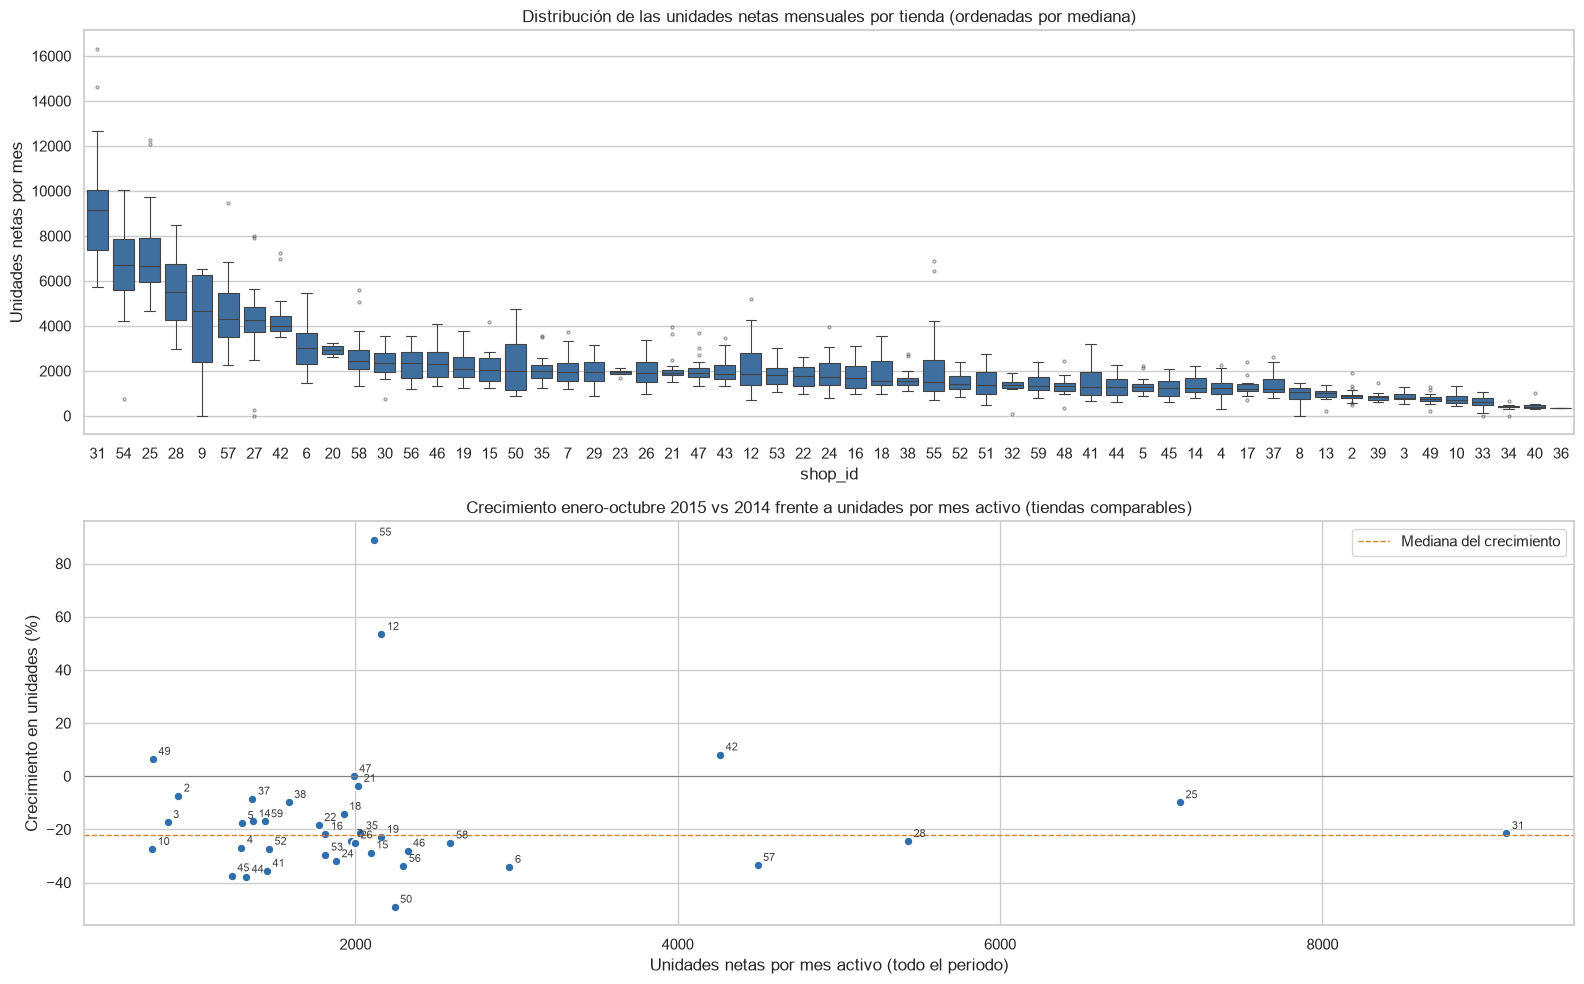

In [35]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Distribución de las ventas mensuales de cada tienda, ordenadas por su mediana
mensual_tienda_df = mensual_tienda.reset_index(name="unidades")
orden = mensual_tienda_df.groupby("shop_id")["unidades"].median().sort_values(ascending=False).index
sns.boxplot(data=mensual_tienda_df, x="shop_id", y="unidades", order=orden, color=COLOR, ax=axes[0],
            linewidth=0.8, flierprops={"markersize": 2, "alpha": 0.5})
axes[0].set_title("Distribución de las unidades netas mensuales por tienda (ordenadas por mediana)")
axes[0].set_xlabel("shop_id")
axes[0].set_ylabel("Unidades netas por mes")

# Crecimiento interanual frente al tamaño de la tienda
comp_t = tiendas.dropna(subset=["crecimiento_2015_vs_2014_%"])
axes[1].scatter(comp_t["unidades_por_mes"], comp_t["crecimiento_2015_vs_2014_%"], s=40, color=COLOR, edgecolor="white")
for shop_id, fila in comp_t.iterrows():
    axes[1].annotate(str(shop_id), (fila["unidades_por_mes"], fila["crecimiento_2015_vs_2014_%"]),
                     textcoords="offset points", xytext=(4, 3), fontsize=8, color="#444444")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axhline(comp_t["crecimiento_2015_vs_2014_%"].median(), color=COLOR_2, linestyle="--", linewidth=1,
                label="Mediana del crecimiento")
axes[1].set_title("Crecimiento enero-octubre 2015 vs 2014 frente a unidades por mes activo (tiendas comparables)")
axes[1].set_xlabel("Unidades netas por mes activo (todo el periodo)")
axes[1].set_ylabel("Crecimiento en unidades (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación de la comparación entre sucursales:**

- **Diferencias de tamaño:** el desempeño entre tiendas es muy desigual. La tienda 31 (Москва ТЦ "Семеновский") vende en promedio 9,140 unidades por mes, casi 5 veces la mediana de las tiendas (1,879). Le siguen la 25 (Москва ТРК "Атриум", 7,115), la 54 (Химки ТЦ "Мега", 6,635) y la 28 (Москва ТЦ "МЕГА Теплый Стан" II, 5,428). Las tiendas más grandes están en Moscú y sus alrededores, además de San Petersburgo (42) y Yakutsk (57). Las tiendas grandes también ofrecen una variedad de productos mucho mayor (más de 12,000 productos distintos frente a una mediana de 7,806).
- **Tiendas de bajo volumen:** las de menor venta por mes activo venden entre 330 y 900 unidades mensuales. Varias son tiendas que solo operaron parte del periodo (36 con 1 mes, 8 con 4 meses, 33 con 9 meses), pero otras como la 10, la 3 y la 2 operaron los 34 meses con ventas bajas de forma constante. Cuatro de las tiendas de bajo volumen (36, 34, 39 y 49) aparecen en `test`, por lo que el modelo tendrá que predecir tiendas con poca historia: la 36 solo tiene un mes.
- **Casos especiales:** las tiendas 9 (Выездная Торговля, venta itinerante) y 20 (Москва "Распродажа", liquidación) aparecen con ventas por mes activo altas, pero solo estuvieron activas 4 y 2 meses, con muy poca variedad de productos; no son comparables con una sucursal regular. En el boxplot, la tienda 9 tiene la mayor dispersión mensual.
- **Precio promedio por unidad:** varía entre 304 y 1,527 (mediana de 965) y casi no se relaciona con el volumen (correlación de -0.17). Es decir, las tiendas grandes no venden productos más caros, sino más unidades.
- **Crecimiento interanual:** de las 38 tiendas activas los 10 meses de 2014 y 2015, solo 4 crecieron. La mediana del crecimiento es -22.3%, lo que confirma que la caída de ventas de la sección 6 afecta a casi toda la red y no a unas pocas tiendas. Las excepciones más claras son la 55 (Цифровой склад 1С-Онлайн, almacén digital, +88.9%) y la 12 (Интернет-магазин ЧС, tienda en línea, +53.6%): los **canales en línea crecen mientras las tiendas físicas caen**. En el otro extremo, la 50 cae casi 50%.
- **Implicación:** el nivel de cada tienda y su tendencia propia son muy distintos, por lo que el `shop_id` (o variables derivadas como su venta histórica promedio) será una variable importante para el modelo.

### 7.c Outliers y comportamientos anómalos

Se revisan los valores extremos a nivel de transacción (precio y cantidad) y luego los comportamientos anómalos por sucursal y por producto.

Percentiles de precio y cantidad por transacción:


,p50,p90,p99,p99.9,p99.99,máximo
item_price,399.00,"1,999.00","5,999.00","23,990.00","29,990.00","307,980.00"
item_cnt_day,1.00,2.00,5.00,22.00,67.00,"2,169.00"


Transacciones con los precios más altos:


,date,shop_id,item_id,item_name,item_price,item_cnt_day,revenue
1163157,2013-12-13,12,6066,Radmin 3 - 522 лиц.,"307,980.00",1.00,"307,980.00"
885137,2013-09-17,12,11365,Доставка (EMS),"59,200.00",1.00,"59,200.00"
1488133,2014-03-20,25,13199,Коллекционные шахматы (Властелин Колец),"50,999.00",1.00,"50,999.00"
2327153,2015-01-29,12,7241,UserGate Proxy & Firewall 6.X с модулем фильтр...,"49,782.00",1.00,"49,782.00"
2885686,2015-10-23,42,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...","42,990.00",1.00,"42,990.00"
2910150,2015-10-29,12,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...","42,990.00",1.00,"42,990.00"
2917754,2015-10-20,3,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...","42,990.00",1.00,"42,990.00"
2931374,2015-10-20,22,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...","42,990.00",1.00,"42,990.00"


Transacciones con las cantidades más altas:


,date,shop_id,item_id,item_name,item_price,item_cnt_day,revenue
2909812,2015-10-28,12,11373,Доставка до пункта выдачи (Boxberry),0.91,"2,169.00","1,971.00"
2326924,2015-01-15,12,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,4.00,"1,000.00","4,000.00"
2864229,2015-09-30,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...","1,692.53",669.00,"1,132,300.00"
2851085,2015-09-30,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...","1,702.83",637.00,"1,084,700.00"
2608034,2015-04-14,12,3731,"Grand Theft Auto V [PC, русские субтитры]","1,904.55",624.00,"1,188,438.00"
2626175,2015-05-19,12,11373,Доставка до пункта выдачи (Boxberry),155.19,539.00,"83,649.00"
2851067,2015-09-29,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...","1,500.00",533.00,"799,500.00"
2048513,2014-10-02,12,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно -...","1,500.00",512.00,"768,000.00"


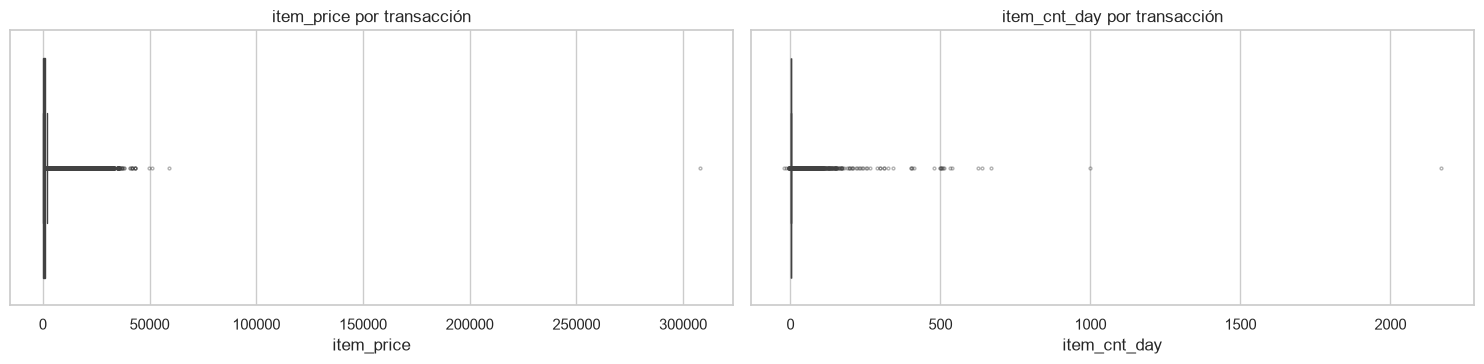

In [36]:
# Percentiles altos de precio y cantidad por transacción
niveles = [0.5, 0.9, 0.99, 0.999, 0.9999, 1]
etiquetas = ["p50", "p90", "p99", "p99.9", "p99.99", "máximo"]
percentiles = pd.DataFrame({
    "item_price": sales_train["item_price"].quantile(niveles).values,
    "item_cnt_day": sales_train["item_cnt_day"].quantile(niveles).values,
}, index=etiquetas).T
print("Percentiles de precio y cantidad por transacción:")
display(percentiles)

cols_tx = ["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day", "revenue"]
con_nombre = ventas.merge(items[["item_id", "item_name"]], on="item_id", how="left")
con_nombre["item_name"] = con_nombre["item_name"].str.slice(0, 50)
print("Transacciones con los precios más altos:")
display(con_nombre.nlargest(8, "item_price")[cols_tx])
print("Transacciones con las cantidades más altas:")
display(con_nombre.nlargest(8, "item_cnt_day")[cols_tx])

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
sns.boxplot(x=sales_train["item_price"], ax=axes[0], color=COLOR, flierprops={"markersize": 2, "alpha": 0.4})
axes[0].set_title("item_price por transacción")
axes[0].set_xlabel("item_price")
sns.boxplot(x=sales_train["item_cnt_day"], ax=axes[1], color=COLOR, flierprops={"markersize": 2, "alpha": 0.4})
axes[1].set_title("item_cnt_day por transacción")
axes[1].set_xlabel("item_cnt_day")
plt.tight_layout()
plt.show()

In [37]:
# Contexto de los dos valores más extremos frente al historial de su propio producto
for item_id, nombre_valor in [(6066, "precio de 307,980"), (11373, "cantidad de 2,169")]:
    hist = con_nombre[con_nombre["item_id"] == item_id]
    print(f"Producto {item_id} ({nombre_valor}): {hist['item_name'].iloc[0]}")
    print(f"  transacciones: {len(hist)}, tiendas: {hist['shop_id'].unique().tolist()}, "
          f"precio mediano: {hist['item_price'].median():,.2f}, cantidad mediana: {hist['item_cnt_day'].median():,.0f}, "
          f"segunda cantidad más alta: {hist['item_cnt_day'].nlargest(2).iloc[-1]:,.0f}, "
          f"en test: {item_id in set(test['item_id'])}")

# Transacción de 1,000 unidades de la bolsa de compras (20949) frente a su historial
bolsa = con_nombre[con_nombre["item_id"] == 20949]
print(f"\nProducto 20949 (bolsa de compras): cantidad mediana por transacción {bolsa['item_cnt_day'].median():,.0f}, "
      f"segunda cantidad más alta {bolsa['item_cnt_day'].nlargest(2).iloc[-1]:,.0f}, precio mediano {bolsa['item_price'].median():,.2f}")

# Precios anómalos dentro de cada producto: transacciones con precio mayor a 10 veces la mediana de su producto
mediana_item = sales_train.groupby("item_id")["item_price"].transform("median")
ratio = sales_train["item_price"] / mediana_item
print("\nTransacciones con precio > 10 veces la mediana de su producto:", (ratio > 10).sum())
print("Transacciones con precio < 1/10 de la mediana de su producto:", (ratio < 0.1).sum())
display(con_nombre.loc[(ratio > 10).values, cols_tx].head(10))

Producto 6066 (precio de 307,980): Radmin 3  - 522 лиц.
  transacciones: 1, tiendas: [12], precio mediano: 307,980.00, cantidad mediana: 1, segunda cantidad más alta: 1, en test: False
Producto 11373 (cantidad de 2,169): Доставка до пункта выдачи (Boxberry)
  transacciones: 464, tiendas: [12], precio mediano: 281.62, cantidad mediana: 4, segunda cantidad más alta: 539, en test: True

Producto 20949 (bolsa de compras): cantidad mediana por transacción 3, segunda cantidad más alta 501, precio mediano 5.00

Transacciones con precio > 10 veces la mediana de su producto: 1218
Transacciones con precio < 1/10 de la mediana de su producto: 2904


,date,shop_id,item_id,item_name,item_price,item_cnt_day,revenue
6664,2013-01-02,25,11865,Змей МАКС антистресс 33 см.,729.00,1.00,729.00
6686,2013-01-02,25,11856,Змей ВАСЯ 40 см,359.00,1.00,359.00
6687,2013-01-02,25,11860,Змей ВАСЯ с цветком 40 см,369.00,1.00,369.00
6688,2013-01-03,25,11860,Змей ВАСЯ с цветком 40 см,258.00,1.00,258.00
6690,2013-01-04,25,11863,Змей ДЖЕККИ с сердечком 24 см,223.00,1.00,223.00
8753,2013-01-09,22,11865,Змей МАКС антистресс 33 см.,510.00,1.00,510.00
8754,2013-01-11,22,11867,Змей ШНУР 15 см,69.00,1.00,69.00
9698,2013-01-03,19,5361,"Of Orcs and Men [PC, Jewel, русские субтитры]",549.00,1.00,549.00
9699,2013-01-12,19,5361,"Of Orcs and Men [PC, Jewel, русские субтитры]",549.00,1.00,549.00
9700,2013-01-17,19,5361,"Of Orcs and Men [PC, Jewel, русские субтитры]",549.00,1.00,549.00


In [38]:
# Comportamientos anómalos por sucursal: dónde se concentran las transacciones de cantidad extrema (> percentil 99.9)
umbral_cnt = sales_train["item_cnt_day"].quantile(0.999)
extremas = con_nombre[con_nombre["item_cnt_day"] > umbral_cnt]
por_tienda_ext = extremas.groupby("shop_id").size().sort_values(ascending=False).to_frame("transacciones_extremas")
por_tienda_ext["% del total de extremas"] = por_tienda_ext["transacciones_extremas"] / len(extremas) * 100
por_tienda_ext["shop_name"] = nombres_tienda.reindex(por_tienda_ext.index)
print(f"Transacciones con item_cnt_day > {umbral_cnt:.0f} (percentil 99.9): {len(extremas):,}")
display(por_tienda_ext.head(5))

# Productos que más aparecen entre las transacciones de cantidad extrema
print("Productos con más transacciones de cantidad extrema:")
display(extremas.groupby(["item_id", "item_name"]).size().sort_values(ascending=False).head(8).to_frame("transacciones_extremas"))

# Tienda 9 (venta itinerante): meses en los que tuvo actividad
print("Meses con ventas de la tienda 9 (Выездная Торговля):",
      sorted(ventas.loc[ventas["shop_id"] == 9, "date"].dt.strftime("%Y-%m").unique()))

Transacciones con item_cnt_day > 22 (percentil 99.9): 2,882


,transacciones_extremas,% del total de extremas,shop_name
shop_id,,,
31,502,17.42,"Москва ТЦ ""Семеновский"""
25,316,10.96,"Москва ТРК ""Атриум"""
12,289,10.03,Интернет-магазин ЧС
54,232,8.05,"Химки ТЦ ""Мега"""
28,200,6.94,"Москва ТЦ ""МЕГА Теплый Стан"" II"


Productos con más transacciones de cantidad extrema:


,,transacciones_extremas
item_id,item_name,
20949,Фирменный пакет майка 1С Интерес белый (34*42) 45,1230
2808,"Diablo III [PC, Jewel, русская версия]",131
3732,"Grand Theft Auto V [PS3, русские субтитры]",74
3731,"Grand Theft Auto V [PC, русские субтитры]",69
11370,Доставка (по Москве),55
2814,"Diablo III: Reaper of Souls (дополнение) [PC, русс",45
1849,"Battlefield 4 Limited Edition [PC, русская версия]",42
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A,42


Meses con ventas de la tienda 9 (Выездная Торговля): ['2013-10', '2014-10', '2015-04', '2015-10']


**Interpretación de los outliers y comportamientos anómalos:**

- **Distribuciones con cola muy larga:** el 99% de las transacciones tiene un precio de hasta 5,999 y una cantidad de hasta 5 unidades, y el 99.9% llega a 23,990 y 22 unidades. Los boxplots muestran que casi todos los puntos se concentran en esa zona y que hay dos valores completamente separados del resto: un precio de 307,980 y una cantidad de 2,169.
- **Precio de 307,980:** corresponde a una única venta del producto 6066 "Radmin 3 - 522 лиц." (una licencia de software para 522 equipos) en la tienda en línea 12. Es más de 5 veces el segundo precio más alto (59,200), el producto solo se vendió esa vez y no aparece en `test`. Es una venta corporativa excepcional, no representativa del negocio minorista.
- **Cantidad de 2,169:** corresponde al producto 11373 "Доставка до пункта выдачи (Boxberry)", que no es una mercancía sino un **servicio de entrega** de la tienda en línea 12, registrado con un precio de 0.91 por unidad. Su cantidad mediana es de 4 por transacción y la segunda más alta es de 539, por lo que 2,169 es 4 veces su propio máximo previo. Lo mismo ocurre con la venta de 1,000 unidades del producto 20949 (bolsa de compras) a 4 por unidad en la tienda 12: su cantidad mediana es 3 y su segunda más alta es 501.
- **Cantidades altas que sí son legítimas:** después de esos dos casos, las siguientes cantidades (669, 637, 533, 512) son boletos para la feria de videojuegos "ИгроМир" de 2014 y 2015 y la venta de 624 copias de GTA V para PC el día de su lanzamiento (identificado en la sección 6.b.iii). Son eventos comerciales reales.
- **Precios anómalos dentro de un mismo producto:** hay 1,218 transacciones con precio mayor a 10 veces la mediana de su producto y 2,904 con precio menor a la décima parte. Revisando ejemplos, se trata sobre todo de productos que cambiaron de precio con el tiempo (rebajas o liquidaciones, como los peluches "Змей" de la tienda 25), es decir, variación real de precios y no errores.
- **Anomalías por sucursal:** las transacciones de cantidad extrema (más de 22 unidades) se concentran en las tiendas más grandes (31, 25, 54 y 28), lo cual es esperable por su tamaño, y en la tienda en línea 12 (10% de esas transacciones), que vende boletos, servicios de entrega y lanzamientos en grandes cantidades. La tienda 9 (Выездная Торговля, venta itinerante) solo tiene actividad en octubre de 2013, 2014 y 2015 (y un mes de abril), coincidiendo con la feria ИгроМир: es un punto de venta temporal en eventos, lo que explica los picos de los primeros sábados de octubre vistos en 6.b.iii.
- **Anomalías por producto:** la bolsa de compras 20949 domina las transacciones de cantidad extrema (1,230 de 2,882), seguida por grandes lanzamientos (Diablo III, GTA V, Battlefield 4, PlayStation 4) y por el servicio de entrega en Moscú (11370).

**Decisión sobre los outliers:**

1. Se **eliminan** las transacciones con `item_price` > 100,000 (1 registro: la licencia de 307,980) y con `item_cnt_day` >= 1,000 (2 registros: el servicio de entrega con 2,169 y la bolsa con 1,000). Los umbrales se ubican en los saltos de la distribución: no hay ningún precio entre 59,200 y 307,980 ni ninguna cantidad entre 669 y 1,000. Son 3 transacciones aisladas que no representan la demanda normal, distorsionarían las agregaciones mensuales de sus pares tienda-producto (por ejemplo, el servicio 11373 sí está en `test`) y las métricas por tienda.
2. Se **conservan** el resto de los valores altos (boletos de ИгроМир, lanzamientos, consolas y productos caros) y las variaciones de precio dentro de un mismo producto, porque reflejan eventos y cambios de precio reales que el modelo debe aprender.
3. Se **conservan** también los productos que no son mercancía (bolsas, servicios de entrega, recargas), porque forman parte de las ventas registradas y aparecen en `test`; se deja documentado que su comportamiento es distinto al de los productos regulares.

In [39]:
# Aplicación de la decisión: eliminación de las 3 transacciones extremas
filas_antes = len(sales_train)
mascara_outliers = (sales_train["item_price"] > 100_000) | (sales_train["item_cnt_day"] >= 1_000)
display(sales_train[mascara_outliers])
sales_train = sales_train[~mascara_outliers].reset_index(drop=True)
datasets["sales_train"] = sales_train
print("Filas antes:", filas_antes, "| filas después:", len(sales_train), "| eliminadas:", filas_antes - len(sales_train))
print("Nuevo máximo de item_price:", sales_train["item_price"].max(), "| nuevo máximo de item_cnt_day:", sales_train["item_cnt_day"].max())

# Se recalculan las tablas derivadas para que las secciones siguientes usen los datos limpios
ventas = sales_train.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
diario = ventas.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
mensual = ventas.groupby("date_block_num").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
serie_mensual = pd.Series(mensual["unidades"].values, index=fechas_mes, name="unidades")
mensual_tienda = ventas.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum()
print("Unidades netas totales después de la limpieza:", f"{ventas['item_cnt_day'].sum():,.0f}")

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,revenue
1163157,2013-12-13,11,12,6066,"307,980.00",1.00,"307,980.00"
2326924,2015-01-15,24,12,20949,4.00,"1,000.00","4,000.00"
2909812,2015-10-28,33,12,11373,0.91,"2,169.00","1,971.00"


Filas antes: 2935843 | filas después: 2935840 | eliminadas: 3


Nuevo máximo de item_price: 59200.0 | nuevo máximo de item_cnt_day: 669.0


Unidades netas totales después de la limpieza: 3,645,030


**Resultado:** se eliminaron las 3 transacciones extremas y `sales_train` queda con 2,935,840 filas; el nuevo precio máximo es 59,200 y la nueva cantidad máxima es 669. A partir de aquí todas las secciones usan esta versión limpia, que acumula las decisiones de la sección 4 (imputación del precio negativo, eliminación de duplicados exactos y unificación de tiendas) y la de esta sección. Las tablas derivadas (`ventas`, `diario`, `mensual`, `serie_mensual` y `mensual_tienda`) se recalcularon con estos datos. El impacto en los totales es mínimo (3,170 unidades menos, de 3,648,200 a 3,645,030), pero evita que tres registros aislados distorsionen las series de los pares tienda-producto afectados.

## 8. Visualizaciones clave

Todas las gráficas de esta sección usan los datos limpios de la sección 7.c y las ventas netas en unidades (unidades vendidas menos devoluciones).

### 8.a Serie de tiempo de ventas totales

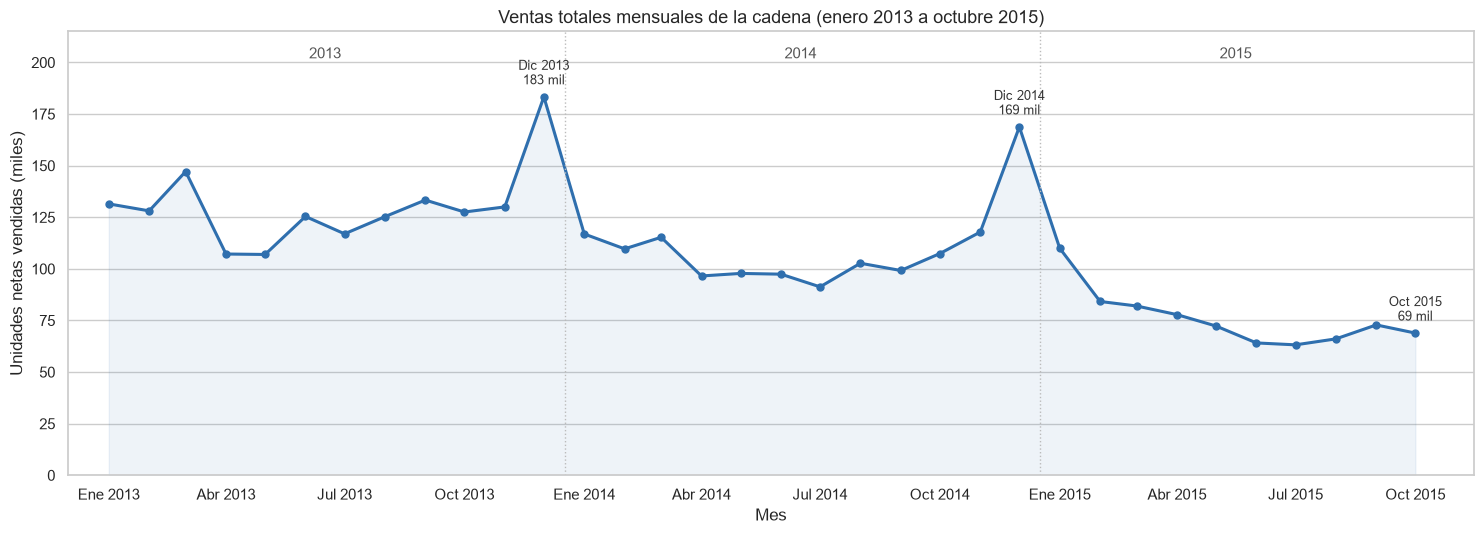

In [40]:
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(serie_mensual.index, serie_mensual / 1000, color=COLOR, linewidth=2.2, marker="o", markersize=5)
ax.fill_between(serie_mensual.index, serie_mensual / 1000, color=COLOR, alpha=0.08)

# Separadores entre años y etiqueta de cada año
for anio in [2014, 2015]:
    ax.axvline(pd.Timestamp(f"{anio}-01-01") - pd.Timedelta(days=15), color="#bbbbbb", linestyle=":", linewidth=1)
for anio, centro in [(2013, "2013-06-16"), (2014, "2014-06-16"), (2015, "2015-05-16")]:
    ax.text(pd.Timestamp(centro), 202, str(anio), ha="center", fontsize=11, color="#555555")

# Etiquetas solo en los puntos clave: picos de diciembre y último mes observado
for fecha in [pd.Timestamp("2013-12-01"), pd.Timestamp("2014-12-01"), serie_mensual.index[-1]]:
    valor = serie_mensual[fecha] / 1000
    ax.annotate(f"{MESES_ES[fecha.month - 1]} {fecha.year}\n{valor:,.0f} mil", (fecha, valor), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9, color="#333333")

ticks = [f for f in serie_mensual.index if f.month in (1, 4, 7, 10)]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{MESES_ES[f.month - 1]} {f.year}" for f in ticks])
ax.set_xlim(pd.Timestamp("2012-12-01"), pd.Timestamp("2015-11-15"))
ax.set_ylim(0, 215)
ax.set_title("Ventas totales mensuales de la cadena (enero 2013 a octubre 2015)", fontsize=13)
ax.set_xlabel("Mes")
ax.set_ylabel("Unidades netas vendidas (miles)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Interpretación:** la serie total muestra los dos rasgos principales de las ventas. Primero, una **tendencia decreciente**: octubre de 2015 cerró con unas 69 mil unidades, alrededor de 46% menos que octubre de 2013 (unas 128 mil). Segundo, una **estacionalidad anual** con picos en diciembre (183 mil en 2013 y 169 mil en 2014) seguidos de caídas fuertes en enero. Noviembre, el mes a predecir, marca en ambos años el inicio de la subida hacia diciembre, por lo que se espera que noviembre de 2015 sea superior a octubre, aunque en un nivel general más bajo que en los años anteriores.

### 8.b Ventas por sucursal

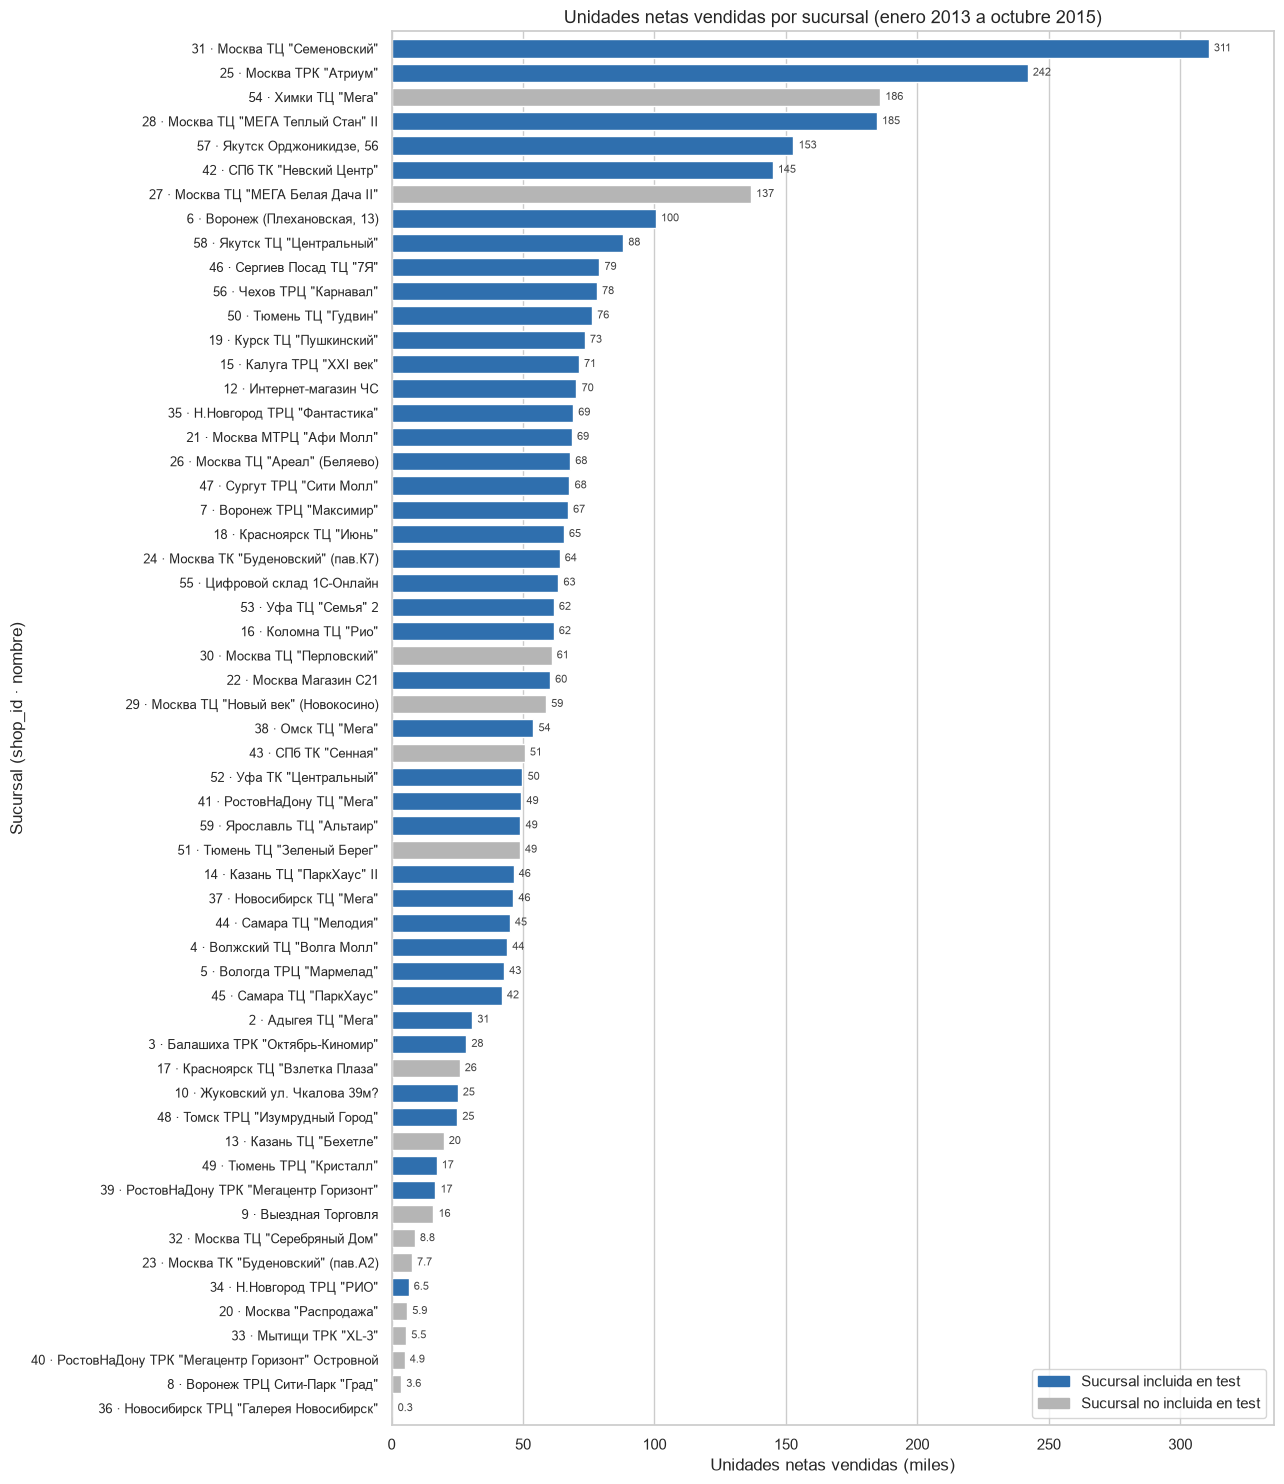

Participación de las 5 sucursales con más ventas: 29.5%


In [41]:
por_sucursal = ventas.groupby("shop_id")["item_cnt_day"].sum().sort_values()
etiquetas = [f"{i} · {nombres_tienda[i]}" for i in por_sucursal.index]
colores = [COLOR if i in set(test["shop_id"]) else "#b5b5b5" for i in por_sucursal.index]

fig, ax = plt.subplots(figsize=(13, 15))
ax.barh(etiquetas, por_sucursal / 1000, color=colores, height=0.75)
for y, valor in enumerate(por_sucursal / 1000):
    ax.text(valor + 2, y, f"{valor:,.1f}" if valor < 10 else f"{valor:,.0f}", va="center", fontsize=8, color="#444444")

ax.set_title("Unidades netas vendidas por sucursal (enero 2013 a octubre 2015)", fontsize=13)
ax.set_xlabel("Unidades netas vendidas (miles)")
ax.set_ylabel("Sucursal (shop_id · nombre)")
ax.set_xlim(0, por_sucursal.max() / 1000 * 1.08)
ax.set_ylim(-0.7, len(por_sucursal) - 0.3)
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.matplotlib.patches.Patch(color=COLOR, label="Sucursal incluida en test"),
                   plt.matplotlib.patches.Patch(color="#b5b5b5", label="Sucursal no incluida en test")],
          loc="lower right")
plt.tight_layout()
plt.show()

print("Participación de las 5 sucursales con más ventas:",
      f"{por_sucursal.sort_values(ascending=False).head(5).sum() / por_sucursal.sum() * 100:.1f}%")

**Interpretación:** las ventas por sucursal están muy concentradas en pocas tiendas: la 31 (Москва ТЦ "Семеновский", 311 mil unidades) y la 25 (Москва ТРК "Атриум", 242 mil) encabezan la cadena, y las 5 sucursales con más ventas reúnen el 29.5% de todas las unidades. La mayoría de las tiendas está entre 40 y 80 mil unidades en todo el periodo. En gris aparecen las 15 sucursales que no están en `test`: incluyen tiendas grandes que dejaron de operar antes de noviembre de 2015 (54 y 27) y tiendas de vida corta o especiales (9, 20, 33, 40, 8). Al final de la gráfica hay tiendas de `test` con muy poco historial, como la 36 (330 unidades) y la 34, para las que el modelo tendrá poca información.

### 8.c Ventas por producto (top N) y por categoría

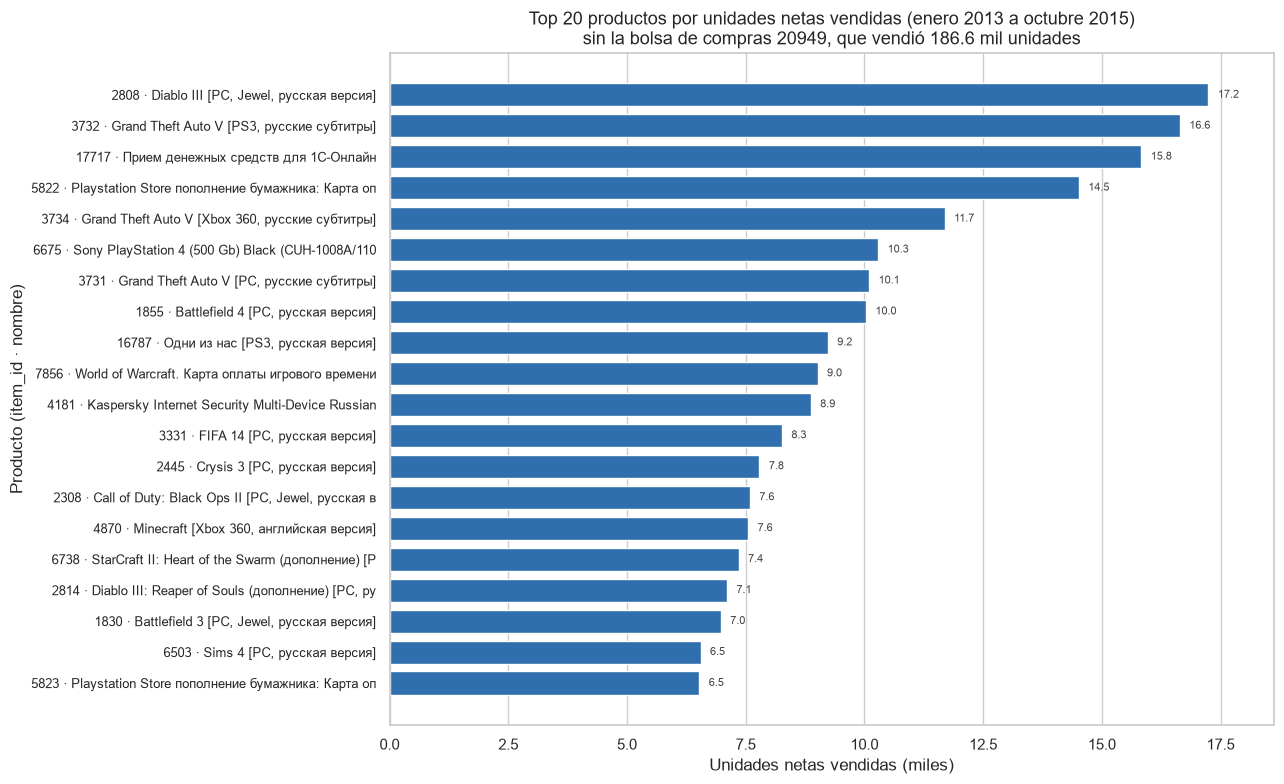

Participación de la bolsa de compras 20949: 5.1%
Participación de los 20 productos de la gráfica: 5.5%


In [42]:
# Unidades netas por producto con los datos limpios de la sección 7.c.
# La bolsa de compras 20949 se muestra aparte: sus 186.6 mil unidades comprimirían el resto de las barras
# y no es una mercancía como tal (sección 7.a).
TOP_N = 20
unidades_producto = ventas.groupby("item_id")["item_cnt_day"].sum().sort_values(ascending=False)
top_productos = unidades_producto.drop(20949).head(TOP_N).iloc[::-1]
etiquetas_p = [f"{i} · {nombres_item[i][:48]}" for i in top_productos.index]

fig, ax = plt.subplots(figsize=(13, 8))
ax.barh(etiquetas_p, top_productos / 1000, color=COLOR, height=0.75)
for y, valor in enumerate(top_productos / 1000):
    ax.text(valor + 0.2, y, f"{valor:,.1f}", va="center", fontsize=8, color="#444444")
ax.set_title(f"Top {TOP_N} productos por unidades netas vendidas (enero 2013 a octubre 2015)\n"
             f"sin la bolsa de compras 20949, que vendió {unidades_producto[20949] / 1000:,.1f} mil unidades", fontsize=13)
ax.set_xlabel("Unidades netas vendidas (miles)")
ax.set_ylabel("Producto (item_id · nombre)")
ax.set_xlim(0, top_productos.max() / 1000 * 1.08)
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Participación de la bolsa de compras 20949: {unidades_producto[20949] / unidades_producto.sum() * 100:.1f}%")
print(f"Participación de los {TOP_N} productos de la gráfica: "
      f"{top_productos.sum() / unidades_producto.sum() * 100:.1f}%")

**Interpretación:** sin contar la bolsa de compras 20949 (5.1% de todas las unidades, mostrada aparte porque comprimiría el resto de las barras), el top 20 está dominado por **videojuegos**, sobre todo de PC: Diablo III (17.2 mil unidades), Grand Theft Auto V en PS3, Xbox 360 y PC, Battlefield 4, FIFA 14, Crysis 3 y Call of Duty: Black Ops II. También aparecen productos de pago y suscripción (recarga 1С-Онлайн, tarjetas de PlayStation Store y de World of Warcraft), la consola PlayStation 4 y el antivirus Kaspersky. Aun así, estos 20 productos solo suman el 5.5% de las unidades: la venta está muy repartida entre miles de productos, lo que hace que la mayoría de los pares tienda-producto tenga ventas mensuales bajas.

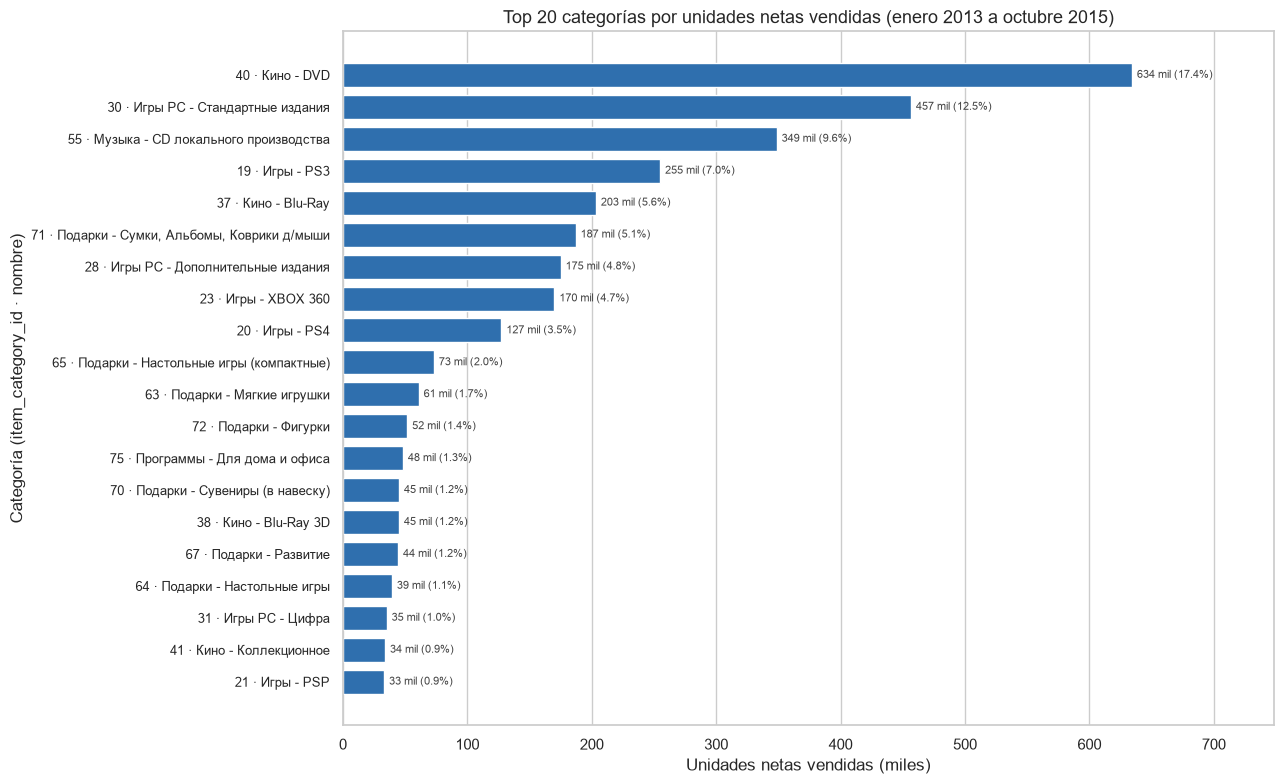

Participación de las 20 categorías de la gráfica: 84.1%
Las otras 64 categorías suman: 15.9%


In [43]:
# Unidades netas por categoría con los datos limpios (top 20 de las 84 categorías)
TOP_CAT = 20
unidades_categoria = ventas.groupby("item_category_id")["item_cnt_day"].sum().sort_values(ascending=False)
top_cat = unidades_categoria.head(TOP_CAT).iloc[::-1]
etiquetas_c = [f"{i} · {nombres_cat[i]}" for i in top_cat.index]
participacion = top_cat / unidades_categoria.sum() * 100

fig, ax = plt.subplots(figsize=(13, 8))
ax.barh(etiquetas_c, top_cat / 1000, color=COLOR, height=0.75)
for y, (valor, pct) in enumerate(zip(top_cat / 1000, participacion)):
    ax.text(valor + 4, y, f"{valor:,.0f} mil ({pct:.1f}%)", va="center", fontsize=8, color="#444444")
ax.set_title(f"Top {TOP_CAT} categorías por unidades netas vendidas (enero 2013 a octubre 2015)", fontsize=13)
ax.set_xlabel("Unidades netas vendidas (miles)")
ax.set_ylabel("Categoría (item_category_id · nombre)")
ax.set_xlim(0, top_cat.max() / 1000 * 1.18)
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Participación de las {TOP_CAT} categorías de la gráfica: {top_cat.sum() / unidades_categoria.sum() * 100:.1f}%")
print(f"Las otras {len(unidades_categoria) - TOP_CAT} categorías suman: "
      f"{unidades_categoria.iloc[TOP_CAT:].sum() / unidades_categoria.sum() * 100:.1f}%")

**Interpretación:** por categoría la concentración es mucho mayor que por producto: las 20 categorías de la gráfica reúnen el 84.1% de las unidades y las otras 64 solo el 15.9%. La categoría líder es Кино - DVD (películas en DVD, 634 mil unidades, 17.4%), seguida de Игры PC - Стандартные издания (juegos de PC, 12.5%) y Музыка - CD локального производства (CD de música local, 9.6%). En conjunto, películas, videojuegos de PC y consola, y música explican la mayor parte del volumen. La categoría 71 (bolsas, álbumes y tapetes) aparece en sexto lugar casi exclusivamente por la bolsa de compras 20949. Varias categorías de regalos (juegos de mesa, peluches, figuras) completan el top 20 con participaciones de 1% a 2%.

### 8.d Heatmaps de ventas en el tiempo por sucursal y por categoría

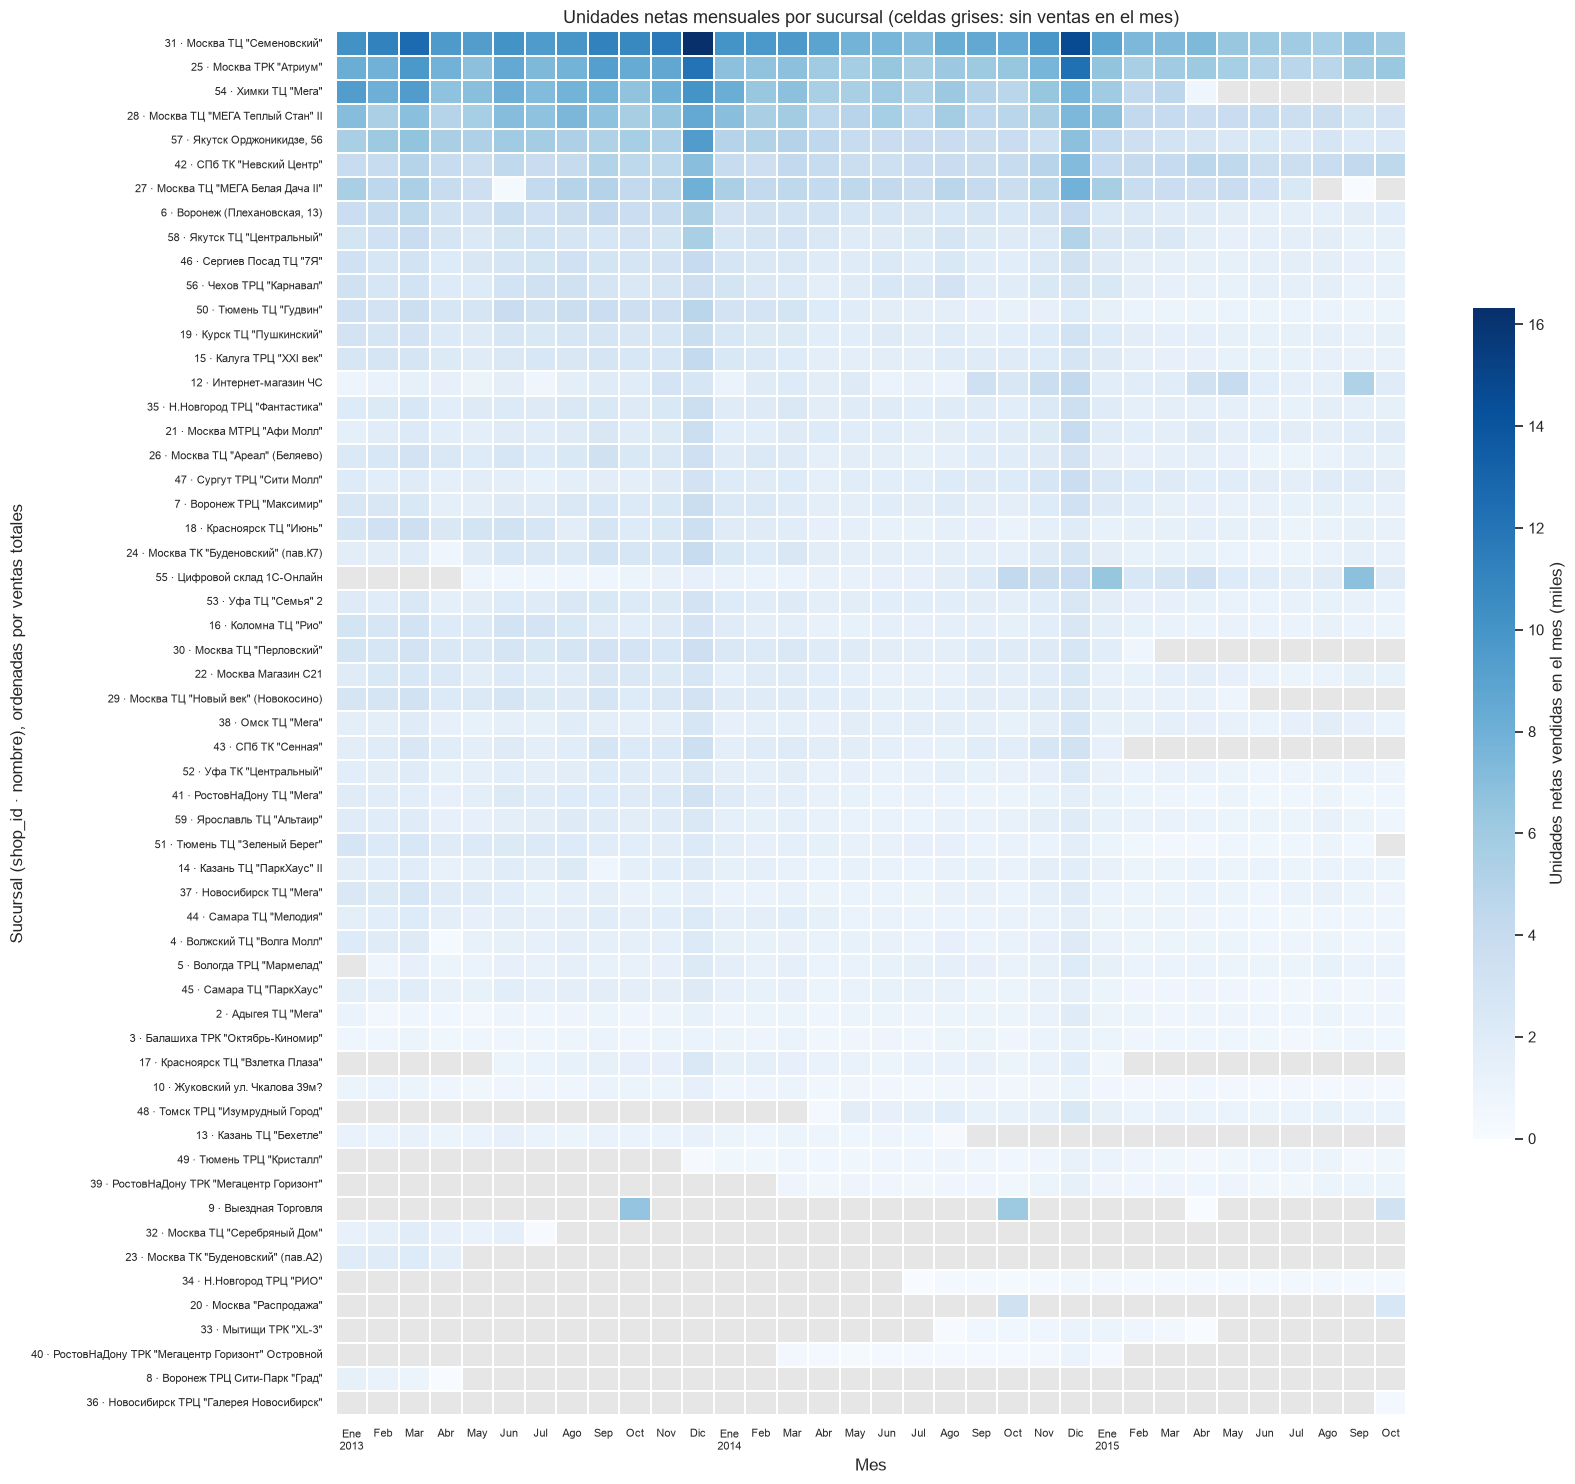

In [44]:
etiquetas_mes = [f"{MESES_ES[f.month - 1]}\n{f.year}" if f.month == 1 or i == 0 else MESES_ES[f.month - 1]
                 for i, f in enumerate(fechas_mes)]

# Matriz sucursal x mes (miles de unidades netas); sucursales ordenadas por ventas totales
matriz_tienda = (mensual_tienda.unstack("date_block_num").reindex(columns=range(34)) / 1000)
matriz_tienda = matriz_tienda.loc[matriz_tienda.sum(axis=1).sort_values(ascending=False).index]
matriz_tienda.index = [f"{i} · {nombres_tienda[i]}" for i in matriz_tienda.index]

fig, ax = plt.subplots(figsize=(17, 15))
sns.heatmap(matriz_tienda, cmap="Blues", linewidths=0.3, linecolor="white", ax=ax,
            cbar_kws={"label": "Unidades netas vendidas en el mes (miles)", "shrink": 0.6},
            mask=matriz_tienda.isna())
ax.set_facecolor("#e6e6e6")
ax.grid(False)
ax.set_xticks(np.arange(34) + 0.5)
ax.set_xticklabels(etiquetas_mes, rotation=0, fontsize=8)
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Unidades netas mensuales por sucursal (celdas grises: sin ventas en el mes)", fontsize=13)
ax.set_xlabel("Mes")
ax.set_ylabel("Sucursal (shop_id · nombre), ordenadas por ventas totales")
plt.tight_layout()
plt.show()

**Interpretación:** el heatmap muestra al mismo tiempo el tamaño, la estacionalidad y el ciclo de vida de cada sucursal. Las filas superiores (31, 25, 54 y 28) son las más oscuras durante todo el periodo, y en casi todas las tiendas la columna de diciembre es la más oscura de cada año, lo que confirma que el pico de fin de año es generalizado y no depende de unas pocas sucursales. De izquierda a derecha las celdas se aclaran, reflejando la tendencia decreciente. Las celdas grises muestran aperturas y cierres: tiendas como la 30, 43, 13, 32, 23 y 8 dejan de vender antes del final del periodo, la 54 y la 27 tienen meses sin ventas en 2015, y tiendas como la 48, 49, 39 y 34 abren después de 2013. La 36 solo tiene ventas en octubre de 2015. La tienda 9 solo se activa en octubre (feria ИгроМир), y las tiendas en línea 12 y 55 son de las pocas que se oscurecen en 2014 y 2015, en línea con su crecimiento (sección 7.b).

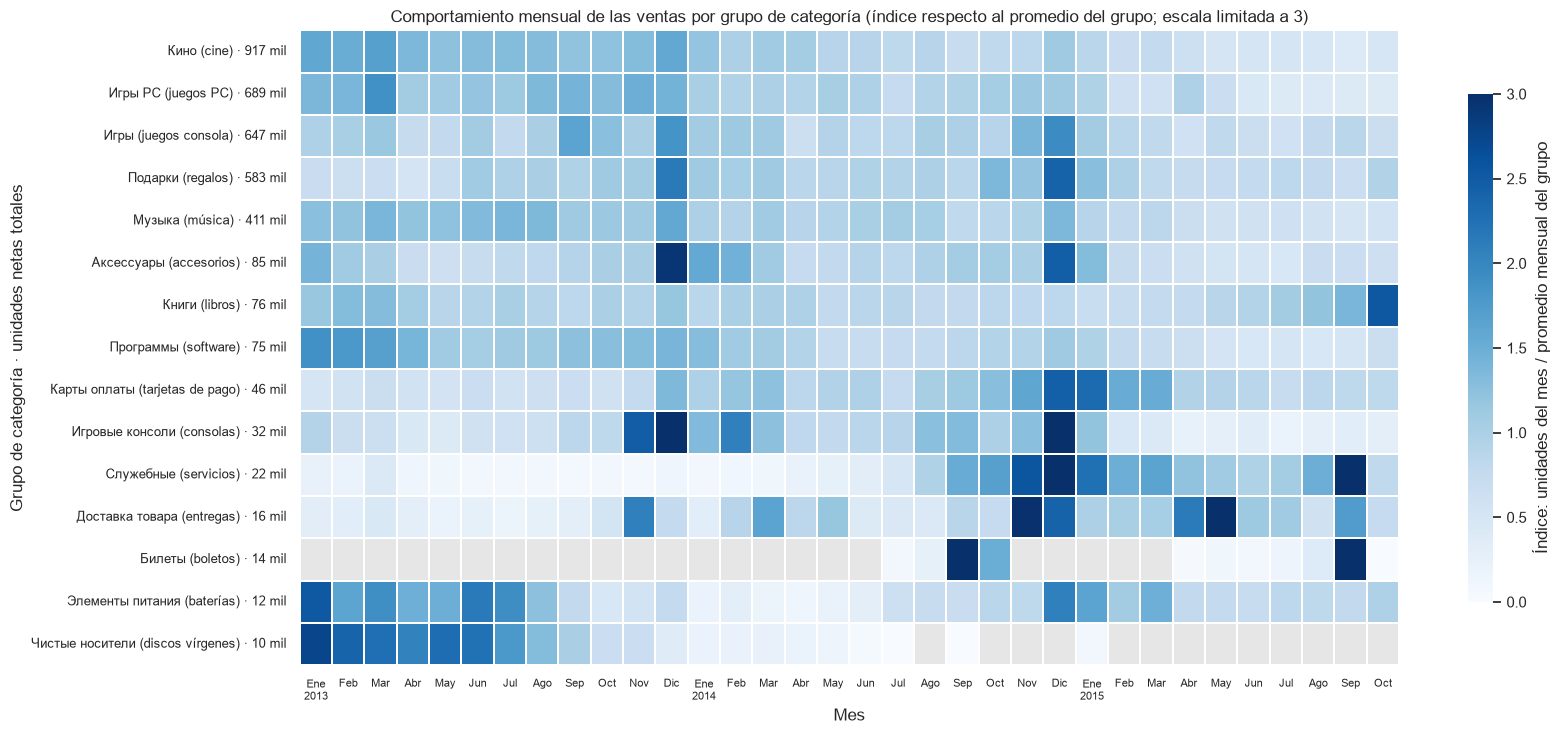

Índice de diciembre por grupo (2013 y 2014):


date_block_num,Dic 2013,Dic 2014
Кино (cine) · 917 mil,1.58,1.12
Игры PC (juegos PC) · 689 mil,1.44,1.12
Игры (juegos consola) · 647 mil,1.85,1.94
Подарки (regalos) · 583 mil,2.16,2.41
Музыка (música) · 411 mil,1.57,1.37
Аксессуары (accesorios) · 85 mil,2.94,2.46
Книги (libros) · 76 mil,1.18,0.84
Программы (software) · 75 mil,1.40,1.12
Карты оплаты (tarjetas de pago) · 46 mil,1.35,2.44
Игровые консоли (consolas) · 32 mil,4.23,3.62


In [45]:
# Matriz grupo de categoría x mes. Como los grupos tienen volúmenes muy distintos, cada celda se expresa como
# índice: unidades del mes divididas entre el promedio mensual del propio grupo (1 = mes promedio del grupo).
# Se incluyen los grupos con al menos 10,000 unidades en el periodo.
ventas_grupo = ventas.merge(item_categories[["item_category_id", "grupo"]], on="item_category_id", how="left")
grupo_mes = ventas_grupo.groupby(["grupo", "date_block_num"])["item_cnt_day"].sum().unstack("date_block_num").reindex(columns=range(34))
totales_grupo = grupo_mes.sum(axis=1).sort_values(ascending=False)
grupo_mes = grupo_mes.loc[totales_grupo[totales_grupo >= 10_000].index]
indice_grupo = grupo_mes.div(grupo_mes.mean(axis=1), axis=0)

traduccion = {
    "Кино": "Кино (cine)", "Игры PC": "Игры PC (juegos PC)", "Игры": "Игры (juegos consola)",
    "Подарки": "Подарки (regalos)", "Музыка": "Музыка (música)", "Аксессуары": "Аксессуары (accesorios)",
    "Книги": "Книги (libros)", "Программы": "Программы (software)", "Карты оплаты": "Карты оплаты (tarjetas de pago)",
    "Игровые консоли": "Игровые консоли (consolas)", "Служебные": "Служебные (servicios)",
    "Доставка товара": "Доставка товара (entregas)", "Билеты (Цифра)": "Билеты (boletos)",
    "Элементы питания": "Элементы питания (baterías)", "Чистые носители (штучные)": "Чистые носители (discos vírgenes)",
}
indice_grupo.index = [f"{traduccion.get(g, g)} · {totales_grupo[g] / 1000:,.0f} mil" for g in indice_grupo.index]

fig, ax = plt.subplots(figsize=(17, 7.5))
sns.heatmap(indice_grupo, cmap="Blues", vmin=0, vmax=3, linewidths=0.3, linecolor="white", ax=ax,
            cbar_kws={"label": "Índice: unidades del mes / promedio mensual del grupo", "shrink": 0.8},
            mask=indice_grupo.isna())
ax.set_facecolor("#e6e6e6")
ax.grid(False)
ax.set_xticks(np.arange(34) + 0.5)
ax.set_xticklabels(etiquetas_mes, rotation=0, fontsize=8)
ax.tick_params(axis="y", labelsize=9)
ax.set_title("Comportamiento mensual de las ventas por grupo de categoría (índice respecto al promedio del grupo; escala limitada a 3)", fontsize=12)
ax.set_xlabel("Mes")
ax.set_ylabel("Grupo de categoría · unidades netas totales")
plt.tight_layout()
plt.show()

print("Índice de diciembre por grupo (2013 y 2014):")
display(indice_grupo[[11, 23]].rename(columns={11: "Dic 2013", 23: "Dic 2014"}).round(2))

**Interpretación:** al expresar cada grupo respecto a su propio promedio se comparan patrones y no volúmenes. Casi todos los grupos con mercancía física (juegos de consola, regalos, accesorios, consolas, cine y música) se oscurecen en diciembre: las consolas venden en diciembre entre 3.6 y 4.2 veces su promedio mensual, los accesorios entre 2.5 y 2.9 veces y los regalos entre 2.2 y 2.4 veces. Las consolas además se adelantan con un pico en noviembre de 2013. Los grupos principales (cine, juegos de PC y música) muestran la tendencia decreciente, más clara en 2015. En cambio, hay grupos con ciclos de vida distintos: los servicios, las entregas y las tarjetas de pago, ligados a la venta en línea, prácticamente no existen en 2013 y crecen desde finales de 2014; los boletos solo aparecen en septiembre y octubre (feria ИгроМир); y los discos vírgenes y las baterías se van apagando hasta desaparecer. Esto indica que la categoría del producto determina tanto la intensidad de la estacionalidad como la tendencia, por lo que es una variable útil para el modelo.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

**Series analizadas y criterio de selección.** Se trabaja con unidades netas y los datos limpios de la sección 7.c. El enunciado pide cuatro tipos de serie:

1. **Ventas totales:** la serie de toda la cadena, a nivel mensual (34 observaciones) y diario (1,034 observaciones).
2. **Ventas por sucursal**, 3. **por producto** y 4. **por sucursal-producto:** como hay 57 tiendas, más de 21,000 productos y más de 400,000 pares, se elige una muestra representativa. Para cada nivel se toman las **3 series con más unidades vendidas entre las que tienen ventas en los 34 meses**. En productos y pares sucursal-producto se excluyen además los artículos que no son mercancía (servicios, servicios de entrega y la bolsa de compras 20949): sin esta exclusión, los tres pares con más ventas serían servicios de entrega de la tienda en línea 12, que no representan el comportamiento de los productos a predecir. Exigir los 34 meses evita series que empiezan o terminan a mitad del periodo (aperturas, cierres, lanzamientos), cuyos ceros o huecos distorsionarían la autocorrelación. Estas series se agregan a nivel mensual.

**Parámetros:**
- Series mensuales: hasta **16 rezagos**. Con 34 observaciones, la PACF solo se puede estimar de forma confiable hasta la mitad de la serie (17), y 16 rezagos permiten ver el rezago 12, que corresponde a la estacionalidad anual.
- Serie diaria: **56 rezagos** (8 semanas), para que se vean varias repeticiones del ciclo semanal (rezagos 7, 14, 21, ...).
- La zona sombreada de cada gráfico es el intervalo de confianza del 95%: un rezago es **significativo** cuando su barra sale de esa zona.

### 9.a Gráficos ACF y PACF

In [46]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

LAGS_MENSUAL = 16
LAGS_DIARIO = 56

def rezagos_significativos(serie, lags):
    """Rezagos (>= 1) cuyo intervalo de confianza del 95% no incluye el cero, para ACF y PACF."""
    valores_acf, ic_acf = acf(serie, nlags=lags, alpha=0.05, result_object=False)
    valores_pacf, ic_pacf = pacf(serie, nlags=lags, alpha=0.05, method="ywm")
    sig_acf = [k for k in range(1, lags + 1) if ic_acf[k, 0] > 0 or ic_acf[k, 1] < 0]
    sig_pacf = [k for k in range(1, lags + 1) if ic_pacf[k, 0] > 0 or ic_pacf[k, 1] < 0]
    return sig_acf, sig_pacf, valores_acf, valores_pacf

def graficar_acf_pacf(series, lags, titulo_general):
    """Una fila por serie: ACF a la izquierda y PACF a la derecha."""
    fig, axes = plt.subplots(len(series), 2, figsize=(15, 3.6 * len(series)), squeeze=False)
    for fila, (nombre, serie) in enumerate(series.items()):
        plot_acf(serie, lags=lags, ax=axes[fila, 0], color=COLOR, vlines_kwargs={"colors": COLOR})
        plot_pacf(serie, lags=lags, ax=axes[fila, 1], method="ywm", color=COLOR, vlines_kwargs={"colors": COLOR})
        axes[fila, 0].set_title(f"ACF: {nombre}", fontsize=10)
        axes[fila, 1].set_title(f"PACF: {nombre}", fontsize=10)
        for ax in axes[fila]:
            ax.set_xlabel("Rezago")
            ax.set_ylabel("Correlación")
            ax.set_ylim(-1.1, 1.1)
            ax.grid(axis="x", visible=False)
    fig.suptitle(titulo_general, fontsize=13)
    plt.tight_layout()
    plt.show()

def serie_mensual_completa(df):
    """Serie mensual de 34 meses (rellena con 0 los meses sin ventas)."""
    return df.groupby("date_block_num")["item_cnt_day"].sum().reindex(range(34), fill_value=0)

# Selección de las series representativas: top 3 por unidades entre las que tienen ventas en los 34 meses.
# Para productos y pares se excluyen los artículos que no son mercancía (servicios, entregas y la bolsa 20949),
# porque si no el top de pares quedaría formado solo por servicios de entrega de la tienda en línea 12.
grupo_item = items.set_index("item_id")["item_category_id"].map(item_categories.set_index("item_category_id")["grupo"])
no_mercancia = set(grupo_item[grupo_item.isin(["Служебные", "Доставка товара"])].index) | {20949}
ventas_mercancia = ventas[~ventas["item_id"].isin(no_mercancia)]

def seleccionar_top(df, columnas, n=3):
    resumen = df.groupby(columnas).agg(unidades=("item_cnt_day", "sum"), meses=("date_block_num", "nunique"))
    return resumen[resumen["meses"] == 34].sort_values("unidades", ascending=False).head(n)

sel_tiendas = seleccionar_top(ventas, "shop_id")
sel_productos = seleccionar_top(ventas_mercancia, "item_id")
sel_pares = seleccionar_top(ventas_mercancia, ["shop_id", "item_id"])

sel_tiendas["nombre"] = nombres_tienda.reindex(sel_tiendas.index)
sel_productos["nombre"] = nombres_item.reindex(sel_productos.index).str.slice(0, 50)
sel_pares["nombre"] = [f"{nombres_tienda[s]} / {nombres_item[i][:35]}" for s, i in sel_pares.index]

print("Sucursales seleccionadas:")
display(sel_tiendas)
print("Productos seleccionados:")
display(sel_productos)
print("Pares sucursal-producto seleccionados:")
display(sel_pares)
print("Pares sucursal-producto con ventas en los 34 meses:",
      (ventas.groupby(["shop_id", "item_id"])["date_block_num"].nunique() == 34).sum(),
      "de", ventas.groupby(["shop_id", "item_id"]).ngroups)

Sucursales seleccionadas:


,unidades,meses,nombre
shop_id,,,
31,"310,777.00",34,"Москва ТЦ ""Семеновский"""
25,"241,919.00",34,"Москва ТРК ""Атриум"""
28,"184,557.00",34,"Москва ТЦ ""МЕГА Теплый Стан"" II"


Productos seleccionados:


,unidades,meses,nombre
item_id,,,
2808,"17,245.00",34,"Diablo III [PC, Jewel, русская версия]"
5822,"14,515.00",34,Playstation Store пополнение бумажника: Карта ...
7856,"9,012.00",34,World of Warcraft. Карта оплаты игрового време...


Pares sucursal-producto seleccionados:


unidades  meses  \
shop_id item_id                    
31      5822     1,293.00     34   
        7856       864.00     34   
42      5822       789.00     34   

                                                            nombre  
shop_id item_id                                                     
31      5822     Москва ТЦ "Семеновский" / Playstation Store по...  
        7856     Москва ТЦ "Семеновский" / World of Warcraft. К...  
42      5822     СПб ТК "Невский Центр" / Playstation Store поп...

Pares sucursal-producto con ventas en los 34 meses: 114 de 418908


**Interpretación de la selección:** las tres sucursales elegidas (31, 25 y 28, todas de Moscú) son las de mayor volumen entre las 35 que vendieron los 34 meses. Los productos elegidos son Diablo III para PC y dos medios de pago de videojuegos (tarjeta de PlayStation Store y tarjeta de tiempo de juego de World of Warcraft), productos de catálogo permanente. Los pares sucursal-producto combinan esas tarjetas con las tiendas 31 y 42. Que solo 114 de los 418,908 pares tienda-producto tengan ventas en los 34 meses confirma lo observado en la sección 5: la gran mayoría de las series tienda-producto son cortas o intermitentes, por lo que las series seleccionadas representan el comportamiento de los productos más estables, no el del par típico.

#### Serie de ventas totales (mensual y diaria)

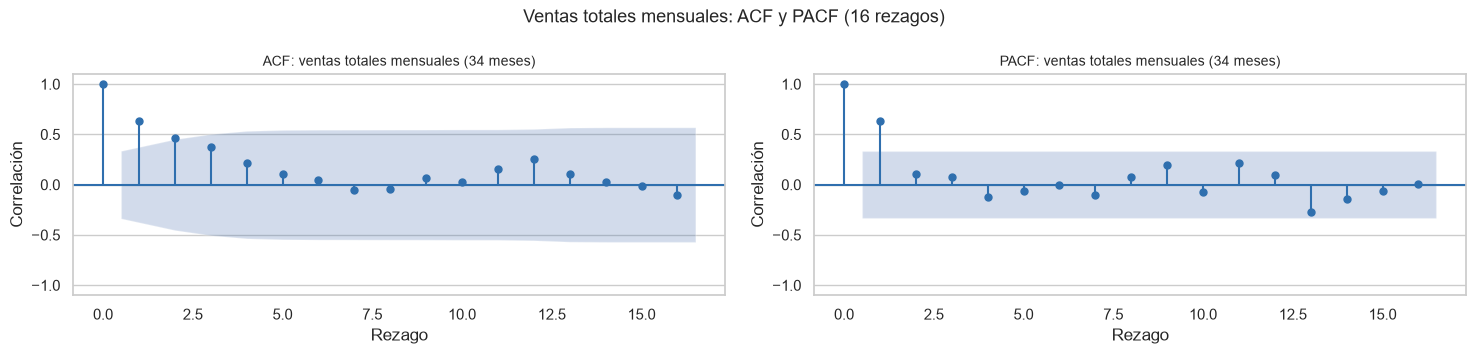

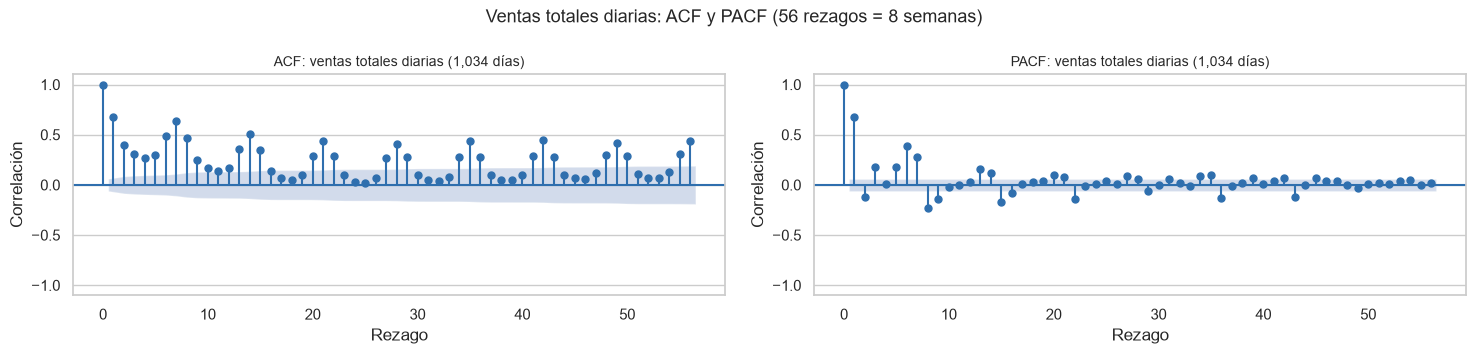

Total mensual: rezagos significativos ACF [1, 2]
Total mensual: rezagos significativos PACF [1]
Total diaria: rezagos significativos ACF [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 21, 22, 27, 28, 29, 34, 35, 36, 41, 42, 43, 48, 49, 50, 55, 56]
Total diaria: rezagos significativos PACF [1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21, 22, 27, 29, 31, 34, 35, 36, 39, 42, 43, 45]
ACF diaria en los rezagos 1, 3, 6, 7, 14, 21, 28: {1: 0.68, 3: 0.31, 6: 0.48, 7: 0.64, 14: 0.51, 21: 0.44, 28: 0.41}
ACF mensual en los rezagos 1, 2, 11, 12, 13: {1: 0.64, 2: 0.47, 11: 0.16, 12: 0.26, 13: 0.11}
PACF mensual en los rezagos 1, 2, 12: {1: 0.64, 2: 0.11, 12: 0.1}


In [47]:
graficar_acf_pacf({"ventas totales mensuales (34 meses)": serie_mensual}, LAGS_MENSUAL,
                  "Ventas totales mensuales: ACF y PACF (16 rezagos)")
graficar_acf_pacf({"ventas totales diarias (1,034 días)": diario["unidades"]}, LAGS_DIARIO,
                  "Ventas totales diarias: ACF y PACF (56 rezagos = 8 semanas)")

for nombre, serie, lags in [("Total mensual", serie_mensual, LAGS_MENSUAL), ("Total diaria", diario["unidades"], LAGS_DIARIO)]:
    sig_acf, sig_pacf, v_acf, v_pacf = rezagos_significativos(serie, lags)
    print(f"{nombre}: rezagos significativos ACF {sig_acf}")
    print(f"{nombre}: rezagos significativos PACF {sig_pacf}")
_, _, v_acf, v_pacf = rezagos_significativos(diario["unidades"], LAGS_DIARIO)
print("ACF diaria en los rezagos 1, 3, 6, 7, 14, 21, 28:", {k: round(float(v_acf[k]), 2) for k in [1, 3, 6, 7, 14, 21, 28]})
_, _, v_acf, v_pacf = rezagos_significativos(serie_mensual, LAGS_MENSUAL)
print("ACF mensual en los rezagos 1, 2, 11, 12, 13:", {k: round(float(v_acf[k]), 2) for k in [1, 2, 11, 12, 13]})
print("PACF mensual en los rezagos 1, 2, 12:", {k: round(float(v_pacf[k]), 2) for k in [1, 2, 12]})

**Interpretación de la serie total:**

- **Mensual:** la ACF es significativa en los rezagos 1 (0.64) y 2 (0.47) y luego decae de forma gradual; la PACF solo es significativa en el rezago 1 (0.64) y se corta después. Este patrón (ACF que decae lentamente y PACF con un solo pico) es típico de un proceso **autorregresivo de orden 1** y de una serie con tendencia: las ventas de un mes dependen sobre todo de las del mes anterior. En el rezago 12 la ACF tiene un repunte positivo (0.26, mayor que en los rezagos 11 y 13), que es la huella de la estacionalidad anual, pero **no llega a ser significativo**: con solo 34 meses (menos de tres ciclos anuales) la banda de confianza es muy ancha y la tendencia decreciente domina la correlación.
- **Diaria:** casi todos los rezagos son significativos y la ACF muestra un patrón repetitivo muy claro: picos en los rezagos 7, 14, 21, 28, 35, 42, 49 y 56 (0.64 en el rezago 7, 0.51 en el 14, 0.44 en el 21 y 0.41 en el 28), con valles a mitad de cada semana. Es el **ciclo semanal** visto en la sección 6.b.iv. La PACF tiene picos significativos en los rezagos 1, 6 y 7, y repeticiones más pequeñas alrededor de los múltiplos de 7, lo que indica una componente autorregresiva corta más una estacionalidad semanal.

#### Series por sucursal

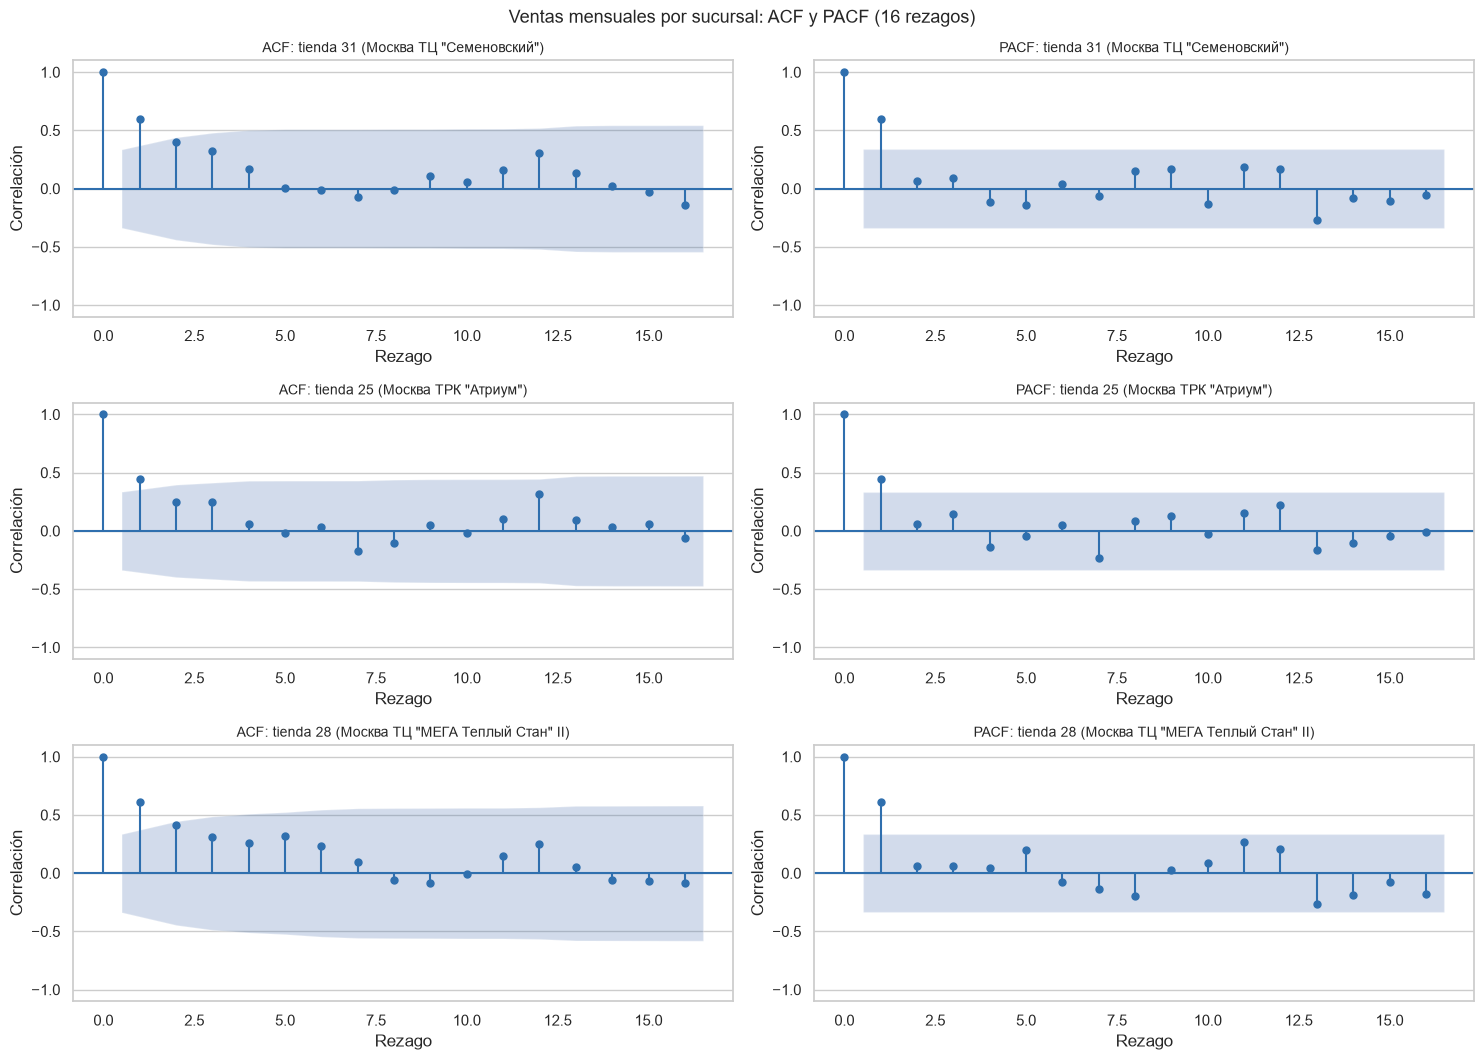

tienda 31 (Москва ТЦ "Семеновский"): ACF significativos [1] | PACF significativos [1] | ACF rezago 12 = 0.31
tienda 25 (Москва ТРК "Атриум"): ACF significativos [1] | PACF significativos [1] | ACF rezago 12 = 0.31
tienda 28 (Москва ТЦ "МЕГА Теплый Стан" II): ACF significativos [1] | PACF significativos [1] | ACF rezago 12 = 0.25


In [48]:
series_tiendas = {f"tienda {s} ({nombres_tienda[s]})": serie_mensual_completa(ventas[ventas["shop_id"] == s])
                  for s in sel_tiendas.index}
graficar_acf_pacf(series_tiendas, LAGS_MENSUAL, "Ventas mensuales por sucursal: ACF y PACF (16 rezagos)")
for nombre, serie in series_tiendas.items():
    sig_acf, sig_pacf, v_acf, _ = rezagos_significativos(serie, LAGS_MENSUAL)
    print(f"{nombre}: ACF significativos {sig_acf} | PACF significativos {sig_pacf} | ACF rezago 12 = {v_acf[12]:.2f}")

**Interpretación por sucursal:** las tres tiendas repiten el patrón de la serie total. La ACF es significativa en el rezago 1 (alrededor de 0.45 a 0.6) y decae gradualmente, y la PACF solo es significativa en el rezago 1. En las tres se observa un repunte de la ACF en el rezago 12 (0.31, 0.31 y 0.25) que, igual que en la serie total, refleja el pico de diciembre de cada año, pero queda dentro de la banda de confianza. Para el modelo, el valor del mes anterior de cada tienda es el predictor más claro, y el mismo mes del año anterior aporta una señal estacional débil.

#### Series por producto

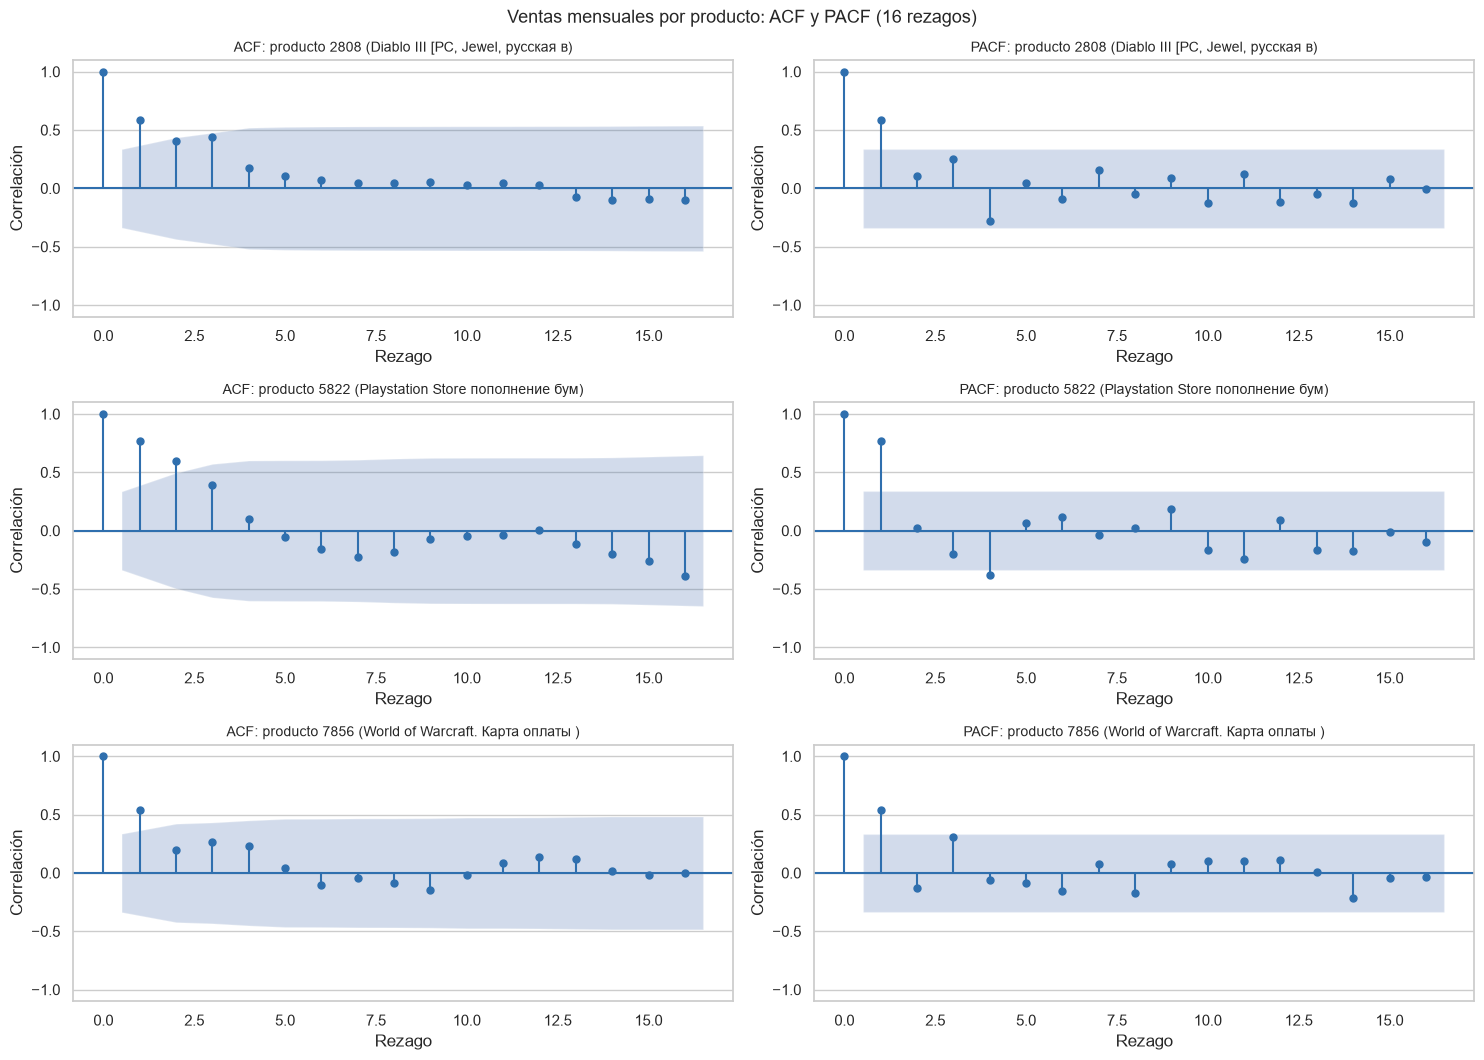

producto 2808 (Diablo III [PC, Jewel, русская в): ACF significativos [1] | PACF significativos [1] | ACF rezago 12 = 0.03
producto 5822 (Playstation Store пополнение бум): ACF significativos [1, 2] | PACF significativos [1, 4] | ACF rezago 12 = 0.00
producto 7856 (World of Warcraft. Карта оплаты ): ACF significativos [1] | PACF significativos [1] | ACF rezago 12 = 0.13


In [49]:
series_productos = {f"producto {i} ({nombres_item[i][:32]})": serie_mensual_completa(ventas[ventas["item_id"] == i])
                    for i in sel_productos.index}
graficar_acf_pacf(series_productos, LAGS_MENSUAL, "Ventas mensuales por producto: ACF y PACF (16 rezagos)")
for nombre, serie in series_productos.items():
    sig_acf, sig_pacf, v_acf, _ = rezagos_significativos(serie, LAGS_MENSUAL)
    print(f"{nombre}: ACF significativos {sig_acf} | PACF significativos {sig_pacf} | ACF rezago 12 = {v_acf[12]:.2f}")

**Interpretación por producto:** los tres productos muestran una dependencia de corto plazo: ACF significativa en el rezago 1 (y en el 2 para la tarjeta de PlayStation Store) y PACF con un pico dominante en el rezago 1, es decir, un comportamiento tipo AR(1). La tarjeta de PlayStation Store tiene además un valor negativo significativo en el rezago 4 de la PACF y una ACF que se vuelve negativa en los rezagos largos, reflejo de un nivel de ventas que primero sube y luego baja a lo largo del periodo. **Ninguno de los tres productos muestra estacionalidad anual**: la ACF en el rezago 12 es prácticamente cero (entre 0.00 y 0.13). Esto es razonable porque son productos de compra continua (un juego de catálogo y tarjetas de recarga), cuya demanda depende más de su ciclo de vida que de la temporada.

#### Series por sucursal-producto

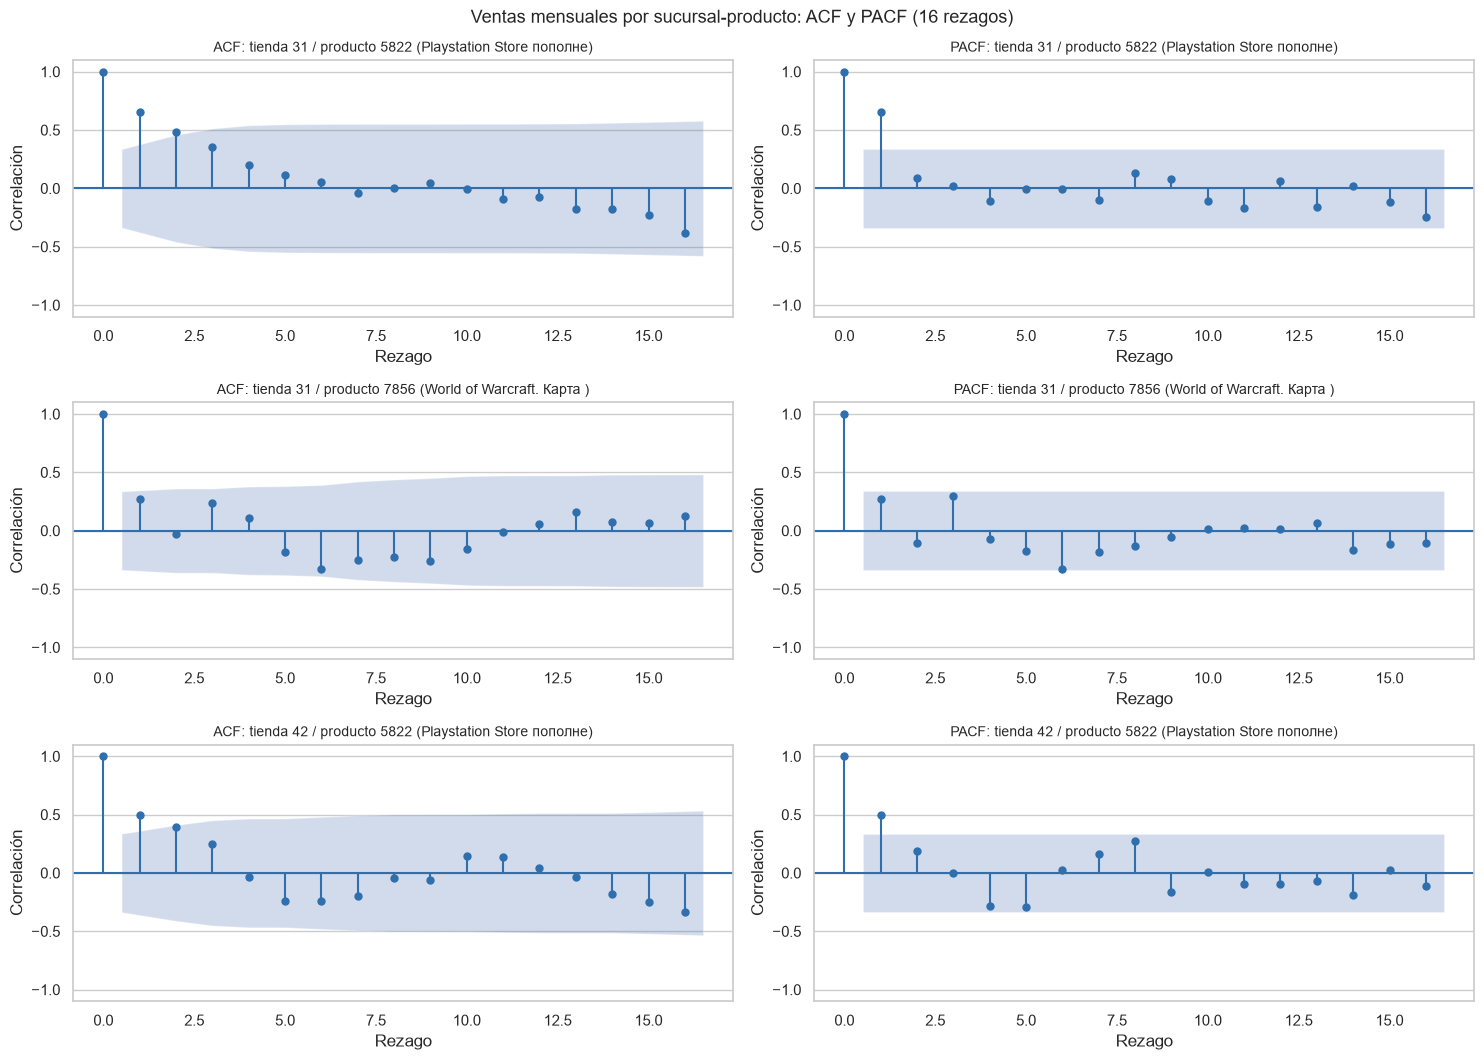

tienda 31 / producto 5822 (Playstation Store пополне): ACF significativos [1, 2] | PACF significativos [1] | ACF rezago 12 = -0.08
tienda 31 / producto 7856 (World of Warcraft. Карта ): ACF significativos [] | PACF significativos [] | ACF rezago 12 = 0.06
tienda 42 / producto 5822 (Playstation Store пополне): ACF significativos [1] | PACF significativos [1] | ACF rezago 12 = 0.04


In [50]:
series_pares = {f"tienda {s} / producto {i} ({nombres_item[i][:25]})":
                serie_mensual_completa(ventas[(ventas["shop_id"] == s) & (ventas["item_id"] == i)])
                for s, i in sel_pares.index}
graficar_acf_pacf(series_pares, LAGS_MENSUAL, "Ventas mensuales por sucursal-producto: ACF y PACF (16 rezagos)")
for nombre, serie in series_pares.items():
    sig_acf, sig_pacf, v_acf, _ = rezagos_significativos(serie, LAGS_MENSUAL)
    print(f"{nombre}: ACF significativos {sig_acf} | PACF significativos {sig_pacf} | ACF rezago 12 = {v_acf[12]:.2f}")

**Interpretación por sucursal-producto:** al bajar al nivel de par las series son más ruidosas. La tarjeta de PlayStation Store en las tiendas 31 y 42 conserva la dependencia de corto plazo (ACF significativa en el rezago 1, y en el 2 para la tienda 31, y PACF significativa solo en el rezago 1). En cambio, la tarjeta de World of Warcraft en la tienda 31 **no tiene ningún rezago significativo** ni en la ACF ni en la PACF: su serie mensual se comporta casi como ruido. Ninguno de los tres pares muestra estacionalidad en el rezago 12 (ACF entre -0.08 y 0.06). A este nivel, que es el que se debe predecir, la memoria de la serie es corta y la señal estacional se pierde.

### 9.b Interpretación

In [51]:
# Resumen de los rezagos significativos (intervalo de confianza del 95%) de todas las series analizadas
todas = {"Total mensual": serie_mensual, **series_tiendas, **series_productos, **series_pares}
filas = []
for nombre, serie in todas.items():
    sig_acf, sig_pacf, v_acf, _ = rezagos_significativos(serie, LAGS_MENSUAL)
    filas.append({"serie": nombre, "ACF rezagos significativos": sig_acf, "PACF rezagos significativos": sig_pacf,
                  "ACF rezago 1": round(float(v_acf[1]), 2), "ACF rezago 12": round(float(v_acf[12]), 2)})
sig_acf, sig_pacf, v_acf, _ = rezagos_significativos(diario["unidades"], LAGS_DIARIO)
filas.append({"serie": "Total diaria (56 rezagos)", "ACF rezagos significativos": f"{len(sig_acf)} de 56",
              "PACF rezagos significativos": f"{len(sig_pacf)} de 56",
              "ACF rezago 1": round(float(v_acf[1]), 2), "ACF rezago 12": f"rezago 7: {float(v_acf[7]):.2f}"})
pd.set_option("display.max_colwidth", 60)
display(pd.DataFrame(filas).set_index("serie"))

,ACF rezagos significativos,PACF rezagos significativos,ACF rezago 1,ACF rezago 12
serie,,,,
Total mensual,"[1, 2]",[1],0.64,0.26
"tienda 31 (Москва ТЦ ""Семеновский"")",[1],[1],0.60,0.31
"tienda 25 (Москва ТРК ""Атриум"")",[1],[1],0.44,0.31
"tienda 28 (Москва ТЦ ""МЕГА Теплый Стан"" II)",[1],[1],0.61,0.25
"producto 2808 (Diablo III [PC, Jewel, русская в)",[1],[1],0.58,0.03
producto 5822 (Playstation Store пополнение бум),"[1, 2]","[1, 4]",0.77,0.00
producto 7856 (World of Warcraft. Карта оплаты ),[1],[1],0.54,0.13
tienda 31 / producto 5822 (Playstation Store пополне),"[1, 2]",[1],0.66,-0.08
tienda 31 / producto 7856 (World of Warcraft. Карта ),[],[],0.27,0.06


**i. ¿Existen correlaciones significativas a diferentes rezagos?**

Sí, pero concentradas en los rezagos cortos. En todas las series mensuales, salvo un par sucursal-producto, la ACF y la PACF son significativas en el **rezago 1** (correlación de 0.44 a 0.77), y en algunas también en el rezago 2 de la ACF. La ACF decae de forma gradual y la PACF se corta después del rezago 1, lo que apunta a una estructura **autorregresiva de orden 1 (AR(1))**: las ventas de un mes se explican en buena parte por las del mes anterior, por lo que **un término AR** (o una variable de rezago de un mes en un modelo de machine learning) es el componente más importante. La lenta caída de la ACF también refleja la tendencia decreciente, lo que indica que las series no son estacionarias y que convendría diferenciarlas o modelar la tendencia. En la serie diaria la correlación es significativa en casi todos los rezagos (32 de 56 en la ACF), con la mayor fuerza en los múltiplos de 7. A nivel sucursal-producto la dependencia se debilita y puede desaparecer (tarjeta de World of Warcraft en la tienda 31).

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**

- **Semanal: sí, de forma clara.** La ACF diaria tiene picos que se repiten cada 7 días (rezagos 7, 14, 21, ..., 56) y la PACF tiene picos en los rezagos 6 y 7, lo que confirma el ciclo semanal de ventas más altas en fin de semana.
- **Anual: se insinúa, pero no es estadísticamente significativa.** En la serie total y en las tres sucursales, la ACF tiene un repunte positivo en el rezago 12 (entre 0.25 y 0.31) que coincide con el pico de diciembre, pero queda dentro de la banda de confianza. La razón es que 34 meses son menos de tres ciclos anuales y la tendencia decreciente domina la autocorrelación. En los productos y pares seleccionados, que son de compra continua, no hay rastro de estacionalidad (ACF en el rezago 12 cercana a cero).
- **Conclusión para el modelo:** la estacionalidad anual existe (secciones 6.b.ii y 8.d) pero las ACF mensuales no tienen datos suficientes para confirmarla por sí solas. Por eso conviene incluirla de forma explícita (mes del año o rezago de 12 meses) en lugar de esperar que un modelo autorregresivo la capture, y combinarla con rezagos cortos (1 y 2 meses), que son los que muestran la dependencia más fuerte.

## 10. Insights y conclusiones del EDA

### 10.a Variables que afectan directamente las ventas

A partir de los resultados de las secciones anteriores, las variables que afectan directamente las ventas mensuales de un par tienda-producto son:

| Variable | Evidencia en el EDA | Uso esperado en el forecasting |
|---|---|---|
| **Tiempo (tendencia)**: `date_block_num` | Tendencia decreciente de -1,944 unidades por mes; el componente de tendencia cae 31.3% (6.b.i). Solo 4 de 38 tiendas comparables crecieron en 2015 (7.b). | Índice de mes y niveles recientes, para que el pronóstico de noviembre de 2015 parta de un nivel menor que el de años anteriores. |
| **Mes del año (estacionalidad)** | Diciembre vende 41% a 53% más que el promedio de su año; noviembre supera a octubre en ambos años (+1.9% y +9.7%); abril a julio son los meses más débiles (6.b.ii). | Variable de mes del año o rezago de 12 meses, porque la ACF mensual por sí sola no la confirma (9.b). |
| **Ventas recientes (rezagos)** | ACF y PACF significativas en el rezago 1 en casi todas las series mensuales (0.44 a 0.77), con estructura tipo AR(1) (9.b). | Rezagos de 1 y 2 meses del propio par, de la tienda y del producto. |
| **Tienda**: `shop_id` | Venta por mes activo de 330 a 9,140 unidades (coeficiente de variación de 0.91); tendencias propias por tienda, con los canales en línea creciendo (+88.9% y +53.6%) mientras las físicas caen (7.b); aperturas y cierres (8.d). | Identificador de tienda o estadísticas históricas de la tienda (nivel y tendencia). |
| **Producto y categoría**: `item_id`, `item_category_id` | Ventas muy concentradas (el 10% de los productos reúne el 67.6% de las unidades) y 30.8% de productos con 10 unidades o menos (5.b.i). La categoría define la intensidad de la estacionalidad (consolas de 3.6 a 4.2 veces su promedio en diciembre) y la tendencia (servicios en alza, discos vírgenes en desaparición) (8.d). | Categoría y grupo de categoría como variables, además del historial del producto. |
| **Ciclo de vida y lanzamientos** | Un lanzamiento puede concentrar más de la mitad de las ventas de un día (GTA V para PC: 53.4%) (6.b.iii); los productos nuevos venden poco por su corta permanencia (7.a). | Antigüedad del producto (meses desde su primera venta) e indicador de producto nuevo. |
| **Precio**: `item_price` | Determina el peso en ingresos (las consolas son el 0.9% de las unidades y el 15.5% de los ingresos) y cambia dentro de un mismo producto por rebajas (miles de transacciones a más de 10 veces o menos de la décima parte de su mediana) (5.b.i y 7.c). | Precio promedio del par o del producto en el mes y sus cambios respecto a meses anteriores. |
| **Calendario y eventos** | Picos por Año Nuevo, 23 de febrero, 8 de marzo y la feria ИгроМир; el sábado vende 41% más que el promedio diario (6.b.iii y 6.b.iv). | A nivel mensual, el efecto semanal se diluye; los eventos se reflejan sobre todo a través del mes del año. |

Las devoluciones (`item_cnt_day` negativo) existen pero son marginales (0.25% de los registros), por lo que su efecto en el total mensual es pequeño.

### 10.b Patrones útiles para el modelo de forecasting e historial de los pares de test

In [52]:
# Historial de los pares, productos y tiendas de test en el train limpio
pares_train = set(zip(ventas["shop_id"], ventas["item_id"]))
items_train = set(ventas["item_id"])
tiendas_train = set(ventas["shop_id"])
pares_oct = set(zip(*[ventas.loc[ventas["date_block_num"] == 33, c] for c in ["shop_id", "item_id"]]))

t = test.copy()
t["par_con_historial"] = [par in pares_train for par in zip(t["shop_id"], t["item_id"])]
t["producto_con_historial"] = t["item_id"].isin(items_train)
t["tipo"] = np.select(
    [t["par_con_historial"], t["producto_con_historial"]],
    ["par con historial", "producto conocido, pero nuevo en esa tienda"],
    default="producto totalmente nuevo",
)
t["vendido_en_oct_2015"] = [par in pares_oct for par in zip(t["shop_id"], t["item_id"])]

print(f"Pares en test: {len(t):,} = {t['shop_id'].nunique()} tiendas x {t['item_id'].nunique():,} productos "
      f"(¿cuadrícula completa?: {t['shop_id'].nunique() * t['item_id'].nunique() == len(t)})")
print(f"Tiendas de test con historial en el train: {t['shop_id'].isin(tiendas_train).sum() // t['item_id'].nunique()} de {t['shop_id'].nunique()}")

resumen_test = t["tipo"].value_counts().to_frame("pares")
resumen_test["% de los pares"] = resumen_test["pares"] / len(t) * 100
display(resumen_test)

productos_test = t.drop_duplicates("item_id")
nuevos = productos_test[~productos_test["producto_con_historial"]]
print(f"Productos distintos en test: {len(productos_test):,} | con historial: {productos_test['producto_con_historial'].sum():,} "
      f"| totalmente nuevos: {len(nuevos):,} ({len(nuevos) / len(productos_test) * 100:.1f}%)")
print(f"Pares de test con ventas en octubre de 2015 (último mes): {t['vendido_en_oct_2015'].sum():,} "
      f"({t['vendido_en_oct_2015'].mean() * 100:.1f}%)")

# Categorías de los productos totalmente nuevos: la categoría es la única información disponible para ellos
cat_nuevos = (nuevos.merge(items[["item_id", "item_category_id"]], on="item_id")
              .groupby("item_category_id").size().sort_values(ascending=False).head(8).to_frame("productos_nuevos"))
cat_nuevos["item_category_name"] = nombres_cat.reindex(cat_nuevos.index)
print("Categorías con más productos totalmente nuevos:")
display(cat_nuevos)

Pares en test: 214,200 = 42 tiendas x 5,100 productos (¿cuadrícula completa?: True)
Tiendas de test con historial en el train: 42 de 42


,pares,% de los pares
tipo,,
par con historial,111471,52.04
"producto conocido, pero nuevo en esa tienda",87483,40.84
producto totalmente nuevo,15246,7.12


Productos distintos en test: 5,100 | con historial: 4,737 | totalmente nuevos: 363 (7.1%)
Pares de test con ventas en octubre de 2015 (último mes): 28,680 (13.4%)
Categorías con más productos totalmente nuevos:


,productos_nuevos,item_category_name
item_category_id,,
40,71,Кино - DVD
55,38,Музыка - CD локального производства
72,28,Подарки - Фигурки
31,25,Игры PC - Цифра
47,22,"Книги - Комиксы, манга"
58,21,Музыка - Винил
20,18,Игры - PS4
65,12,Подарки - Настольные игры (компактные)


**Interpretación del historial de los pares de test:**

- `test.csv` es una **cuadrícula completa** de 42 tiendas por 5,100 productos (214,200 pares). Todas las tiendas de test tienen historial en el train, gracias en parte a la unificación de tiendas de la sección 4.c.
- Solo el **52.04%** de los pares de test (111,471) tiene historial de ventas en el train para esa misma tienda y producto. Otro 40.84% (87,483 pares) corresponde a productos que sí se vendieron antes, pero nunca en esa tienda. El 7.12% restante (15,246 pares) corresponde a **363 productos totalmente nuevos** (7.1% de los productos de test), que no tienen ninguna venta en el train. Estos productos nuevos son sobre todo películas en DVD, CD de música, figuras, juegos digitales de PC y cómics, es decir, lanzamientos de las categorías con catálogos grandes.
- Solo el **13.4%** de los pares de test tuvo ventas en octubre de 2015, el último mes observado. La gran mayoría de los pares a predecir tendrá ventas de cero o cercanas a cero en noviembre de 2015.

**Patrones útiles para el modelo de forecasting:**

1. **Construir el train como cuadrícula mensual tienda x producto con ceros.** Como test es una cuadrícula completa y la mayoría de sus pares no vende en un mes dado, el modelo debe aprender también de los pares que no vendieron. Si solo se usan los meses con ventas, el modelo sobreestimará.
2. **Rezagos cortos y estacionales:** las ventas del mes anterior son el mejor predictor (AR(1), sección 9), y el mes del año o el rezago de 12 meses capturan que noviembre es superior a octubre.
3. **Información agregada para los pares sin historial:** para el 47.96% de los pares sin historial propio (productos nuevos en la tienda o totalmente nuevos), las variables disponibles son las de nivel superior: historial del producto en otras tiendas, de su categoría y de la tienda. Para los 363 productos nuevos, la categoría (y el comportamiento de los lanzamientos de esa categoría en su primer mes) es prácticamente la única información.
4. **Tendencia decreciente:** el nivel de ventas de 2015 es menor que el de 2013 y 2014, por lo que el modelo debe ponderar más los meses recientes que los promedios históricos.
5. **Validación temporal:** con la estructura mensual, lo adecuado es validar con el último mes disponible (octubre de 2015, bloque 33) entrenando con los meses anteriores, imitando la predicción de noviembre.

### 10.c Calidad y preparación del dataset para las siguientes etapas

**Calidad de los datos:** el dataset es de **buena calidad estructural**. No tiene valores nulos, las fechas se convierten sin errores, `date_block_num` es consistente con la fecha en el 100% de las filas, y el calendario diario de la cadena es continuo (1,034 días sin huecos). Los problemas encontrados fueron puntuales y afectan una fracción mínima de los datos:

| Problema | Registros | Tratamiento |
|---|---|---|
| Precio menor o igual a cero | 1 | Imputado con la mediana del producto en el mes (4.b) |
| Duplicados exactos | 6 | Eliminados (4.c) |
| Tiendas repetidas con distinto ID | 3 pares de tiendas | Unificadas hacia el ID de test (4.c) |
| Outliers extremos de precio y cantidad | 3 | Eliminados (7.c) |
| Devoluciones | 7,356 | Conservadas como ventas netas (4.b) |

En total, `sales_train` pasó de 2,935,849 a 2,935,840 filas.

**Limitaciones a tener en cuenta:**
- **Dispersión:** la mayoría de los pares tienda-producto vende de forma intermitente (solo 114 de 418,908 pares vendieron los 34 meses) y la venta diaria típica es de una unidad, por lo que la variable objetivo mensual tendrá muchísimos ceros y una cola larga.
- **Historia corta:** 34 meses son menos de tres ciclos anuales, suficiente para ver la estacionalidad pero no para confirmarla estadísticamente con la ACF (sección 9).
- **Cambios en la red de tiendas:** hay tiendas que abren y cierran, y algunas tiendas de test tienen muy poco historial (la tienda 36 solo vendió en octubre de 2015).
- **Artículos que no son mercancía:** la bolsa de compras, los servicios de entrega y las recargas tienen un comportamiento distinto al de los productos regulares y están presentes en test.
- **Cobertura de test:** casi la mitad de los pares de test (47.96%) no tiene historial propio y 363 productos son completamente nuevos.

**Preparación para el forecasting:** con las decisiones de limpieza aplicadas, el dataset está **listo para construir la tabla de modelado**. Los siguientes pasos concretos son: (1) agregar `sales_train` a nivel mensual por tienda y producto y completar la cuadrícula con ceros, agregando el mes 34 con los pares de test; (2) crear las variables identificadas en 10.a (rezagos de 1, 2 y 12 meses, mes del año, categoría y grupo, estadísticas de tienda y producto, antigüedad del producto y precio); y (3) validar de forma temporal con el bloque 33 antes de predecir el bloque 34.